# Data Mining Project — Information Operations (A.Y. 2026/2027)

This notebook contains the full analysis pipeline of the project:

* **Task 1 – Data Understanding and Preparation**: data semantics, data quality, distributions,
  correlations, and the construction of a **user (account) profile** with engineered features.
* **Task 2 – Clustering Analysis**: K-means, density-based clustering (DBSCAN), hierarchical clustering,
  a final comparison and an optional extra technique (X-means from `pyclustering` and Gaussian Mixture Models).

Throughout the notebook, information-operation accounts (**IO**, `is_control == False`) are always compared
with **control** accounts (`is_control == True`). Long-tailed variables (follower/following counts, number of
posts, ...) are analysed on a logarithmic scale.

**How to run.** Place `data.csv.zip` (or the extracted `data.csv`) in the project folder / `data/` folder and
run all cells. The raw CSV (~5 GB, ~8.7 M posts) does not fit comfortably in memory, so the first step converts it
chunk-by-chunk into a compact columnar Parquet file which is cached and reused by all the following cells.

## 0. Setup

In [1]:
# --- Standard library ---
import gc
import time
import warnings
import zipfile
from pathlib import Path

# --- Scientific stack ---
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Display options
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

# Plot style: one consistent palette for the two classes used in every comparison
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
CLASS_ORDER = ['IO', 'Control']
CLASS_PALETTE = {'IO': '#d62728', 'Control': '#1f77b4'}

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# --- Paths ---
PROJECT_DIR = Path('.').resolve()
DATA_DIR = PROJECT_DIR / 'data'
DATA_DIR.mkdir(exist_ok=True)
RAW_ZIP = PROJECT_DIR / 'data.csv.zip'
RAW_CSV = DATA_DIR / 'data.csv'
POSTS_PQ = DATA_DIR / 'posts_compact.parquet'      # compact post-level table (cache)
CLEAN_PQ = DATA_DIR / 'posts_clean.parquet'        # cleaned post-level table (cache)
PROFILES_PQ = DATA_DIR / 'user_profiles.parquet'   # account-level profiles (output of Task 1)

print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.1.1 | numpy 2.5.5


In [2]:
# Extract the raw CSV from the ZIP archive if it is not already available.
if not RAW_CSV.exists():
    if not RAW_ZIP.exists():
        raise FileNotFoundError('Put data.csv.zip in the project folder (or data.csv in ./data).')
    with zipfile.ZipFile(RAW_ZIP) as zf:
        zf.extract('data.csv', DATA_DIR)  # skip the __MACOSX metadata entry
print(f'Raw CSV: {RAW_CSV}  ({RAW_CSV.stat().st_size / 1e9:.2f} GB)')

Raw CSV: C:\Users\Diogo\Desktop\Data mining project\data\data.csv  (5.03 GB)


### 0.1 From the raw CSV to a compact Parquet table

The raw file is read in chunks of 500k rows **as plain strings** (no automatic type inference), so that no
information is lost before the quality assessment. For each chunk we:

* keep low-cardinality categorical fields as strings (`ioCountry`, `application_name`, `post_language`,
  `is_control`, `is_repost`);
* replace the anonymised 42-character identifiers by **64-bit hashes** (`*_h` columns, `0` = missing). Hashes are
  deterministic, so equal identifiers keep equal hashes across chunks and across columns (e.g. `accountid` vs
  `reposted_accountid`), which is everything we need for joins and duplicate detection;
* replace the heavy free-text fields (`post_text`, `account_profile_description`) by derived numeric
  descriptors (length, number of words) and by a hash of the normalised text (used to detect copy-pasted content);
* turn the list-like fields (`hashtags`, `urls`, `account_mentions`, stored as `"['a' 'b']"`) into counts;
* parse numbers and dates, recording for `follower_count` / `following_count` a **status code** describing why a
  value is not valid (missing, non-numeric token, negative, non-integer) and the offending token itself;
* compute a hash of the **whole raw row** to detect exact duplicate records.

In [3]:
LIST_ITEM_RE = r"'[^']*'|\"[^\"]*\""   # one quoted element of a stringified list
COUNT_STATUS = {0: 'valid', 1: 'missing', 2: 'non-numeric token', 3: 'negative', 4: 'non-integer'}


def hash_col(s: pd.Series) -> np.ndarray:
    """Deterministic 64-bit hash of a string column (missing values -> 0)."""
    h = pd.util.hash_pandas_object(s.fillna(''), index=False).to_numpy().copy()
    h[s.isna().to_numpy()] = 0
    return h


def parse_count(raw: pd.Series):
    """Parse a count column; returns (numeric value, status code, offending token)."""
    num = pd.to_numeric(raw, errors='coerce')
    status = np.select([raw.isna(), num.isna(), num < 0, (num % 1) != 0], [1, 2, 3, 4], default=0).astype('int8')
    bad_token = raw.where(status == 2)
    return num.astype('float64'), status, bad_token


SCHEMA = pa.schema([
    ('row_h', pa.uint64()), ('ioCountry', pa.string()), ('postid_h', pa.uint64()),
    ('text_len', pa.float32()), ('n_words', pa.float32()), ('text_h', pa.uint64()),
    ('application_name', pa.string()), ('post_language', pa.string()),
    ('reply_post_h', pa.uint64()), ('reply_acc_h', pa.uint64()),
    ('post_time', pa.timestamp('s')), ('accountid', pa.string()), ('acc_h', pa.uint64()),
    ('desc_len', pa.float32()),
    ('follower_count', pa.float64()), ('follower_status', pa.int8()), ('follower_bad_token', pa.string()),
    ('following_count', pa.float64()), ('following_status', pa.int8()), ('following_bad_token', pa.string()),
    ('account_creation_date', pa.timestamp('s')), ('is_repost_raw', pa.string()),
    ('rep_acc_h', pa.uint64()), ('rep_post_h', pa.uint64()),
    ('n_hashtags', pa.int16()), ('n_urls', pa.int16()), ('n_mentions', pa.int16()),
    ('is_control_raw', pa.string()),
])


def transform_chunk(ch: pd.DataFrame) -> pd.DataFrame:
    """Turn one raw chunk (all strings) into the compact representation described above."""
    out = pd.DataFrame(index=ch.index)
    out['row_h'] = pd.util.hash_pandas_object(ch, index=False).to_numpy()
    out['ioCountry'] = ch['ioCountry']
    out['postid_h'] = hash_col(ch['postid'])
    txt = ch['post_text']
    out['text_len'] = txt.str.len().astype('float32')
    out['n_words'] = txt.str.count(r'\S+').astype('float32')
    # Normalised text (lower case, collapsed white space) -> hash used to find identical contents
    out['text_h'] = hash_col(txt.str.lower().str.replace(r'\s+', ' ', regex=True).str.strip())
    out['application_name'] = ch['application_name']
    out['post_language'] = ch['post_language']
    out['reply_post_h'] = hash_col(ch['in_reply_to_postid'])
    out['reply_acc_h'] = hash_col(ch['in_reply_to_accountid'])
    out['post_time'] = pd.to_datetime(ch['post_time'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
    out['accountid'] = ch['accountid']
    out['acc_h'] = hash_col(ch['accountid'])
    out['desc_len'] = ch['account_profile_description'].str.len().astype('float32')
    for col, short in [('follower_count', 'follower'), ('following_count', 'following')]:
        num, status, bad = parse_count(ch[col])
        out[col], out[f'{short}_status'], out[f'{short}_bad_token'] = num, status, bad
    out['account_creation_date'] = pd.to_datetime(ch['account_creation_date'], format='%Y-%m-%d', errors='coerce')
    out['is_repost_raw'] = ch['is_repost']
    out['rep_acc_h'] = hash_col(ch['reposted_accountid'])
    out['rep_post_h'] = hash_col(ch['reposted_postid'])
    out['n_hashtags'] = ch['hashtags'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['n_urls'] = ch['urls'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['n_mentions'] = ch['account_mentions'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['is_control_raw'] = ch['is_control']
    return out


if not POSTS_PQ.exists():
    t0 = time.time()
    writer = pq.ParquetWriter(POSTS_PQ, SCHEMA, compression='zstd')
    reader = pd.read_csv(RAW_CSV, dtype=str, keep_default_na=False, na_values=[''], chunksize=500_000)
    for i, chunk in enumerate(reader):
        table = pa.Table.from_pandas(transform_chunk(chunk), preserve_index=False).cast(SCHEMA)
        writer.write_table(table)
        print(f'chunk {i:2d}: {(i + 1) * 500_000:>10,d} rows read  ({time.time() - t0:5.0f}s)')
    writer.close()
    del reader, chunk, table
    gc.collect()
print(f'Compact table: {POSTS_PQ.name}  ({POSTS_PQ.stat().st_size / 1e6:.0f} MB, '
      f'{pq.ParquetFile(POSTS_PQ).metadata.num_rows:,} rows)')

chunk  0:    500,000 rows read  (   12s)


chunk  1:  1,000,000 rows read  (   25s)


chunk  2:  1,500,000 rows read  (   37s)


chunk  3:  2,000,000 rows read  (   48s)


chunk  4:  2,500,000 rows read  (   60s)


chunk  5:  3,000,000 rows read  (   71s)


... (8 outputs left out)

chunk 14:  7,500,000 rows read  (  171s)


chunk 15:  8,000,000 rows read  (  183s)


chunk 16:  8,500,000 rows read  (  198s)


chunk 17:  9,000,000 rows read  (  204s)
Compact table: posts_compact.parquet  (381 MB, 8,714,356 rows)


In [4]:
def load_posts(columns, path=POSTS_PQ):
    """Load a subset of columns; repeated strings are loaded as pandas categoricals to save memory."""
    cat_cols = [c for c in ['ioCountry', 'application_name', 'post_language', 'accountid',
                            'is_repost_raw', 'is_control_raw'] if c in columns]
    return pq.read_table(path, columns=columns, read_dictionary=cat_cols).to_pandas()


# A small raw sample (first rows of the CSV) is used only to show what the original records look like.
raw_sample = pd.read_csv(RAW_CSV, nrows=5, dtype=str)
display(raw_sample.T.apply(lambda s: s.str.slice(0, 60)))

,0,1,2,3,4
ioCountry,ecuador,ecuador,ecuador,ecuador,ecuador
postid,0bafe020a260495bee38b98fde83668d924454019b,608fba51f2460c7f1ca527dfc48de2bc858d4ad201,514b2c38b26e240cac85382be74ed7d61a02468ac1,e82a816068e88387d19430348f0420b040e0d11b4e,13ed6aaeec4fffaf840f1c42ff88f5ab2cb324be64
post_text,Vamos a cambiar la forma de hacer comunicación...,"Damos servicio de manejo de prensa, elaboració...",@db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...,"Mario, debemos denuciar que en los poderes pub...",Tambien debemos estar claro que la oposición e...
application_name,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224
post_language,NaN,NaN,NaN,NaN,NaN
in_reply_to_postid,NaN,NaN,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464,NaN,NaN
in_reply_to_accountid,NaN,NaN,db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302,NaN,NaN
post_time,2010-03-13 02:52:00,2010-03-13 03:08:00,2010-03-13 15:26:00,2010-03-13 15:32:00,2010-03-13 15:35:00
accountid,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,2c6c0ef5f445760177b016e33b36809bde3c7ac241,2c6c0ef5f445760177b016e33b36809bde3c7ac241,2c6c0ef5f445760177b016e33b36809bde3c7ac241
account_profile_description,"#Periodismo, #RelacionesPúblicas, #Comunicac...","#Periodismo, #RelacionesPúblicas, #Comunicac...",NaN,NaN,NaN


---
# Task 1 – Data Understanding and Preparation

## 1.1 Data semantics

Each record of the dataset is a **post** (a tweet-like message). Some fields describe the post itself, others
describe the **account** that published it and are simply repeated on every post of that account (they are a
snapshot taken at collection time). All identifiers (posts, accounts, applications, URLs, mentioned accounts)
are anonymised with 42-character hexadecimal hashes.

| # | Variable | Level | Type | Meaning / role in the analysis |
|---|---|---|---|---|
| 1 | `ioCountry` | account | categorical (nominal) | Information operation (country + release) the record belongs to. Control accounts are matched to the same operation (similar topics and time window). |
| 2 | `postid` | post | identifier | Anonymised post id; expected to be unique (used for duplicate detection). |
| 3 | `post_text` | post | free text | Content of the post (URLs and @-mentions already anonymised). Used through derived descriptors (length, number of words, duplicated content). |
| 4 | `application_name` | post | categorical (nominal, hashed) | Client used to publish (web, mobile apps, schedulers, bots...). |
| 5 | `post_language` | post | categorical (nominal) | Language label (ISO-639-1 code, `und` = undetermined). |
| 6 | `in_reply_to_postid` | post | identifier | Post being replied to; missing when the post is not a reply (*structural* missingness). |
| 7 | `in_reply_to_accountid` | post | identifier | Author of the post being replied to. |
| 8 | `post_time` | post | temporal (interval scale) | Publication timestamp (minute/second resolution). |
| 9 | `accountid` | post → account | identifier | Author of the post; **key of the user profile** built in Section 1.5. |
| 10 | `account_profile_description` | account | free text | Biography of the account (optional). Used through its length / presence. |
| 11 | `follower_count` | account | numerical, discrete (ratio scale) | Number of followers (snapshot). Long-tailed → log scale. |
| 12 | `following_count` | account | numerical, discrete (ratio scale) | Number of followed accounts (snapshot). Long-tailed → log scale. |
| 13 | `account_creation_date` | account | temporal (date) | Creation date of the account. |
| 14 | `is_repost` | post | binary | Whether the post is a repost (retweet) of another post. |
| 15 | `reposted_accountid` | post | identifier | Author of the original post (only for reposts). |
| 16 | `reposted_postid` | post | identifier | Original post (only for reposts). |
| 17 | `hashtags` | post | list of strings | Hashtags contained in the post (stored as a stringified list). Used as counts. |
| 18 | `urls` | post | list of strings | URLs contained in the post (anonymised). Used as counts. |
| 19 | `account_mentions` | post | list of identifiers | Accounts mentioned in the post. Used as counts. |
| 20 | `is_control` | account | binary (class label) | `True` = control post, `False` = information-operation post. **Never used as a clustering input**, only for evaluation and comparisons. |

In [5]:
# Load the columns needed for a first overview (categoricals are dictionary-encoded -> low memory footprint).
posts = load_posts(['ioCountry', 'accountid', 'is_control_raw', 'is_repost_raw', 'application_name',
                    'post_language', 'post_time', 'account_creation_date'])
print(f'Posts: {len(posts):,}   |   distinct accounts: {posts["accountid"].nunique():,}')
print(f'Distinct application_name values: {posts["application_name"].nunique():,}')
print(f'Distinct post_language values: {posts["post_language"].nunique():,} (+ missing)')
print(f'post_time range: {posts["post_time"].min()}  ->  {posts["post_time"].max()}')
print(f'account_creation_date range: {posts["account_creation_date"].min().date()}  ->  '
      f'{posts["account_creation_date"].max().date()}')

overview = (posts.groupby(['ioCountry', 'is_control_raw'], observed=True)
            .agg(posts=('accountid', 'size'), accounts=('accountid', 'nunique'))
            .unstack('is_control_raw').fillna(0).astype(int))
display(overview)

Posts: 8,714,356   |   distinct accounts: 85,156
Distinct application_name values: 3,728
Distinct post_language values: 70 (+ missing)
post_time range: 2008-04-30 10:35:00  ->  2019-07-30 23:59:56


account_creation_date range: 2006-07-26  ->  2019-07-12


posts                      accounts                   
is_control_raw    False     True is_control?    False   True is_control?
ioCountry                                                               
ecuador          700274   770338         207      787  21138         174
iran_1          1122977   199873         173      660   5015          81
iran_4           254797   306822          64     2519   7612          56
russia_1        1826432  1823841         455     3293  31299         407
uae             1325597   382293         213     3658  10545         195

The table above already reveals that the class label contains an **invalid value** (`is_control?`), handled in
Section 1.2. The dataset covers five operations; Russia is the largest (≈42% of the posts) and, in terms of
posts, IO and control records are not balanced in the same way across operations (e.g. `iran_1` and `uae` are
dominated by IO posts, `russia_1` and `ecuador` are roughly balanced). Comparisons between IO and control must
therefore be made **within each operation** as well as globally.

## 1.2 Data quality

We assess (i) missing values, (ii) syntactic errors (values that cannot be parsed), (iii) duplicated records,
(iv) semantic inconsistencies between fields and (v) outliers. Each problem is first quantified and then a
cleaning rule is chosen.

### 1.2.1 Missing values

In [6]:
miss_cols = ['post_language', 'text_len', 'desc_len', 'follower_status', 'following_status',
             'reply_post_h', 'reply_acc_h', 'rep_acc_h', 'rep_post_h', 'is_repost_raw', 'is_control_raw']
mq = load_posts(miss_cols)
missing = pd.DataFrame({
    'ioCountry / postid / accountid / post_time / dates': 0,  # never missing (verified while parsing)
    'post_text': mq['text_len'].isna(),
    'post_language': mq['post_language'].isna(),
    'account_profile_description': mq['desc_len'].isna(),
    'follower_count': mq['follower_status'].eq(1),
    'following_count': mq['following_status'].eq(1),
    'in_reply_to_postid': mq['reply_post_h'].eq(0),
    'in_reply_to_accountid': mq['reply_acc_h'].eq(0),
    'reposted_accountid': mq['rep_acc_h'].eq(0),
    'reposted_postid': mq['rep_post_h'].eq(0),
})
miss_by_class = missing.groupby(mq['is_control_raw'].astype(str)).mean().T * 100
miss_by_class['overall %'] = missing.mean() * 100
miss_by_class['missing count'] = missing.sum()
display(miss_by_class.rename(columns={'False': 'IO %', 'True': 'Control %'})
        .drop(columns='is_control?', errors='ignore').round(3))

is_control_raw,IO %,Control %,overall %,missing count
ioCountry / postid / accountid / post_time / dates,0.0000,0.0000,0.0000,0
post_text,0.0000,0.0000,0.0000,3
post_language,1.9830,0.0000,1.1900,103743
account_profile_description,17.8930,21.0690,19.1630,1669919
follower_count,0.0150,0.0160,0.0150,1318
following_count,0.0140,0.0140,0.0140,1192
in_reply_to_postid,88.5940,91.6860,89.8300,7828114
in_reply_to_accountid,88.7240,91.8120,89.9580,7839269
reposted_accountid,57.1190,60.8980,58.6290,5109181
reposted_postid,57.1190,60.8980,58.6290,5109181


* The reply and repost identifiers are missing **by design** (structural missingness): a value exists only when
  the post is a reply or a repost. They are therefore not data errors but encode the post type.
* `account_profile_description` is missing for a substantial share of posts – an empty biography is itself a
  behavioural signal (we turn it into the `has_description` feature).
* `post_language` is missing for ~1% of posts: we map it to an explicit `unknown` category.
* `post_text` is missing for only a handful of posts; `follower_count`/`following_count` are missing for ~1.3k
  posts each (repaired at account level, see below).

### 1.2.2 Syntactic errors in the class label and in the numeric fields

In [7]:
print('is_control raw values:'); display(mq['is_control_raw'].value_counts().to_frame('posts'))
print('is_repost raw values:'); display(mq['is_repost_raw'].value_counts().to_frame('posts'))
del mq, missing
gc.collect()

cq = load_posts(['follower_status', 'follower_bad_token', 'following_status', 'following_bad_token'])
status_tab = pd.DataFrame({
    'follower_count': cq['follower_status'].map(COUNT_STATUS).value_counts(),
    'following_count': cq['following_status'].map(COUNT_STATUS).value_counts()}).fillna(0).astype(int)
display(status_tab)
tokens = pd.concat([cq['follower_bad_token'].dropna(), cq['following_bad_token'].dropna()]).value_counts()
print('Non-numeric tokens found in follower_count / following_count:')
display(tokens.to_frame('occurrences').T)
del cq
gc.collect()

is_control raw values:


,posts
is_control_raw,
False,5230077
True,3483167
is_control?,1112


is_repost raw values:


,posts
is_repost_raw,
False,5109181
True,3605175


,follower_count,following_count
valid,8709796,8709975
non-numeric token,2265,2160
missing,1318,1192
negative,977,1029


Non-numeric tokens found in follower_count / following_count:


,unknown,NaN-ish,error,none,many,12abc,??42,4O00,ten,"1,2,3"
occurrences,517,516,508,499,480,414,384,377,370,360


0

* The class label contains **1,112 posts with the invalid value `is_control?`** (≈0.01%).
* `follower_count` and `following_count` contain **non-numeric tokens** (`error`, `unknown`, `NaN-ish`, `ten`,
  `4O00` with a letter O, `1,2,3`, `??42`, ...) and **negative values** (e.g. −292,406 for an account whose valid
  value is 1,285 on all its other posts). No non-integer value was found.
* `is_repost` contains only valid booleans.

Since `is_control`, `follower_count` and `following_count` are **account-level** attributes repeated on every post,
these errors can be repaired by looking at the other posts of the same account (Section 1.2.5).

### 1.2.3 Duplicated records

In [8]:
keys = load_posts(['row_h', 'postid_h', 'ioCountry', 'acc_h', 'text_h', 'post_time', 'is_control_raw'])
exact_dup = keys['row_h'].duplicated()
print(f'Exact duplicated rows (identical in every field): {exact_dup.sum():,} '
      f'(rows involved: {keys["row_h"].duplicated(keep=False).sum():,})')

k1 = keys[~exact_dup]
id_dup = k1['postid_h'].duplicated(keep=False)
grp = k1[id_dup].groupby('postid_h').agg(n_rows=('acc_h', 'size'), n_operations=('ioCountry', 'nunique'),
                                         n_accounts=('acc_h', 'nunique'), n_texts=('text_h', 'nunique'),
                                         label=('is_control_raw', 'first'))
print(f'Remaining posts sharing a postid with another record: {id_dup.sum():,} in {len(grp):,} groups')
print('Label of the duplicated postids:', grp['label'].astype(str).value_counts().to_dict())
display(grp.assign(same_operation=grp['n_operations'].eq(1), same_account=grp['n_accounts'].eq(1),
                   same_text=grp['n_texts'].eq(1))
        [['same_operation', 'same_account', 'same_text']].value_counts().to_frame('groups'))

acc_ops = k1.groupby('acc_h')['ioCountry'].nunique()
print(f'Accounts appearing in more than one operation: {(acc_ops > 1).sum():,} '
      f'(distribution: {acc_ops[acc_ops > 1].value_counts().to_dict()})')

Exact duplicated rows (identical in every field): 1,579 (rows involved: 3,158)


Remaining posts sharing a postid with another record: 42,461 in 21,131 groups
Label of the duplicated postids: {'True': 21129, 'is_control?': 1, 'False': 1}


groups
same_operation same_account same_text        
False          True         True        20827
True           False        True          149
                            False          74
               True         False          70
False          False        True            7
                            False           4

Accounts appearing in more than one operation: 1,295 (distribution: {2: 1228, 3: 60, 4: 7})


* 1,579 rows are **exact copies** of other rows → removed.
* About 21k post identifiers appear more than once. Almost all of them (≈98%) are the **same control post
  included in the control sample of two or more operations** (same account, same text, same timestamp, different
  `ioCountry`); the account-level snapshot fields can differ slightly (e.g. 2,208 vs 2,209 followers) because
  the operations were collected at different moments. A few hundred groups share the id but differ in account or
  text (identifier collisions / corrupted records). Because a post must be counted once in an account profile,
  we keep only the **first record of every `postid`**.
* Consequently, 1,295 **control** accounts appear in 2–4 operations. For account-level analyses each account is
  assigned to its **main operation** (the one with most of its posts).

### 1.2.4 Semantic inconsistencies

In [9]:
inc = load_posts(['acc_h', 'is_control_raw', 'post_time', 'account_creation_date', 'reply_post_h',
                  'reply_acc_h', 'is_repost_raw', 'rep_acc_h', 'rep_post_h', 'follower_count', 'follower_status'])
inc = inc[~exact_dup.to_numpy()]
valid_lab = inc[inc['is_control_raw'].isin(['True', 'False'])]
labels_per_acc = valid_lab.groupby('acc_h')['is_control_raw'].nunique()
bad_lab_accs = inc.loc[~inc['is_control_raw'].isin(['True', 'False']), 'acc_h'].unique()
is_rep = inc['is_repost_raw'].eq('True')
checks = {
    'accounts with both True and False labels': int((labels_per_acc > 1).sum()),
    'accounts with an invalid label on some post': len(bad_lab_accs),
    '  ... of which have a valid label on other posts': int(np.isin(bad_lab_accs, labels_per_acc.index).sum()),
    'accounts with >1 creation date': int((inc.groupby('acc_h')['account_creation_date'].nunique() > 1).sum()),
    'accounts with >1 valid follower_count value': int(
        (inc[inc['follower_status'] == 0].groupby('acc_h')['follower_count'].nunique() > 1).sum()),
    'posts published before the account creation date': int((inc['post_time'] < inc['account_creation_date']).sum()),
    'replies with in_reply_to_postid but no in_reply_to_accountid':
        int(((inc['reply_post_h'] != 0) & (inc['reply_acc_h'] == 0)).sum()),
    'replies with in_reply_to_accountid but no in_reply_to_postid':
        int(((inc['reply_post_h'] == 0) & (inc['reply_acc_h'] != 0)).sum()),
    'reposts without reposted ids': int((is_rep & (inc['rep_acc_h'] == 0)).sum()),
    'non-reposts with reposted ids': int((~is_rep & (inc['rep_acc_h'] != 0)).sum()),
    'posts that are both reply and repost': int((is_rep & (inc['reply_post_h'] != 0)).sum()),
    'self-replies (reply to own account)': int(((inc['reply_acc_h'] == inc['acc_h']) & (inc['reply_acc_h'] != 0)).sum()),
    'self-reposts (repost of own post)': int(((inc['rep_acc_h'] == inc['acc_h']) & (inc['rep_acc_h'] != 0)).sum()),
}
display(pd.Series(checks, name='count').to_frame())
del inc, valid_lab, is_rep
gc.collect()

,count
accounts with both True and False labels,1
accounts with an invalid label on some post,913
... of which have a valid label on other posts,913
accounts with >1 creation date,0
accounts with >1 valid follower_count value,1605
posts published before the account creation date,0
replies with in_reply_to_postid but no in_reply_to_accountid,74608
replies with in_reply_to_accountid but no in_reply_to_postid,63456
reposts without reposted ids,0
non-reposts with reposted ids,0


0

* The class label is consistent at account level: every account with an `is_control?` post has a valid label on its
  other posts, and only one account has contradicting valid labels (resolved by majority).
* `account_creation_date` is constant per account and no post precedes the creation of its account.
* `follower_count` is a per-account snapshot: apart from the injected errors it is (almost) constant per account;
  the few accounts with more than one valid value are mostly the control accounts collected in several operations.
* Reply identifiers are sometimes only partially available (post id without account id or vice versa, ~0.8% of
  posts each). We define a post as a **reply** if *either* identifier is present.
* Repost fields are perfectly consistent with `is_repost`; no post is both a reply and a repost.
* Self-replies (threads) and self-reposts are legitimate behaviours, not errors (self-reposting is a known
  amplification tactic), so they are kept.

### 1.2.5 Cleaning

Cleaning rules applied to build the cleaned post-level table:

1. drop exact duplicate rows and keep the first record of every `postid`;
2. `is_control`: account-level majority of the valid labels (repairs all `is_control?` values);
3. `follower_count`, `following_count`: invalid values (missing, non-numeric, negative) are set to NaN and every
   post receives the **median of the valid values of its account**; the accounts without any valid value receive
   the median of the accounts of the same operation;
4. `post_language`: missing → explicit category `unknown`;
5. new boolean post-type flags: `is_reply` (any reply identifier present) and `is_repost`;
6. each account is assigned to its main operation (`account_ioCountry`).

In [10]:
n_raw = len(keys)
keep = (~exact_dup & ~keys['postid_h'].duplicated()).to_numpy()  # rule 1 (exact dups are also postid dups)
del keys, k1, grp, exact_dup, id_dup, acc_ops
gc.collect()

if not CLEAN_PQ.exists():
    cols =['ioCountry', 'accountid', 'acc_h', 'is_control_raw', 'post_time', 'account_creation_date',
            'application_name', 'post_language', 'is_repost_raw', 'reply_post_h', 'reply_acc_h', 'rep_acc_h',
            'text_len', 'n_words', 'text_h', 'n_hashtags', 'n_urls', 'n_mentions', 'desc_len',
            'follower_count', 'follower_status', 'following_count', 'following_status']
    clean = load_posts(cols)

    # Account-level attributes are computed on ALL records (before dropping duplicated postids), so that
    # accounts present in several operations are summarised with every snapshot available.
    lab_valid = clean['is_control_raw'].astype(str).map({'True': 1.0, 'False': 0.0})
    acc_label = lab_valid.groupby(clean['acc_h']).mean().round().astype(bool)          # rule 2 (majority)
    acc_attr = {}
    for col, st in [('follower_count', 'follower_status'), ('following_count', 'following_status')]:
        valid = clean[col].where(clean[st] == 0)
        acc_attr[col] = valid.groupby(clean['acc_h']).median()                           # rule 3
    acc_country = (clean.groupby(['acc_h', 'ioCountry'], observed=True).size()
                   .reset_index(name='n').sort_values('n', ascending=False)
                   .drop_duplicates('acc_h').set_index('acc_h')['ioCountry'])           # rule 6

    clean = clean[keep].reset_index(drop=True)
    clean['is_control'] = clean['acc_h'].map(acc_label).astype(bool)
    for col in ['follower_count', 'following_count']:
        clean[col] = clean['acc_h'].map(acc_attr[col])
    clean['account_ioCountry'] = clean['acc_h'].map(acc_country).astype(clean['ioCountry'].dtype)
    for col in ['follower_count', 'following_count']:  # accounts without any valid value -> operation median
        op_median = clean.drop_duplicates('acc_h').groupby('account_ioCountry', observed=True)[col].median()
        clean[col] = clean[col].fillna(clean['account_ioCountry'].map(op_median).astype(float))
    clean['post_language'] = clean['post_language'].cat.add_categories('unknown').fillna('unknown')   # rule 4
    clean['is_repost'] = clean['is_repost_raw'].astype(str).eq('True')                                # rule 5
    clean['is_reply'] = (clean['reply_post_h'] != 0) | (clean['reply_acc_h'] != 0)
    clean = clean.drop(columns=['is_control_raw', 'is_repost_raw', 'reply_post_h', 'follower_status',
                                'following_status'])
    clean.to_parquet(CLEAN_PQ, index=False, compression='zstd')
    del clean, acc_label, acc_attr, acc_country, lab_valid, valid
    gc.collect()
del keep

posts = pd.read_parquet(CLEAN_PQ)
posts['class'] = pd.Categorical(np.where(posts['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)
print(f'Cleaned posts: {len(posts):,} (removed {n_raw - len(posts):,} duplicated records) | '
      f'accounts: {posts["acc_h"].nunique():,}')
print(f'Memory footprint of the cleaned table: {posts.memory_usage(deep=True).sum() / 1e9:.2f} GB')
print('Remaining problems -> label NaN:', int(posts['is_control'].isna().sum()),
      '| follower/following NaN:', int(posts[['follower_count', 'following_count']].isna().sum().sum()),
      '| negative counts:', int((posts[['follower_count', 'following_count']] < 0).sum().sum()))

Cleaned posts: 8,691,447 (removed 22,909 duplicated records) | accounts: 85,155
Memory footprint of the cleaned table: 0.83 GB
Remaining problems -> label NaN: 0 | follower/following NaN: 0 | negative counts: 0


Notes on the cleaned table: `post_language` was missing **only for IO posts** (≈2% of them), which is itself a
hint of non-standard publishing tools. All label and count errors were repaired at account level, so no record
had to be discarded because of them; only duplicated records were removed.

### 1.2.6 Outliers

Outliers are searched with the inter-quartile-range rule (values outside $[Q_1 - 1.5\,IQR,\ Q_3 + 1.5\,IQR]$)
applied on the **log scale** $\log_{10}(1+x)$ for long-tailed counts, both at post level and at account level.

Accounts per class: {'Control': 74238, 'IO': 10917}


,max,outliers,outliers %,% of IO units,% of Control units
variable,,,,,
text_len (post),"2,582.0000",377105,4.3400,3.1900,6.0700
n_hashtags (post),40.0000,404266,4.6500,2.4500,7.9800
n_mentions (post),51.0000,114449,1.3200,0.8600,2.0000
n_urls (post),9.0000,564,0.0100,0.0000,0.0100
n_posts (account),"265,448.0000",227,0.2700,1.8600,0.0300
follower_count (account),"19,912,528.0000",3093,3.6300,8.6500,2.8900
following_count (account),"2,301,841.0000",6605,7.7600,6.5900,7.9300


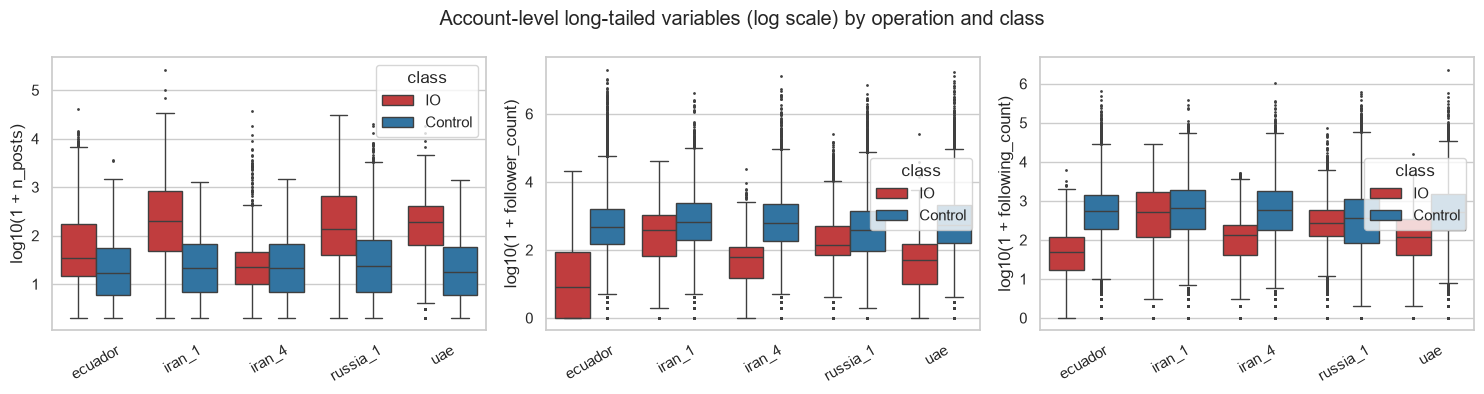

Top-5 most active accounts:


,ioCountry,class,n_posts,follower_count,following_count
acc_h,,,,,
15930036914788519034,iran_1,IO,265448,"8,012.0000","1,450.0000"
7656609485553353470,iran_1,IO,101956,"1,137.0000",219.0000
7218653399529539194,iran_1,IO,68808,"14,365.0000","15,104.0000"
2922584811867426777,ecuador,IO,40576,"3,618.0000","2,055.0000"
10410252467982132573,iran_4,IO,36990,"6,044.0000",651.0000


In [11]:
# Basic account-level table (one row per account), used for outlier detection and for the distributions.
acc = (posts.groupby('acc_h')
       .agg(n_posts=('post_time', 'size'), follower_count=('follower_count', 'first'),
            following_count=('following_count', 'first'), is_control=('is_control', 'first'),
            ioCountry=('account_ioCountry', 'first'), account_creation_date=('account_creation_date', 'first')))
acc['class'] = pd.Categorical(np.where(acc['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)
print('Accounts per class:', acc['class'].value_counts().to_dict())


def iqr_outliers(x: pd.Series, log=True) -> pd.Series:
    """Boolean mask of IQR outliers (computed on log10(1+x) when log=True)."""
    v = np.log10(1 + x) if log else x
    q1, q3 = v.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)


rows = []
for name, s, cls in [('text_len (post)', posts['text_len'].dropna(), posts.loc[posts['text_len'].notna(), 'class']),
                     ('n_hashtags (post)', posts['n_hashtags'], posts['class']),
                     ('n_mentions (post)', posts['n_mentions'], posts['class']),
                     ('n_urls (post)', posts['n_urls'], posts['class']),
                     ('n_posts (account)', acc['n_posts'], acc['class']),
                     ('follower_count (account)', acc['follower_count'], acc['class']),
                     ('following_count (account)', acc['following_count'], acc['class'])]:
    out = iqr_outliers(s)
    rows.append({'variable': name, 'max': s.max(), 'outliers': int(out.sum()), 'outliers %': 100 * out.mean(),
                 '% of IO units': 100 * out[cls == 'IO'].mean(), '% of Control units': 100 * out[cls == 'Control'].mean()})
display(pd.DataFrame(rows).set_index('variable').round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['n_posts', 'follower_count', 'following_count']):
    sns.boxplot(data=acc, x='ioCountry', y=np.log10(1 + acc[col]), hue='class', palette=CLASS_PALETTE,
                hue_order=CLASS_ORDER, ax=ax, fliersize=1)
    ax.set_ylabel(f'log10(1 + {col})')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Account-level long-tailed variables (log scale) by operation and class')
plt.tight_layout()
plt.show()
print('Top-5 most active accounts:')
display(acc.nlargest(5, 'n_posts')[['ioCountry', 'class', 'n_posts', 'follower_count', 'following_count']])

* Even on the log scale the activity distribution has a long right tail: a few **IO accounts publish tens of
  thousands of posts** (the most active `iran_1` account has >265k posts), while the typical account has a few
  dozen. Followers and following counts also span 6–7 orders of magnitude.
* These extreme values are **not errors** but genuine (and very informative) behaviours: hyper-active accounts are
  exactly what an information operation is expected to produce. They are therefore **kept**; their influence is
  controlled with logarithmic transformations and, for clustering, with robust scaling (Task 2).
* Post-level outliers (very long texts, posts with tens of hashtags/mentions) are rare and also plausible
  (anonymisation replaces every URL / mention with a 42-character hash, inflating text length), so they are kept.

## 1.3 Distributions and descriptive statistics

### 1.3.1 Volume and time

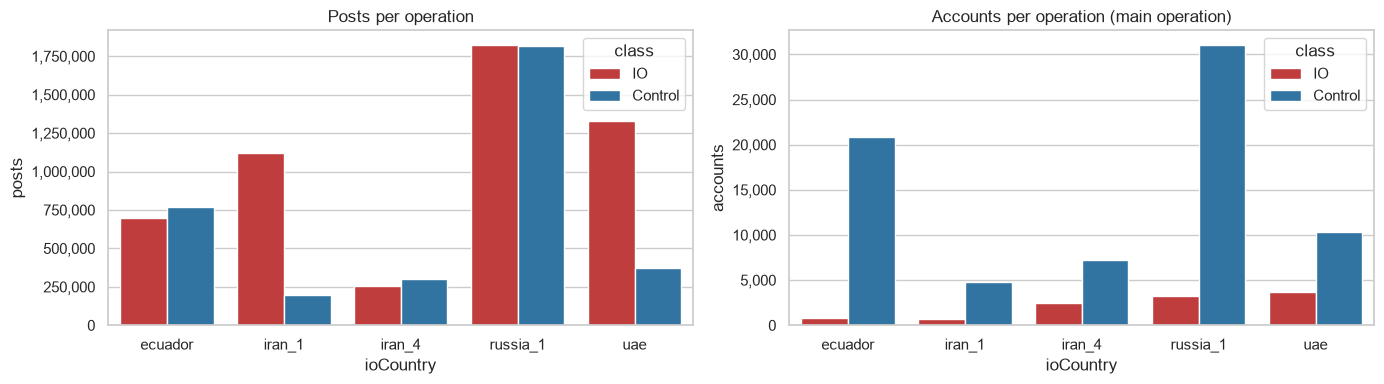

,count,mean,std,min,25%,50%,75%,90%,99%,max
class,,,,,,,,,,
IO,"10,917.0000",479.1000,"3,104.6000",1.0000,21.0000,88.0000,349.0000,"1,044.4000","5,434.4000","265,448.0000"
Control,"74,238.0000",46.6000,173.8000,1.0000,5.0000,19.0000,66.0000,99.0000,297.0000,"19,690.0000"


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vol = posts.groupby(['ioCountry', 'class'], observed=True).size().rename('posts').reset_index()
sns.barplot(data=vol, x='ioCountry', y='posts', hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER, ax=axes[0])
axes[0].set_title('Posts per operation')
accs = acc.groupby(['ioCountry', 'class'], observed=True).size().rename('accounts').reset_index()
sns.barplot(data=accs, x='ioCountry', y='accounts', hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER, ax=axes[1])
axes[1].set_title('Accounts per operation (main operation)')
for ax in axes:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.tight_layout()
plt.show()

ppa = acc.groupby('class', observed=True)['n_posts'].describe(percentiles=[.25, .5, .75, .9, .99])
display(ppa.round(1))

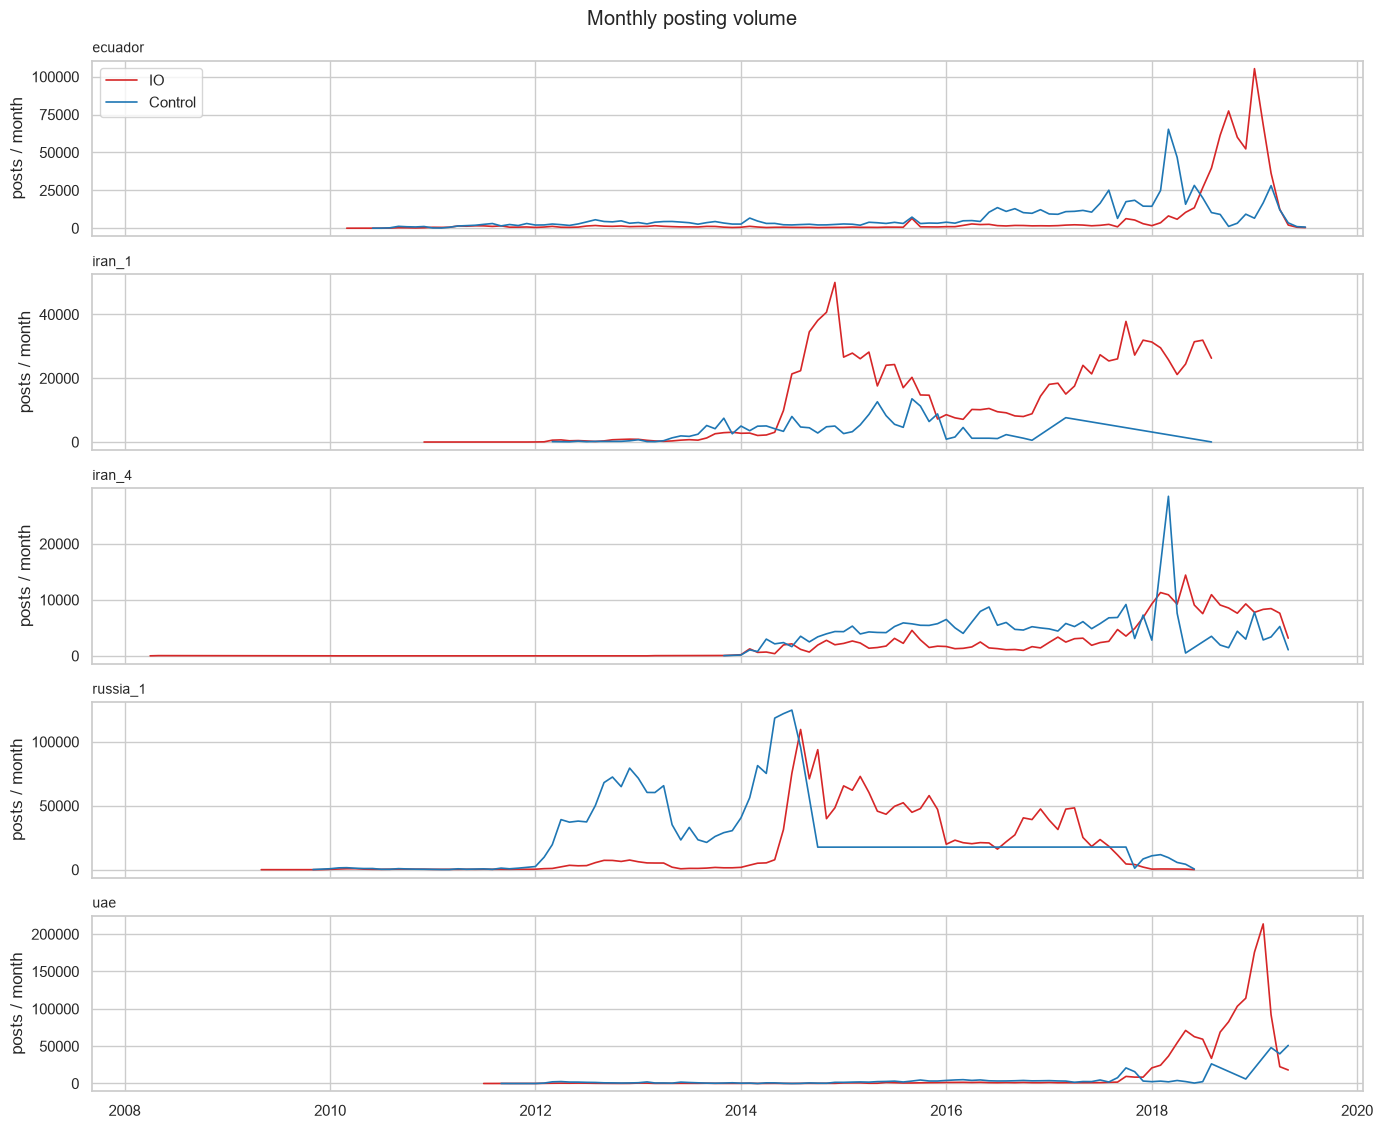

In [13]:
# Monthly number of posts per operation (IO vs control)
monthly = (posts.groupby([posts['ioCountry'], posts['class'], posts['post_time'].dt.to_period('M')], observed=True)
           .size().rename('posts').reset_index())
monthly['post_time'] = monthly['post_time'].dt.to_timestamp()
ops = sorted(posts['ioCountry'].cat.categories)
fig, axes = plt.subplots(len(ops), 1, figsize=(14, 2.3 * len(ops)), sharex=True)
for ax, op in zip(axes, ops):
    for cls in CLASS_ORDER:
        m = monthly[(monthly['ioCountry'] == op) & (monthly['class'] == cls)]
        ax.plot(m['post_time'], m['posts'], color=CLASS_PALETTE[cls], label=cls, lw=1.2)
    ax.set_title(op, loc='left', fontsize=10)
    ax.set_ylabel('posts / month')
axes[0].legend(loc='upper left')
fig.suptitle('Monthly posting volume')
plt.tight_layout()
plt.show()

The IO activity of each operation is concentrated in specific periods (campaign bursts): Russian IO posting peaks
in 2014–2017, Iran_1 in 2014–2015 and again in 2017–2018, while the UAE and Ecuador operations show very sharp
peaks in 2018–2019. Control posts cover the same time windows by construction, but with a different shape.

### 1.3.2 Post type, language and publishing client

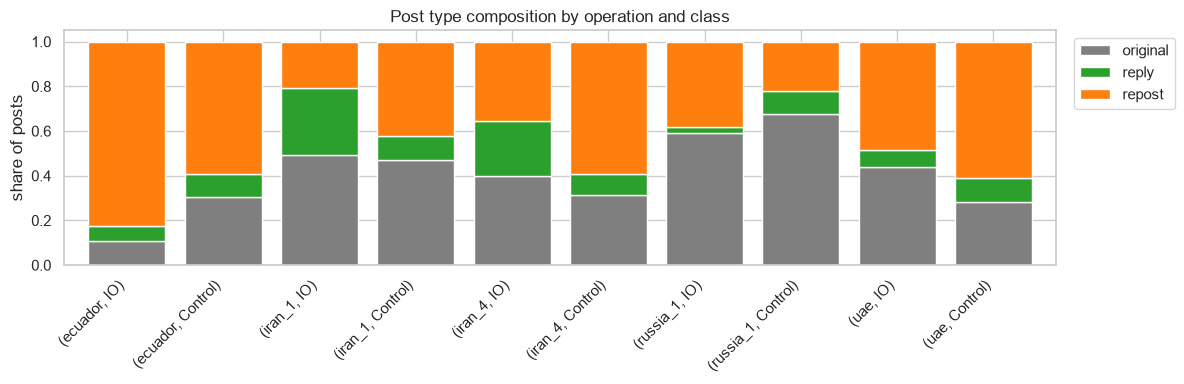

post_type          original   reply  repost
ioCountry class                            
ecuador   IO        10.9000  6.6000 82.5000
          Control   30.6000 10.1000 59.3000
iran_1    IO        49.1000 30.2000 20.7000
          Control   47.2000 10.8000 42.1000
iran_4    IO        39.9000 24.6000 35.5000
          Control   31.3000  9.6000 59.1000
russia_1  IO        59.1000  2.7000 38.2000
          Control   67.8000 10.0000 22.2000
uae       IO        43.9000  7.5000 48.6000
          Control   28.2000 10.5000 61.2000

In [14]:
posts['post_type'] = pd.Categorical(np.select([posts['is_repost'], posts['is_reply']], ['repost', 'reply'], 'original'),
                                    categories=['original', 'reply', 'repost'])
ptype = (posts.groupby(['ioCountry', 'class'], observed=True)['post_type'].value_counts(normalize=True)
         .unstack('post_type'))
ax = ptype.plot(kind='bar', stacked=True, figsize=(12, 4), color=['#7f7f7f', '#2ca02c', '#ff7f0e'], width=0.8)
ax.set_ylabel('share of posts')
ax.set_xlabel('')
ax.set_title('Post type composition by operation and class')
ax.legend(bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
display((ptype * 100).round(1))

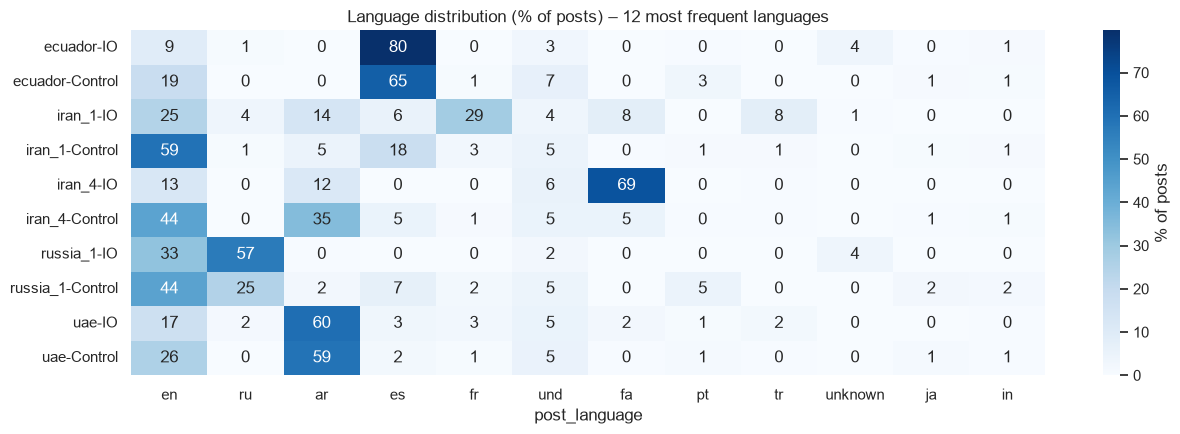

In [15]:
# Language: share of the 12 most frequent languages within every operation x class group
top_lang = posts['post_language'].value_counts().head(12).index
lang_share = (posts.groupby(['ioCountry', 'class'], observed=True)['post_language'].value_counts(normalize=True)
              .unstack('post_language')[top_lang] * 100)
plt.figure(figsize=(13, 4.5))
sns.heatmap(lang_share, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of posts'})
plt.title('Language distribution (% of posts) – 12 most frequent languages')
plt.ylabel('')
plt.tight_layout()
plt.show()

distinct apps  top-1 app share %  top-3 apps share %  entropy (bits)
ioCountry class                                                                        
ecuador   IO                  73            31.0700             90.3900          2.1800
          Control            759            39.0800             73.2300          3.5000
iran_1    IO                 124            62.2800             77.8800          2.2400
          Control            462            22.2200             52.6500          4.6500
iran_4    IO                  42            53.9500             94.5400          1.7700
          Control            455            28.5700             70.5100          3.7100
russia_1  IO                 257            28.7000             52.3400          4.0100
          Control           2341            18.6900             39.0300          5.5000
uae       IO                  71            35.8500             81.7600          2.4400
          Control            546            33.8600             76.3600          3.4200

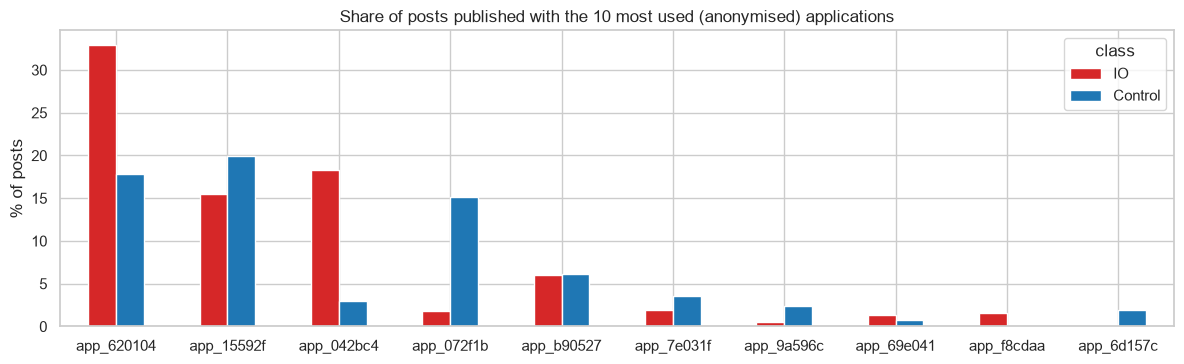

In [16]:
# Publishing client: concentration of the application_name distribution (applications are anonymised)
app_stats = []
for (op, cls), g in posts.groupby(['ioCountry', 'class'], observed=True):
    vc = g['application_name'].value_counts(normalize=True)
    vc = vc[vc > 0]
    app_stats.append({'ioCountry': op, 'class': cls, 'distinct apps': len(vc), 'top-1 app share %': 100 * vc.iloc[0],
                      'top-3 apps share %': 100 * vc.iloc[:3].sum(),
                      'entropy (bits)': -(vc * np.log2(vc)).sum()})
app_stats = pd.DataFrame(app_stats)
display(app_stats.set_index(['ioCountry', 'class']).round(2))

top_apps = posts['application_name'].value_counts().head(10).index
app_share = (posts.groupby('class', observed=True)['application_name'].value_counts(normalize=True)
             .unstack('application_name')[top_apps] * 100)
app_share.columns = [f'app_{c[:6]}' for c in app_share.columns]
ax = app_share.T.plot(kind='bar', figsize=(12, 3.8), color=[CLASS_PALETTE[c] for c in app_share.index])
ax.set_ylabel('% of posts')
ax.set_title('Share of posts published with the 10 most used (anonymised) applications')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

* **Post type**: IO and control accounts differ markedly in how they use reposts and replies, and the direction
  depends on the operation: Ecuador IO accounts mostly repost (82% vs 59% for controls), Russian IO accounts mostly
  publish original content (59%) and almost never reply (3%), while Iranian IO accounts reply much more than
  their controls (25–30% vs ~10%).
* **Language** follows the target audience of each operation (Spanish for Ecuador, Arabic for UAE, Persian for
  Iran_4, Russian/English for Russia). Iran_1 IO accounts are strikingly multilingual (French 29%, English 25%,
  Arabic 14%, Turkish 8%) compared with their mostly-English controls, and IO posts are the only ones with
  missing language labels.
* **Clients**: in every operation IO posts use far fewer distinct applications than control posts and are much
  more concentrated on the top ones (e.g. Iran_4: top-3 applications cover 95% of IO posts vs 71% of control
  posts; the entropy of the client distribution is 1.8–4.0 bits for IO vs 3.4–5.5 bits for controls) – consistent
  with centrally managed accounts using the same tools.

### 1.3.3 Temporal habits and content descriptors

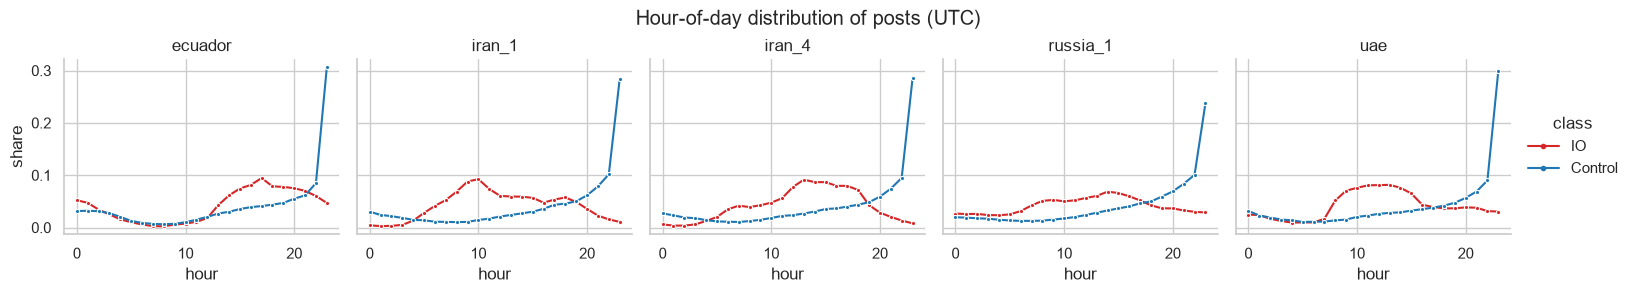

In [17]:
posts['hour'] = posts['post_time'].dt.hour.astype('int8')
hourly = (posts.groupby(['ioCountry', 'class'], observed=True)['hour'].value_counts(normalize=True)
          .rename('share').reset_index())
g = sns.relplot(data=hourly, x='hour', y='share', hue='class', col='ioCountry', kind='line', col_wrap=5,
                palette=CLASS_PALETTE, hue_order=CLASS_ORDER, height=2.8, aspect=1.1, marker='o', markersize=3)
g.set_titles('{col_name}')
g.figure.suptitle('Hour-of-day distribution of posts (UTC)', y=1.04)
plt.show()

In [18]:
# The hour-of-day plot reveals a strong peak of CONTROL posts at 23h UTC: investigate the sampling of control data
span = posts.groupby('acc_h').agg(cls=('class', 'first'), n=('post_time', 'size'),
                                  first=('post_time', 'min'), last=('post_time', 'max'))
span['span_days'] = (span['last'] - span['first']).dt.total_seconds() / 86400
sampling = pd.DataFrame({
    '% posts published at 23h UTC': posts.groupby('class', observed=True)['hour'].apply(lambda h: 100 * (h == 23).mean()),
    '% accounts whose posts all fall within 24h': span.groupby('cls', observed=True)['span_days'].apply(lambda s: 100 * (s < 1).mean()),
    '% accounts with 95-105 posts': span.groupby('cls', observed=True)['n'].apply(lambda s: 100 * s.between(95, 105).mean()),
    '% accounts with >105 posts': span.groupby('cls', observed=True)['n'].apply(lambda s: 100 * (s > 105).mean()),
})
display(sampling.round(1))
del span

,% posts published at 23h UTC,% accounts whose posts all fall within 24h,% accounts with 95-105 posts,% accounts with >105 posts
IO,2.7000,6.7000,2.0000,46.3000
Control,26.6000,94.2000,15.3000,3.9000


**Sampling artefact of the control data.** Control posts are not complete timelines: ~27% of them are published in
the last hour of the day (UTC), most control accounts contribute posts from **a single day**, and their number of
posts is capped at about 100. This is consistent with control data collected through day-by-day topical searches
(returning the most recent posts of each day), while IO accounts are released with their whole history.
Consequently, features describing *how much* and *when* an account posts (number of posts, active days, time
concentration, hour-of-day profile, burstiness) separate IO from control accounts largely **because of the data
collection design** rather than of behaviour. They are computed in the profile (Section 1.5) but treated with
caution and excluded from the clustering input (Section 2.1).

class            IO                                                      Control                                                    
               mean     std    min     25%      50%      75%        max     mean     std    min     25%      50%      75%        max
text_len   126.4300 57.3300 1.0000 90.0000 123.0000 155.0000 2,373.0000 143.9600 97.9900 1.0000 95.0000 135.0000 167.0000 2,582.0000
n_words     13.2300  7.1600 1.0000  8.0000  12.0000  17.0000   126.0000  14.5800  8.9200 0.0000  9.0000  13.0000  18.0000   132.0000
n_hashtags   0.7200  1.3900 0.0000  0.0000   0.0000   1.0000    40.0000   1.6000  2.3200 0.0000  0.0000   1.0000   2.0000    36.0000
n_urls       0.6600  0.6500 0.0000  0.0000   1.0000   1.0000     7.0000   0.6900  0.6000 0.0000  0.0000   1.0000   1.0000     9.0000
n_mentions   0.7600  0.9500 0.0000  0.0000   1.0000   1.0000    50.0000   0.9100  1.9200 0.0000  0.0000   1.0000   1.0000    51.0000

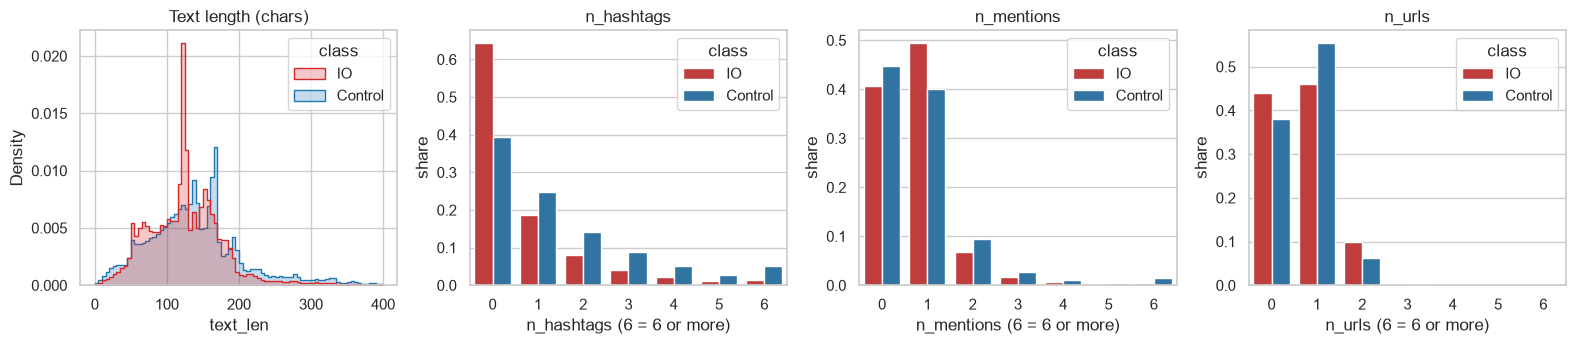

In [19]:
num_post_cols = ['text_len', 'n_words', 'n_hashtags', 'n_urls', 'n_mentions']
desc = posts.groupby('class', observed=True)[num_post_cols].describe().T
display(desc.unstack(level=1).loc[:, (slice(None), ['mean', 'std', 'min', '25%', '50%', '75%', 'max'])].round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
sample_posts = posts.sample(1_000_000, random_state=RANDOM_STATE)
sns.histplot(data=sample_posts, x='text_len', hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER,
             stat='density', common_norm=False, bins=80, binrange=(0, 400), element='step', ax=axes[0])
axes[0].set_title('Text length (chars)')
for ax, col in zip(axes[1:], ['n_hashtags', 'n_mentions', 'n_urls']):
    share = (sample_posts.assign(v=sample_posts[col].clip(upper=6))
             .groupby('class', observed=True)['v'].value_counts(normalize=True).rename('share').reset_index())
    sns.barplot(data=share, x='v', y='share', hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER, ax=ax)
    ax.set_xlabel(f'{col} (6 = 6 or more)')
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 1.3.4 Account-level attributes

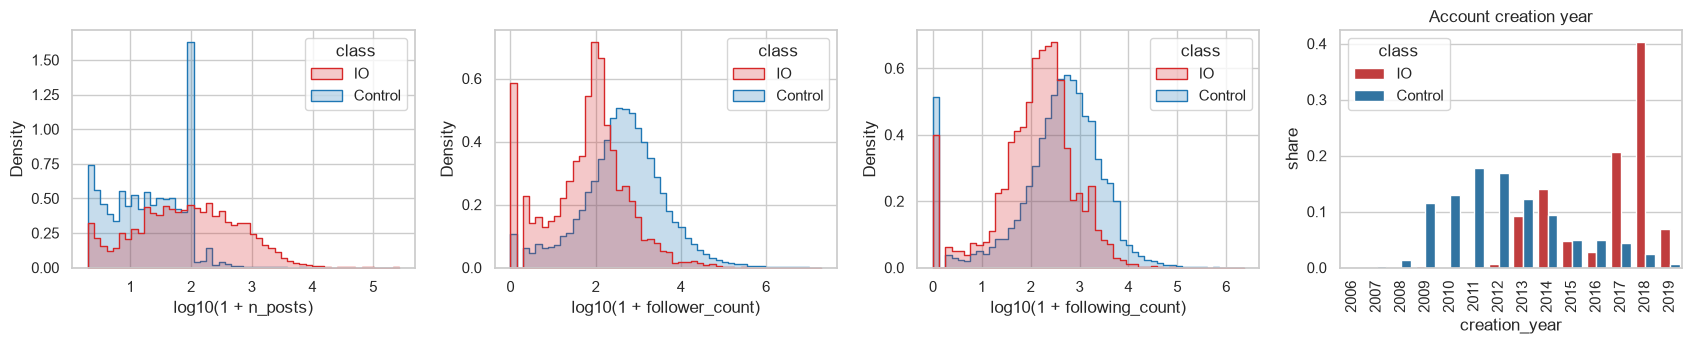

,median n_posts,median follower_count,median following_count
class,,,
IO,88.0000,85.0000,157.0000
Control,19.0000,467.0000,469.0000


In [20]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col in zip(axes, ['n_posts', 'follower_count', 'following_count']):
    sns.histplot(data=acc, x=np.log10(1 + acc[col]), hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER,
                 stat='density', common_norm=False, bins=50, element='step', ax=ax)
    ax.set_xlabel(f'log10(1 + {col})')
acc['creation_year'] = acc['account_creation_date'].dt.year
cy = acc.groupby('class', observed=True)['creation_year'].value_counts(normalize=True).rename('share').reset_index()
sns.barplot(data=cy, x='creation_year', y='share', hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER, ax=axes[3])
axes[3].tick_params(axis='x', rotation=90)
axes[3].set_title('Account creation year')
plt.tight_layout()
plt.show()
display(acc.groupby('class', observed=True)[['n_posts', 'follower_count', 'following_count']]
        .median().rename(columns=lambda c: f'median {c}'))

* IO accounts have many more posts than control accounts (median 88 vs 19) – mostly a consequence of the sampling
  design discussed above (control accounts are capped at ~100 posts, visible as a spike at log10(101) ≈ 2).
* IO accounts have **far fewer followers** (median 85 vs 467) and following (157 vs 469), with a visible group of
  IO accounts with zero followers.
* IO accounts are created in **waves** (2013–2014, 2017 and especially 2018), consistent with batches of accounts
  being registered for a campaign, whereas control accounts are older and spread over 2009–2016.
* IO posts contain fewer hashtags than control posts, and their text-length distribution shows sharp peaks
  (template-like messages of identical length).

## 1.4 Correlations and redundancies

### 1.4.1 Numerical variables (post level)

Spearman's rank correlation is used because most variables are skewed counts.

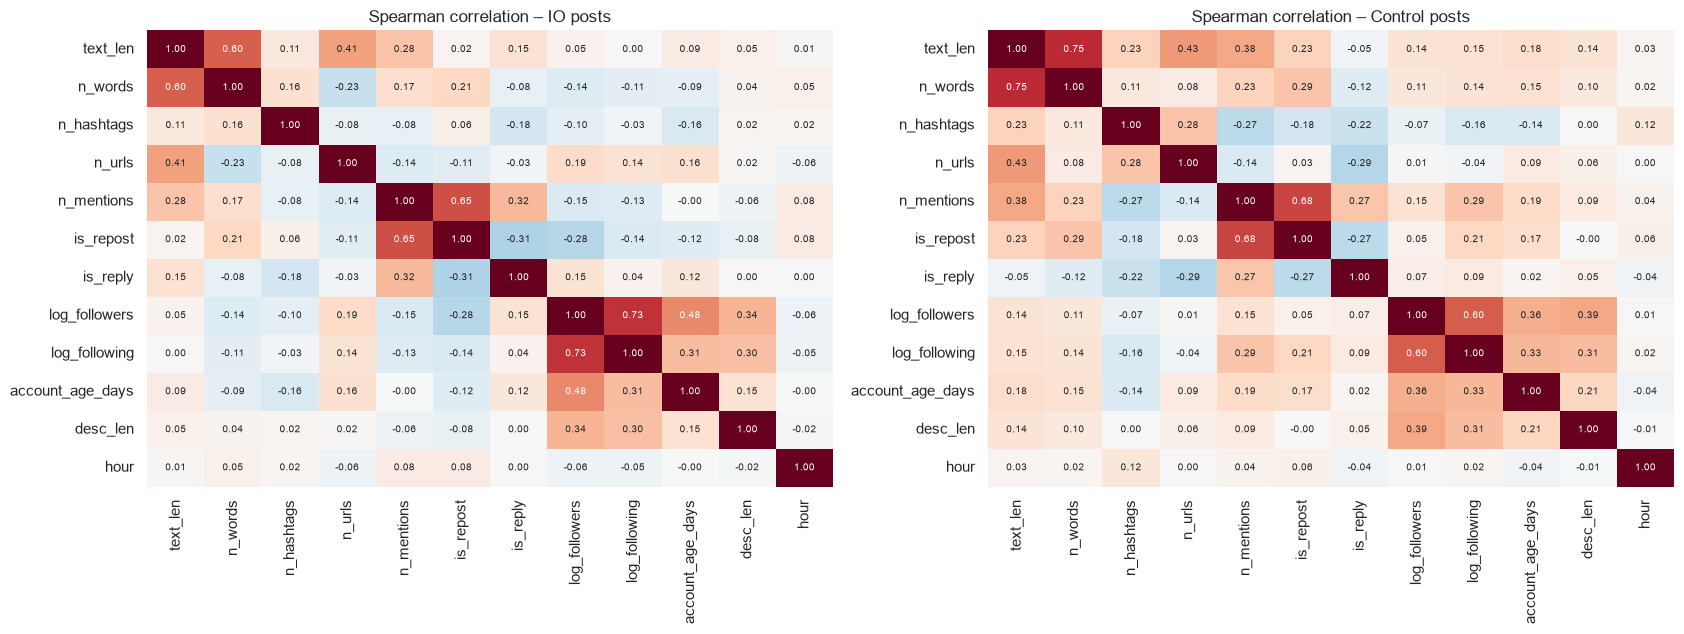

In [21]:
corr_df = sample_posts.assign(
    is_repost=sample_posts['is_repost'].astype(int), is_reply=sample_posts['is_reply'].astype(int),
    log_followers=np.log10(1 + sample_posts['follower_count']),
    log_following=np.log10(1 + sample_posts['following_count']),
    account_age_days=(sample_posts['post_time'] - sample_posts['account_creation_date']).dt.days,
    desc_len=sample_posts['desc_len'].fillna(0))
corr_cols = ['text_len', 'n_words', 'n_hashtags', 'n_urls', 'n_mentions', 'is_repost', 'is_reply',
             'log_followers', 'log_following', 'account_age_days', 'desc_len', 'hour']
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, cls in zip(axes, CLASS_ORDER):
    cm = corr_df.loc[corr_df['class'] == cls, corr_cols].corr(method='spearman')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, cbar=False, annot_kws={'size': 7})
    ax.set_title(f'Spearman correlation – {cls} posts')
plt.tight_layout()
plt.show()

### 1.4.2 Categorical variables (Cramér's V)

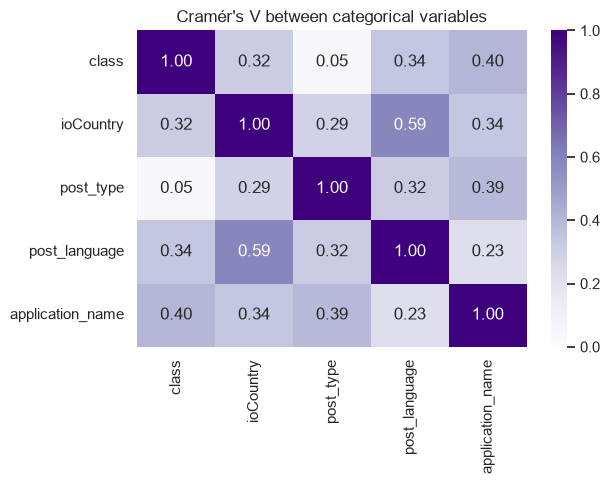

In [22]:
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    """Bias-corrected Cramér's V between two categorical variables."""
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1))))


cs = sample_posts.sample(300_000, random_state=RANDOM_STATE)
cat_vars = {'class': cs['class'].astype(str), 'ioCountry': cs['ioCountry'].astype(str),
            'post_type': cs['post_type'].astype(str),
            'post_language': cs['post_language'].astype(str).where(cs['post_language'].isin(top_lang), 'other'),
            'application_name': cs['application_name'].astype(str).where(cs['application_name'].isin(top_apps), 'other')}
cv = pd.DataFrame(index=cat_vars, columns=cat_vars, dtype=float)
for a in cat_vars:
    for b in cat_vars:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(cat_vars[a], cat_vars[b])
plt.figure(figsize=(6.5, 5))
sns.heatmap(cv, annot=True, fmt='.2f', cmap='Purples', vmin=0, vmax=1)
plt.title("Cramér's V between categorical variables")
plt.tight_layout()
plt.show()

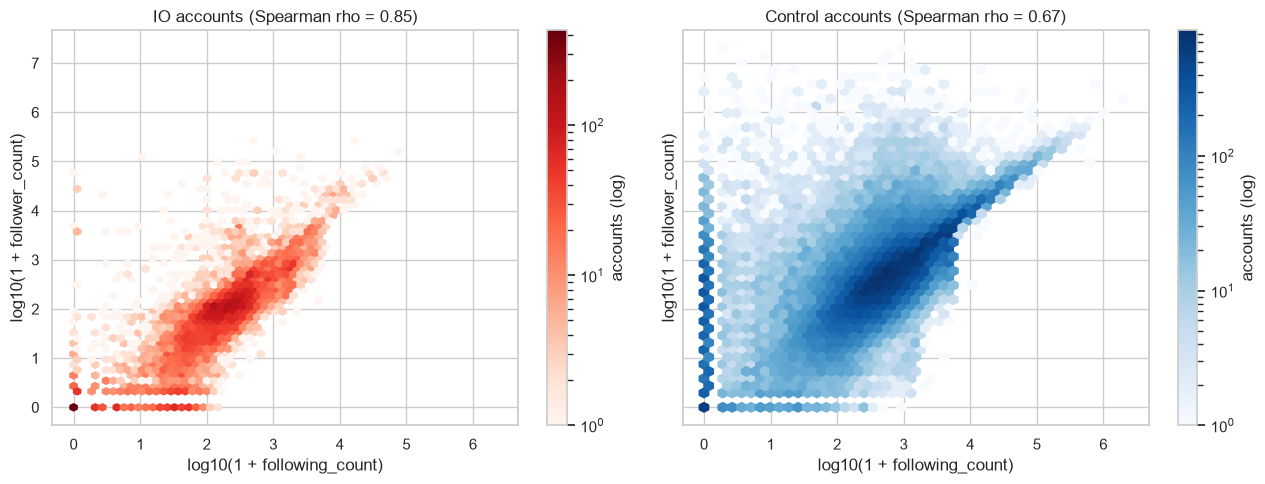

57243

In [23]:
# Account level: followers vs following (log-log) for the two classes
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, cls in zip(axes, CLASS_ORDER):
    a = acc[acc['class'] == cls]
    hb = ax.hexbin(np.log10(1 + a['following_count']), np.log10(1 + a['follower_count']), gridsize=45,
                   bins='log', cmap='Reds' if cls == 'IO' else 'Blues', mincnt=1)
    rho = stats.spearmanr(a['following_count'], a['follower_count']).statistic
    ax.set_title(f'{cls} accounts (Spearman rho = {rho:.2f})')
    ax.set_xlabel('log10(1 + following_count)')
    ax.set_ylabel('log10(1 + follower_count)')
    fig.colorbar(hb, ax=ax, label='accounts (log)')
plt.tight_layout()
plt.show()
del corr_df, cs, cat_vars
gc.collect()

**Redundancies found** (and how they are handled):

* `text_len` and `n_words` are strongly correlated (ρ ≈ 0.75–0.80) → only the text length is used in the profiles.
* `n_mentions` is strongly correlated with `is_repost` (ρ ≈ 0.65): a repost always mentions the original author,
  so mentions must be interpreted together with the post type.
* `log_followers` and `log_following` are correlated (ρ ≈ 0.6–0.7) but not redundant: their difference (the
  follower/following balance) is informative on its own.
* `reposted_accountid` / `reposted_postid` are fully determined by `is_repost` (both present iff the post is a
  repost); the two reply identifiers carry the same information as the `is_reply` flag. They are only used to
  derive relational features (who is reposted / replied to).
* `follower_count`, `following_count`, `account_creation_date` and `account_profile_description` are repeated on
  every post: at post level they are redundant copies of an account attribute and are moved to the profile.
* `post_language` is strongly associated with the operation (Cramér's V ≈ 0.6), so language features must be read
  relative to the operation. Among the categorical attributes, `application_name` is the one most associated with
  the class (V ≈ 0.4). Interestingly the **post type is almost independent of the class globally (V ≈ 0.05)**
  although it differs a lot inside each operation: the IO–control difference goes in opposite directions in
  different operations (e.g. more reposts for IO in Ecuador, fewer in Iran/UAE) and cancels out when pooled –
  a Simpson-like effect that confirms the need for per-operation comparisons.
* Hashtags, mentions and URLs are only weakly correlated with each other, so they carry complementary information.

## 1.5 User profiling and feature engineering

Starting from the cleaned post-level table we build **one profile per account** (`accountid`). For an account $u$
let $P_u$ be its set of posts, $N_u = |P_u|$, and let $\mathbb{1}[\cdot]$ be the indicator function.
Entropies use base-2 logarithms: $H(X) = -\sum_x p_x \log_2 p_x$, where $p_x$ is the share of the account's posts
with value $x$.

**A. Activity and time (affected by the sampling of control data, see 1.3.3)**

| Feature | What it captures | Formula |
|---|---|---|
| `n_posts` | volume of activity | $N_u$ |
| `rel_activity` | activity compared with the typical account of the same operation $c(u)$ (unusually active accounts) | $\log_{10}\big(N_u / \operatorname{median}_{v: c(v)=c(u)} N_v\big)$ |
| `active_days` | number of distinct days with at least one post | $\lvert\{\text{day}(p) : p \in P_u\}\rvert$ |
| `lifespan_days` | observed activity period | $\max_p t_p - \min_p t_p$ (days) |
| `posts_per_active_day` | posting intensity on active days | $N_u / \text{active\_days}$ |
| `max_day_share` | temporal concentration: share of posts published on the most active day | $\max_d n_{u,d} / N_u$ |
| `max_week_share` | same on a weekly basis | $\max_w n_{u,w} / N_u$ |
| `hour_entropy` | regularity of the daily rhythm (0 = always the same hour, 1 = uniform over the 24 hours) | $H(\text{hour}) / \log_2 24$ |
| `burstiness` | burstiness of inter-post times $\tau$ (−1 periodic, 0 Poisson, →1 bursty); needs $N_u \ge 3$ | $B = (\sigma_\tau - \mu_\tau)/(\sigma_\tau + \mu_\tau)$ |

**B. Interaction and broadcasting patterns**

| Feature | What it captures | Formula |
|---|---|---|
| `repost_ratio` | amplification of other content | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ repost}]$ |
| `reply_ratio` | conversational activity | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ reply}]$ |
| `original_ratio` | own broadcast content | $1 - \text{repost\_ratio} - \text{reply\_ratio}$ |
| `interaction_ratio` | posts that directly address other accounts (replies or original posts with mentions) | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ reply} \lor (p \text{ not repost} \land m_p > 0)]$ |
| `broadcast_index` | balance between amplification and conversation, in $[-1, 1]$ | $\text{repost\_ratio} - \text{interaction\_ratio}$ |
| `self_repost_ratio` | self-amplification (reposting one's own posts) | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ repost of } u]$ |
| `in_network_repost_ratio` | amplification of *other accounts of the same operation* present in the dataset (coordinated amplification) | $\frac{1}{N_u}\sum_p \mathbb{1}[\text{src}(p) \in A_{c(u)} \setminus \{u\}]$ |
| `top_reposted_share` | concentration of the reposted sources (share of reposts taken from the single most reposted account; NaN without reposts) | $\max_a r_{u,a} / \sum_a r_{u,a}$ |

**C. Content and platform**

| Feature | What it captures | Formula |
|---|---|---|
| `hashtags_per_post`, `urls_per_post`, `mentions_per_post` | use of hashtags / links / mentions | $\frac{1}{N_u}\sum_p h_p$ (same for URLs and mentions) |
| `mean_text_len` | average length of the posts (characters) | $\frac{1}{N_u}\sum_p \text{len}(p)$ |
| `lang_entropy`, `n_languages` | use of one or several languages (`unknown` is a category) | $H(\text{post\_language})$, number of distinct languages |
| `app_entropy`, `n_apps` | reliance on one or several publishing clients | $H(\text{application\_name})$, number of distinct clients |
| `dup_text_share` | **copy-paste coordination**: share of the account's original (non-repost) posts whose normalised text (≥ 20 characters) is also published by at least one other account | $\frac{1}{N_u}\sum_{p \text{ not repost}} \mathbb{1}[\lvert\{v : \text{text}_p \in T_v\}\rvert \ge 2]$ |

**D. Account attributes**

| Feature | What it captures | Formula |
|---|---|---|
| `follower_count`, `following_count` | audience and social activity (cleaned snapshot) | — (used as $\log_{10}(1+x)$) |
| `follower_following_ratio` | balance between audience and followed accounts | $\log_{10}\frac{1+\text{followers}}{1+\text{following}}$ |
| `account_age_days` | age of the account when it posts | $\operatorname{median}_p (t_p - \text{creation\_date})$ (days) |
| `desc_len`, `has_description` | effort put in the profile | length of the biography (0 if missing), $\mathbb{1}[\text{bio present}]$ |

In [24]:
t0 = time.time()
p = posts  # alias: cleaned post-level table
g = p.groupby('acc_h', sort=True)
prof = pd.DataFrame({
    'accountid': g['accountid'].first().astype(str),
    'ioCountry': g['account_ioCountry'].first(),
    'is_control': g['is_control'].first(),
    'n_posts': g.size(),
    'n_reposts': g['is_repost'].sum(),
    'n_replies': g['is_reply'].sum(),
    'hashtags_per_post': g['n_hashtags'].mean(),
    'urls_per_post': g['n_urls'].mean(),
    'mentions_per_post': g['n_mentions'].mean(),
    'mean_text_len': g['text_len'].mean().astype(float),
    'follower_count': g['follower_count'].first(),
    'following_count': g['following_count'].first(),
    'desc_len': g['desc_len'].first().fillna(0).astype(float),
})
prof['class'] = pd.Categorical(np.where(prof['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)

# --- A. activity and time ---
day_num = p['post_time'].to_numpy().astype('datetime64[D]').astype(np.int64)
day_counts = pd.Series(1, index=p.index).groupby([p['acc_h'], day_num]).size()
week_counts = pd.Series(1, index=p.index).groupby([p['acc_h'], (day_num + 3) // 7]).size()  # ISO-like weeks
prof['active_days'] = day_counts.groupby(level=0).size()
prof['max_day_share'] = day_counts.groupby(level=0).max() / prof['n_posts']
prof['max_week_share'] = week_counts.groupby(level=0).max() / prof['n_posts']
prof['posts_per_active_day'] = prof['n_posts'] / prof['active_days']
prof['lifespan_days'] = (g['post_time'].max() - g['post_time'].min()).dt.total_seconds() / 86400
op_median = prof.groupby('ioCountry', observed=True)['n_posts'].median()
prof['rel_activity'] = np.log10(prof['n_posts'] / prof['ioCountry'].map(op_median).astype(float))
del day_counts, week_counts


def group_entropy(acc_key: pd.Series, values: pd.Series) -> pd.DataFrame:
    """Shannon entropy (bits) of the distribution of `values` within every account + number of distinct values."""
    cnt = pd.Series(1, index=acc_key.index).groupby([acc_key, values]).size()
    cnt = cnt[cnt > 0]
    share = cnt / cnt.groupby(level=0).transform('sum')
    ent = -(share * np.log2(share)).groupby(level=0).sum() + 0.0  # "+ 0.0" turns -0.0 into 0.0
    return pd.DataFrame({'entropy': ent, 'n_distinct': cnt.groupby(level=0).size()})


e = group_entropy(p['acc_h'], p['hour'])
prof['hour_entropy'] = e['entropy'] / np.log2(24)
e = group_entropy(p['acc_h'], p['post_language'].cat.codes)
prof['lang_entropy'], prof['n_languages'] = e['entropy'], e['n_distinct']
e = group_entropy(p['acc_h'], p['application_name'].cat.codes)
prof['app_entropy'], prof['n_apps'] = e['entropy'], e['n_distinct']
del e

# Burstiness of inter-post times (accounts with >= 3 posts)
srt = p[['acc_h', 'post_time']].sort_values(['acc_h', 'post_time'])
tsec = srt['post_time'].to_numpy().astype('datetime64[s]').astype(np.int64)
acc_arr = srt['acc_h'].to_numpy()
same = acc_arr[1:] == acc_arr[:-1]
gaps = pd.Series(np.diff(tsec)[same].astype(float), index=acc_arr[1:][same])
gstats = gaps.groupby(level=0).agg(['mean', 'std', 'size'])
burst = (gstats['std'] - gstats['mean']) / (gstats['std'] + gstats['mean'])
prof['burstiness'] = burst.where(gstats['size'] >= 2)
del srt, tsec, acc_arr, same, gaps, gstats, burst

# --- B. interaction and broadcasting ---
prof['repost_ratio'] = prof['n_reposts'] / prof['n_posts']
prof['reply_ratio'] = prof['n_replies'] / prof['n_posts']
prof['original_ratio'] = 1 - prof['repost_ratio'] - prof['reply_ratio']
interactive = p['is_reply'] | (~p['is_repost'] & (p['n_mentions'] > 0))
prof['interaction_ratio'] = interactive.groupby(p['acc_h']).sum() / prof['n_posts']
prof['broadcast_index'] = prof['repost_ratio'] - prof['interaction_ratio']

reposts = p.loc[p['is_repost'], ['acc_h', 'rep_acc_h', 'account_ioCountry']]
self_rep = reposts['rep_acc_h'] == reposts['acc_h']
prof['self_repost_ratio'] = (self_rep.groupby(reposts['acc_h']).sum()
                             .reindex(prof.index, fill_value=0) / prof['n_posts'])
src_country = reposts['rep_acc_h'].map(prof['ioCountry'].astype(str))  # NaN if the source is not in the dataset
in_net = (src_country == reposts['account_ioCountry'].astype(str)) & ~self_rep
prof['in_network_repost_ratio'] = (in_net.groupby(reposts['acc_h']).sum()
                                   .reindex(prof.index, fill_value=0) / prof['n_posts'])
src_counts = pd.Series(1, index=reposts.index).groupby([reposts['acc_h'], reposts['rep_acc_h']]).size()
prof['top_reposted_share'] = src_counts.groupby(level=0).max() / prof['n_reposts'].where(prof['n_reposts'] > 0)
del reposts, self_rep, src_country, in_net, src_counts, interactive

# --- C. duplicated (copy-pasted) content ---
orig = p.loc[~p['is_repost'] & (p['text_len'] >= 20), ['acc_h', 'text_h']]
acc_per_text = orig.drop_duplicates().groupby('text_h').size()
dup_flag = orig['text_h'].map(acc_per_text) > 1
prof['dup_text_share'] = (dup_flag.groupby(orig['acc_h']).sum().reindex(prof.index, fill_value=0)
                          / prof['n_posts'])
del orig, acc_per_text, dup_flag

# --- D. account attributes ---
age_days = (p['post_time'] - p['account_creation_date']).dt.total_seconds() / 86400
prof['account_age_days'] = age_days.groupby(p['acc_h']).median()
prof['follower_following_ratio'] = np.log10((1 + prof['follower_count']) / (1 + prof['following_count']))
prof['has_description'] = (prof['desc_len'] > 0).astype(int)
del age_days, g
gc.collect()

prof = prof.reset_index().rename(columns={'acc_h': 'acc_key'})
prof.to_parquet(PROFILES_PQ, index=False)
print(f'Profiles: {prof.shape[0]:,} accounts x {prof.shape[1]} columns  ({time.time() - t0:.0f}s) -> {PROFILES_PQ.name}')
display(prof.head(3).T)

Profiles: 85,155 accounts x 39 columns  (13s) -> user_profiles.parquet


,0,1,2
acc_key,239081641355624,387856201983411,628273391639702
accountid,bd46a338deb53c1fc309ac9a8bf44862f252ae6562,2cf7132817a7821dfa1a29f554ea49038c56d12324,895cc2f189bc87dd5de3cb44eb93f86b5fbe0fa1f7
ioCountry,uae,uae,ecuador
is_control,True,True,True
n_posts,1,71,1
n_reposts,1,36,1
n_replies,0,21,0
hashtags_per_post,1.0000,0.1972,2.0000
urls_per_post,1.0000,0.5775,0.0000
mentions_per_post,1.0000,0.9859,1.0000


### 1.5.1 Quality of the derived features

Some indicators are only meaningful when an account has enough posts: with one post every entropy is 0 and every
share is 0 or 1, and burstiness is undefined below three posts. We therefore flag the accounts with at least
`MIN_POSTS = 5` posts (the population used for clustering) and check missing values of the derived features.

In [25]:
MIN_POSTS = 5
FEATURES_A = ['n_posts', 'rel_activity', 'active_days', 'lifespan_days', 'posts_per_active_day', 'max_day_share',
              'max_week_share', 'hour_entropy', 'burstiness']
FEATURES_B = ['repost_ratio', 'reply_ratio', 'original_ratio', 'interaction_ratio', 'broadcast_index',
              'self_repost_ratio', 'in_network_repost_ratio', 'top_reposted_share']
FEATURES_C = ['hashtags_per_post', 'urls_per_post', 'mentions_per_post', 'mean_text_len', 'lang_entropy',
              'n_languages', 'app_entropy', 'n_apps', 'dup_text_share']
FEATURES_D = ['follower_count', 'following_count', 'follower_following_ratio', 'account_age_days', 'desc_len',
              'has_description']
ALL_FEATURES = FEATURES_A + FEATURES_B + FEATURES_C + FEATURES_D

prof['enough_posts'] = prof['n_posts'] >= MIN_POSTS
print(pd.crosstab(prof['class'], prof['enough_posts'], margins=True))
na = prof[ALL_FEATURES].isna().sum()
print('Missing values in derived features:', na[na > 0].to_dict())
print('(burstiness: accounts with < 3 posts; top_reposted_share: accounts without reposts; '
      'mean_text_len: accounts whose only posts have no text)')

enough_posts  False   True    All
class                            
IO              913  10004  10917
Control       16347  57891  74238
All           17260  67895  85155
Missing values in derived features: {'burstiness': 10535, 'top_reposted_share': 23122}
(burstiness: accounts with < 3 posts; top_reposted_share: accounts without reposts; mean_text_len: accounts whose only posts have no text)


### 1.5.2 Exploratory analysis of the profiles: IO vs control

For each feature we compare the two classes (accounts with ≥ 5 posts) with medians and with **Cliff's delta**
$\delta = P(X_{IO} > X_{C}) - P(X_{IO} < X_{C}) \in [-1, 1]$, a non-parametric effect size obtained from the
Mann-Whitney U statistic ($\delta = 2U/(n_1 n_2) - 1$); $|\delta| > 0.474$ is conventionally a large effect.

,median IO,median Control,cliffs_delta,p_value,group
feature,,,,,
active_days,30.0000,1.0000,0.9850,0.0000,A
max_day_share,0.1110,1.0000,-0.9740,0.0000,A
max_week_share,0.2100,1.0000,-0.9490,0.0000,A
lifespan_days,143.0990,0.8560,0.9100,0.0000,A
posts_per_active_day,3.7220,32.0000,-0.8810,0.0000,A
account_age_days,95.7610,841.9940,-0.6790,0.0000,D
dup_text_share,0.0230,0.0000,0.6300,0.0000,C
hour_entropy,0.7290,0.4830,0.5850,0.0000,A
follower_count,95.0000,609.0000,-0.5260,0.0000,D


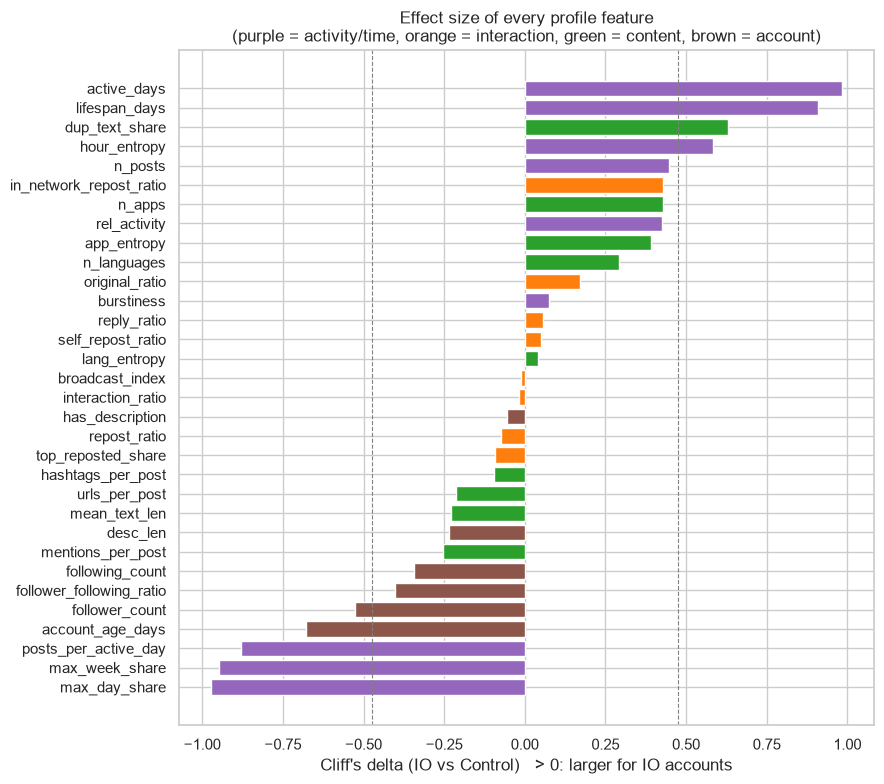

In [26]:
pe = prof[prof['enough_posts']].copy()
rows = []
for f in ALL_FEATURES:
    a = pe.loc[pe['class'] == 'IO', f].dropna()
    b = pe.loc[pe['class'] == 'Control', f].dropna()
    u, pval = stats.mannwhitneyu(a, b, alternative='two-sided')
    rows.append({'feature': f, 'median IO': a.median(), 'median Control': b.median(),
                 'cliffs_delta': 2 * u / (len(a) * len(b)) - 1, 'p_value': pval})
effects = pd.DataFrame(rows).set_index('feature')
effects['group'] = ['A'] * len(FEATURES_A) + ['B'] * len(FEATURES_B) + ['C'] * len(FEATURES_C) + ['D'] * len(FEATURES_D)
display(effects.sort_values('cliffs_delta', key=np.abs, ascending=False).round(3))

plt.figure(figsize=(9, 8))
eff_sorted = effects.sort_values('cliffs_delta')
colors = [{'A': '#9467bd', 'B': '#ff7f0e', 'C': '#2ca02c', 'D': '#8c564b'}[gr] for gr in eff_sorted['group']]
plt.barh(eff_sorted.index, eff_sorted['cliffs_delta'], color=colors)
for x in (-0.474, 0.474):
    plt.axvline(x, color='grey', ls='--', lw=0.8)
plt.xlabel("Cliff's delta (IO vs Control)   > 0: larger for IO accounts")
plt.title('Effect size of every profile feature\n(purple = activity/time, orange = interaction, '
          'green = content, brown = account)')
plt.tight_layout()
plt.show()

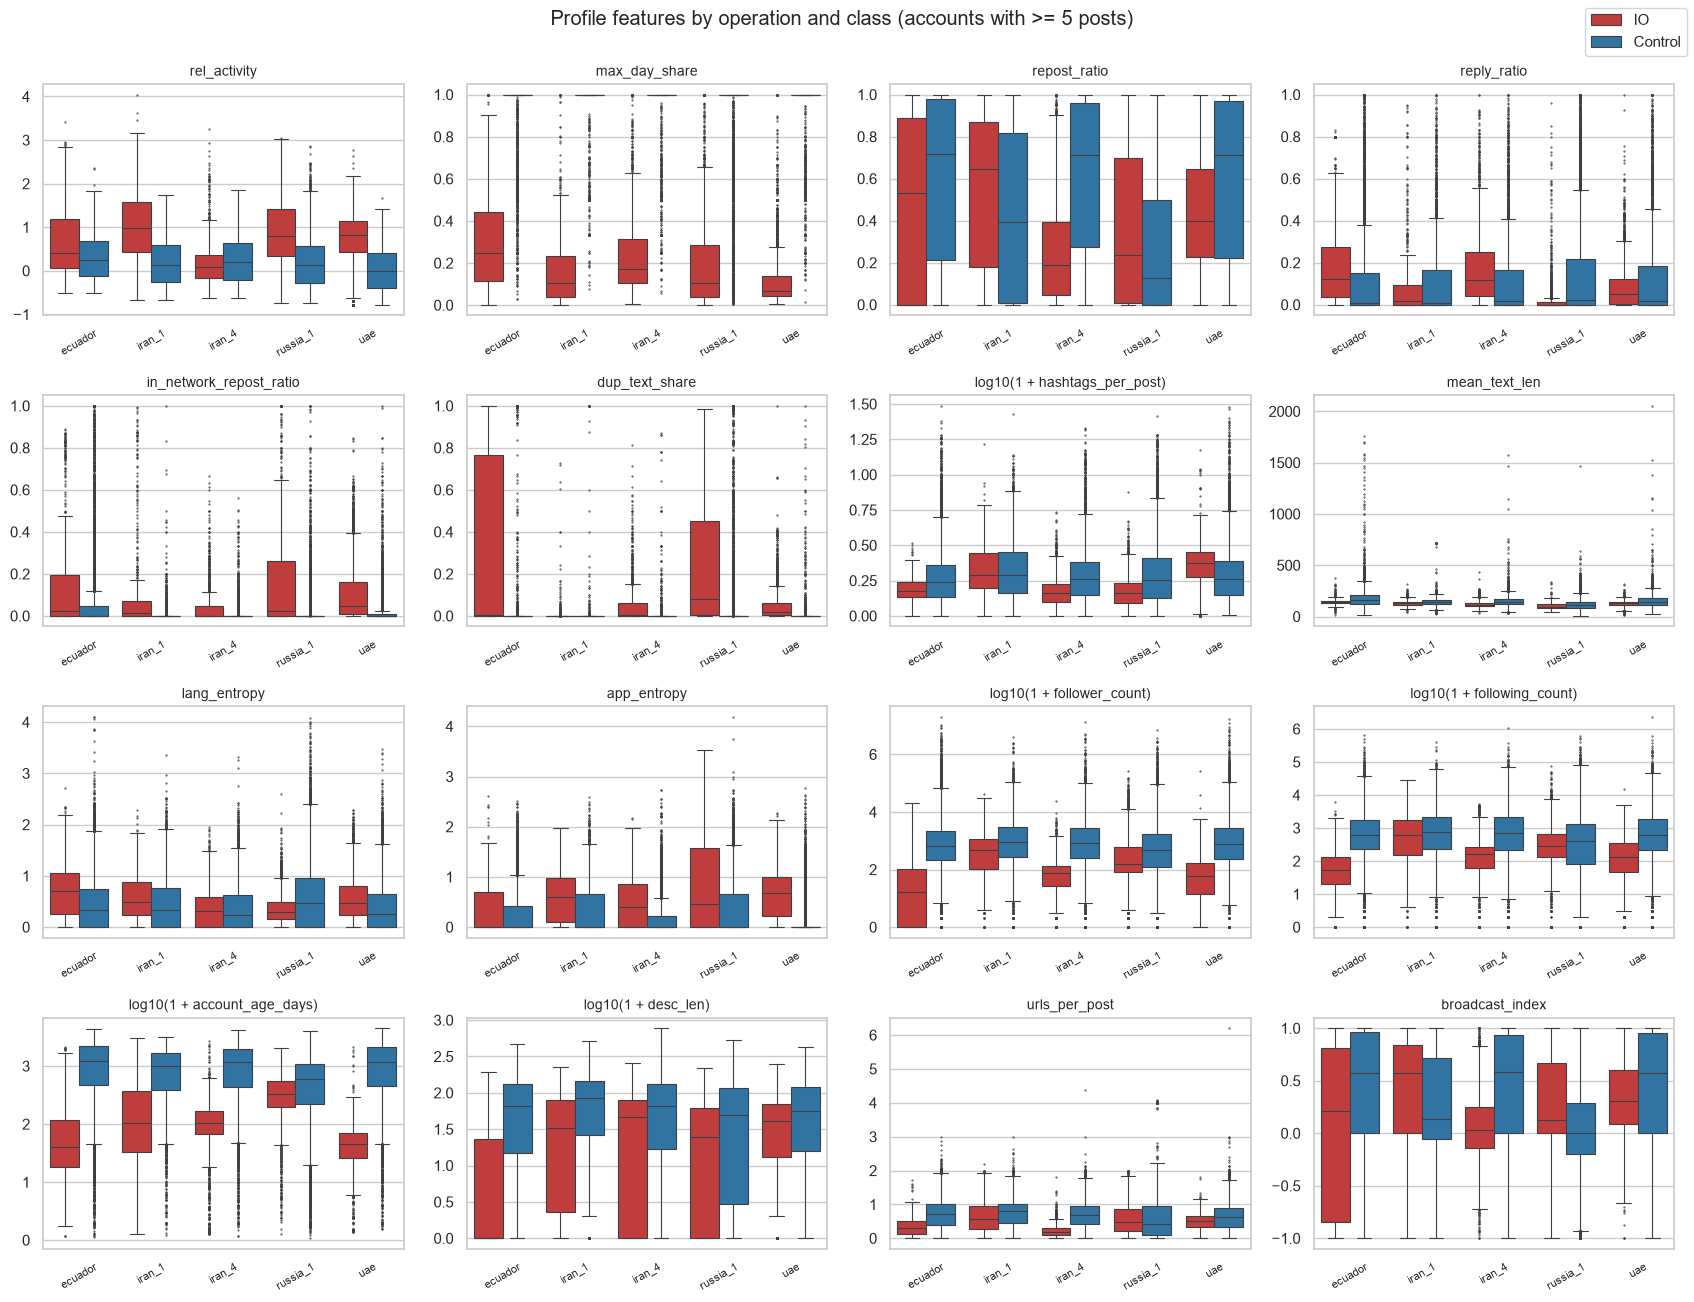

In [27]:
show = ['rel_activity', 'max_day_share', 'repost_ratio', 'reply_ratio', 'in_network_repost_ratio', 'dup_text_share',
        'hashtags_per_post', 'mean_text_len', 'lang_entropy', 'app_entropy', 'follower_count', 'following_count',
        'account_age_days', 'desc_len', 'urls_per_post', 'broadcast_index']
log_feats = {'follower_count', 'following_count', 'account_age_days', 'desc_len', 'hashtags_per_post'}
fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, f in zip(axes.ravel(), show):
    y = np.log10(1 + pe[f]) if f in log_feats else pe[f]
    sns.boxplot(data=pe, x='ioCountry', y=y, hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER,
                ax=ax, fliersize=0.5, linewidth=0.8)
    ax.set_title(f'log10(1 + {f})' if f in log_feats else f, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.legend().remove()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')
fig.suptitle('Profile features by operation and class (accounts with >= 5 posts)', y=1.0)
plt.tight_layout()
plt.show()

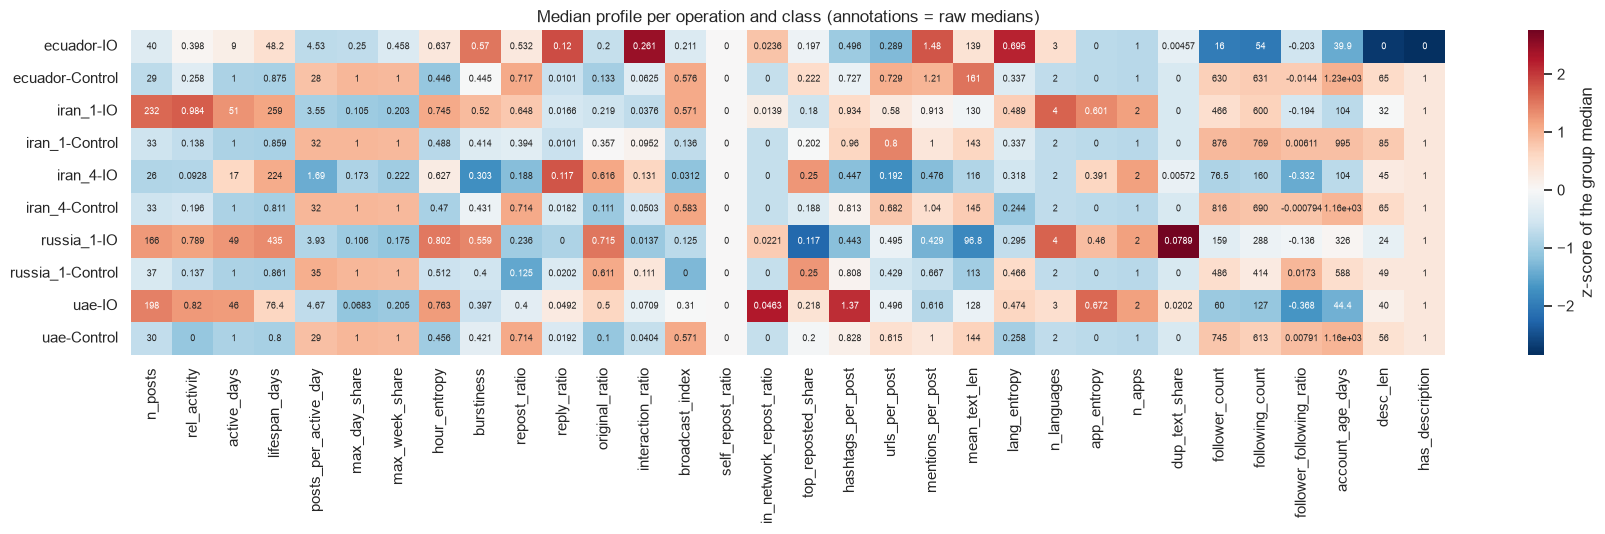

In [28]:
# Median profile of every operation x class group (z-scored per feature for comparability)
med = pe.groupby(['ioCountry', 'class'], observed=True)[ALL_FEATURES].median()
med_log = med.copy()
for f in ['n_posts', 'active_days', 'lifespan_days', 'posts_per_active_day', 'follower_count', 'following_count',
          'account_age_days', 'desc_len']:
    med_log[f] = np.log10(1 + med_log[f])
plt.figure(figsize=(18, 5.5))
sns.heatmap((med_log - med_log.mean()) / med_log.std().replace(0, 1), cmap='RdBu_r', center=0,
            annot=med.map(lambda v: f'{v:.3g}'), fmt='', annot_kws={'size': 6.5},
            cbar_kws={'label': 'z-score of the group median'})
plt.title('Median profile per operation and class (annotations = raw medians)')
plt.ylabel('')
plt.tight_layout()
plt.show()

### 1.5.3 Correlations between the derived features

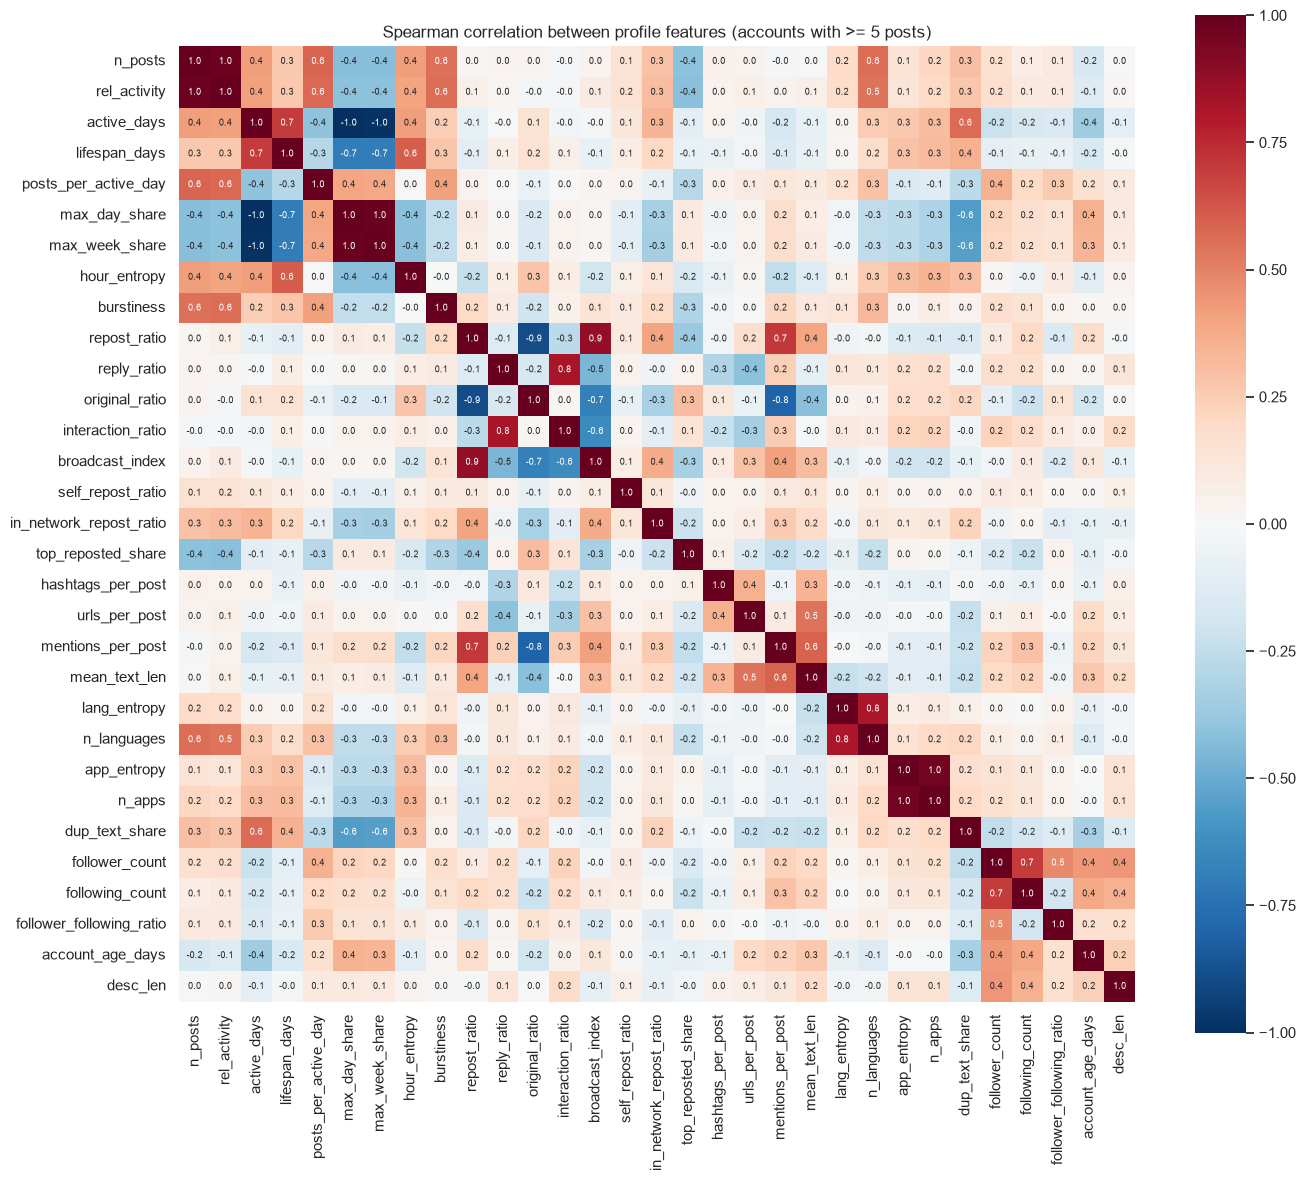

Most correlated pairs of features (|rho| >= 0.7):


,level_0,level_1,rho
0,active_days,max_day_share,-0.9990
1,max_day_share,max_week_share,0.9870
2,active_days,max_week_share,-0.9860
3,n_posts,rel_activity,0.9770
4,app_entropy,n_apps,0.9650
5,repost_ratio,original_ratio,-0.8970
6,repost_ratio,broadcast_index,0.8820
7,reply_ratio,interaction_ratio,0.8240
8,lang_entropy,n_languages,0.8190
9,original_ratio,mentions_per_post,-0.8080


In [29]:
corr_feats = [f for f in ALL_FEATURES if f != 'has_description']
cm = pe[corr_feats].corr(method='spearman')
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 6.5}, square=True)
plt.title('Spearman correlation between profile features (accounts with >= 5 posts)')
plt.tight_layout()
plt.show()

pairs = (cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1)).stack().rename('rho').reset_index()
         .assign(abs_rho=lambda d: d['rho'].abs()).sort_values('abs_rho', ascending=False))
print('Most correlated pairs of features (|rho| >= 0.7):')
display(pairs[pairs['abs_rho'] >= 0.7].drop(columns='abs_rho').round(3).reset_index(drop=True))

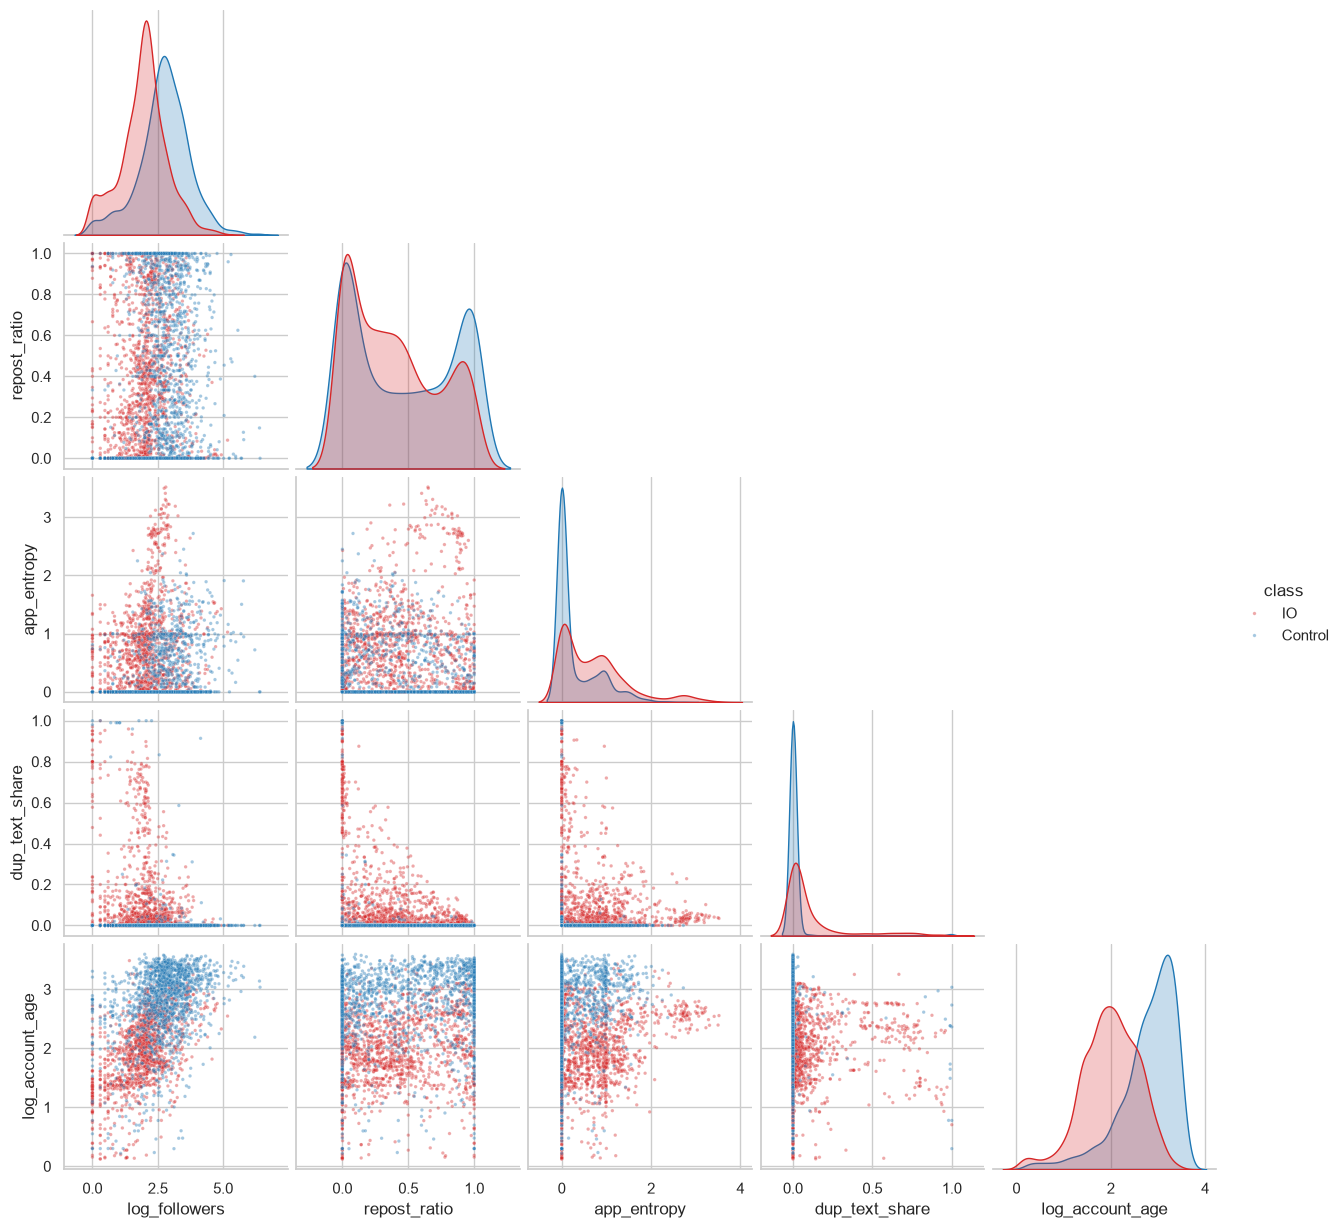

In [30]:
# Pairwise view of a few key features (random sample of accounts, log scales where needed)
pp_sample = pe.groupby('class', observed=True).sample(1500, random_state=RANDOM_STATE)
pp = pd.DataFrame({'log_followers': np.log10(1 + pp_sample['follower_count']),
                   'repost_ratio': pp_sample['repost_ratio'],
                   'app_entropy': pp_sample['app_entropy'],
                   'dup_text_share': pp_sample['dup_text_share'],
                   'log_account_age': np.log10(1 + pp_sample['account_age_days']),
                   'class': pp_sample['class']})
sns.pairplot(pp, hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER, corner=True,
             plot_kws={'s': 6, 'alpha': 0.4}, diag_kws={'common_norm': False})
plt.show()

**Main findings on the user profiles**

* The **activity/time features** (group A) show the largest IO–control differences (|δ| > 0.88 for `active_days`,
  `max_day_share`, `max_week_share`, `lifespan_days`, `posts_per_active_day`), but they mostly reflect the
  sampling design of the control data (one day of posts per account → `active_days = 1`, `max_day_share = 1`).
  They are kept in the profile for completeness, but are **not** valid behavioural discriminators.
* Among the behavioural features, IO accounts are clearly:
  * **younger** when they post (median account age 96 vs 842 days, δ ≈ −0.68) – accounts created for the campaign;
  * engaged in **copy-paste coordination** (`dup_text_share`, δ ≈ +0.63): a large share of their original posts
    is published verbatim by other accounts, especially in Ecuador and Russia;
  * **less followed** (median 95 vs 609 followers, δ ≈ −0.53) and following fewer accounts, with a negative
    follower/following balance;
  * **amplifying their own network** (`in_network_repost_ratio`, δ ≈ +0.43) and using **more publishing clients
    per account** (`n_apps`, `app_entropy`) – although the latter is partly inflated by their larger number of posts;
  * using fewer mentions, URLs and shorter descriptions/texts (small–moderate effects).
* Repost/reply ratios and language entropy have small *global* effects, but large effects with **opposite signs
  in different operations** (e.g. Iran_4 IO accounts repost much less than their controls, Ecuador IO accounts much
  more), so they remain useful to separate behavioural styles.
* **Redundant features** (|ρ| ≥ 0.7): `active_days`/`max_day_share`/`max_week_share`; `n_posts`/`rel_activity`;
  `app_entropy`/`n_apps`; `lang_entropy`/`n_languages`; `repost_ratio`/`original_ratio`/`broadcast_index`/
  `mentions_per_post`; `reply_ratio`/`interaction_ratio`. Only one representative per group is used for clustering.

---
# Task 2 – Clustering Analysis

Task 2 only needs the user profiles produced in Task 1 (`data/user_profiles.parquet`), so it can be run on its own
after the setup cells of Section 0.

## 2.1 Selection and preparation of the attributes

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

# Free the large post-level objects of Task 1 (if they exist) before clustering
for _name in ['posts', 'p', 'sample_posts', 'pe', 'pp', 'pp_sample', 'monthly', 'hourly']:
    globals().pop(_name, None)
gc.collect()

MIN_POSTS = 5
prof = pd.read_parquet(PROFILES_PQ)
data = prof[prof['n_posts'] >= MIN_POSTS].reset_index(drop=True)
data['class'] = pd.Categorical(data['class'].astype(str), categories=CLASS_ORDER)
print(f'Accounts available for clustering (>= {MIN_POSTS} posts): {len(data):,}  '
      f'{data["class"].value_counts().to_dict()}')

Accounts available for clustering (>= 5 posts): 67,895  {'Control': 57891, 'IO': 10004}


**Selected attributes.** The clustering input must describe *behaviour* in a way that is comparable between IO and
control accounts, without redundant information and without the label:

| Attribute (clustering input) | From profile feature | Transformation | Why |
|---|---|---|---|
| `repost_ratio` | `repost_ratio` | – | amplification behaviour (represents the redundant group original/broadcast/mentions) |
| `reply_ratio` | `reply_ratio` | – | conversational behaviour (represents `interaction_ratio`) |
| `in_network_repost_ratio` | same | – | coordinated amplification of accounts of the same operation |
| `dup_text_share` | same | – | copy-paste coordination |
| `log_hashtags_per_post` | `hashtags_per_post` | $\log_{10}(1+x)$ | hashtag campaigning (long tail) |
| `urls_per_post` | same | – | link sharing |
| `log_mean_text_len` | `mean_text_len` | $\log_{10}(1+x)$ | content length (long right tail) |
| `lang_entropy` | same | – | multilingual behaviour (represents `n_languages`) |
| `app_entropy` | same | – | use of several clients (represents `n_apps`) |
| `log_followers` | `follower_count` | $\log_{10}(1+x)$ | audience (long tail) |
| `log_following` | `following_count` | $\log_{10}(1+x)$ | social activity (long tail) |
| `log_account_age` | `account_age_days` | $\log_{10}(1+x)$ | age of the account when posting |
| `log_desc_len` | `desc_len` | $\log_{10}(1+x)$ | profile completeness |

**Excluded attributes:** the label (`is_control`) and the operation (`ioCountry`) – used only to *evaluate* the
clusters; all activity/time features of group A, because they are dominated by the sampling design of the
control data (Section 1.3.3) and would make clusters reproduce the data-collection process; the redundant
features found in Section 1.5.3; `follower_following_ratio` (a linear combination of two selected attributes);
`self_repost_ratio` (almost always 0) and `top_reposted_share` (undefined for accounts without reposts).

**Preparation:** logarithmic transformation of long-tailed attributes, winsorisation at the 0.5th / 99.5th
percentiles (the outliers of Section 1.2.6 are genuine but would otherwise dominate centroid-based methods), and
standardisation (z-scores), so that every attribute contributes equally to Euclidean distances.

Clustering matrix: (67895, 13)


,count,mean,std,min,25%,50%,75%,max
repost_ratio,"67,895.0000",0.4420,0.3840,0.0000,0.0350,0.3750,0.8480,1.0000
reply_ratio,"67,895.0000",0.1210,0.1900,0.0000,0.0000,0.0200,0.1720,0.8890
in_network_repost_ratio,"67,895.0000",0.0400,0.1130,0.0000,0.0000,0.0000,0.0130,0.8070
dup_text_share,"67,895.0000",0.0270,0.1160,0.0000,0.0000,0.0000,0.0000,0.9030
log_hashtags_per_post,"67,895.0000",0.2830,0.1950,0.0030,0.1380,0.2500,0.3830,1.0260
urls_per_post,"67,895.0000",0.5860,0.4120,0.0000,0.2220,0.5760,0.9290,2.0000
log_mean_text_len,"67,895.0000",2.1080,0.1740,1.5460,1.9990,2.1210,2.2160,2.5590
lang_entropy,"67,895.0000",0.5050,0.5210,0.0000,0.0000,0.3690,0.7870,2.3920
app_entropy,"67,895.0000",0.3400,0.5250,0.0000,0.0000,0.0000,0.6500,2.6770
log_followers,"67,895.0000",2.6270,1.0000,0.0000,2.0680,2.6720,3.2410,5.4410


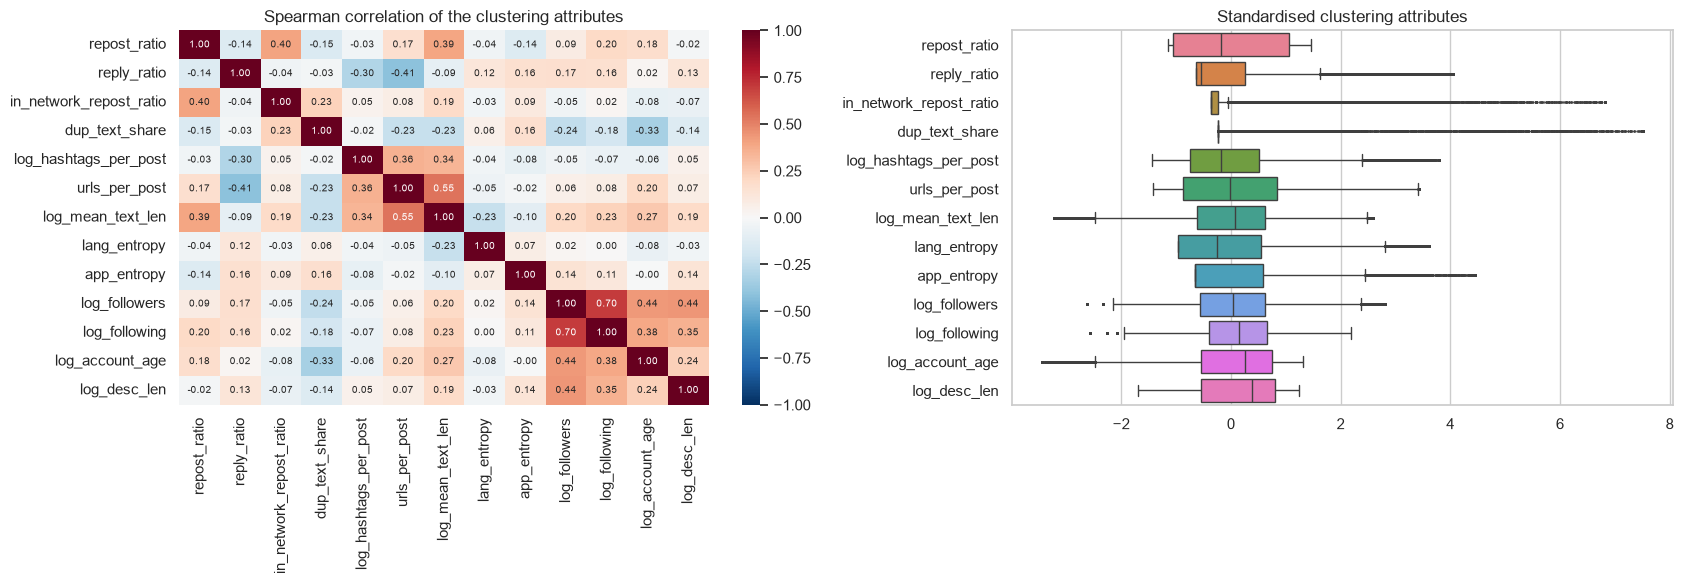

In [32]:
CLUSTER_SPEC = {  # clustering attribute -> (profile column, log-transform?)
    'repost_ratio': ('repost_ratio', False),
    'reply_ratio': ('reply_ratio', False),
    'in_network_repost_ratio': ('in_network_repost_ratio', False),
    'dup_text_share': ('dup_text_share', False),
    'log_hashtags_per_post': ('hashtags_per_post', True),
    'urls_per_post': ('urls_per_post', False),
    'log_mean_text_len': ('mean_text_len', True),
    'lang_entropy': ('lang_entropy', False),
    'app_entropy': ('app_entropy', False),
    'log_followers': ('follower_count', True),
    'log_following': ('following_count', True),
    'log_account_age': ('account_age_days', True),
    'log_desc_len': ('desc_len', True),
}
CLUSTER_FEATURES = list(CLUSTER_SPEC)

feat = pd.DataFrame({name: np.log10(1 + data[col].clip(lower=0)) if use_log else data[col]
                     for name, (col, use_log) in CLUSTER_SPEC.items()})
feat = feat.fillna(feat.median())                       # mean_text_len is NaN only if no post has text
lo, hi = feat.quantile(0.005), feat.quantile(0.995)
feat = feat.clip(lower=lo, upper=hi, axis=1)            # winsorisation
scaler = StandardScaler()
X = scaler.fit_transform(feat)
print('Clustering matrix:', X.shape)
display(feat.describe().T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(feat.corr(method='spearman'), cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7}, ax=axes[0])
axes[0].set_title('Spearman correlation of the clustering attributes')
sns.boxplot(data=pd.DataFrame(X, columns=CLUSTER_FEATURES), orient='h', ax=axes[1], fliersize=0.5)
axes[1].set_title('Standardised clustering attributes')
plt.tight_layout()
plt.show()

Explained variance ratio (first 5 PCs): [0.206 0.165 0.099 0.085 0.078] | cumulative 2 PCs: 0.371


,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,log_hashtags_per_post,urls_per_post,log_mean_text_len,lang_entropy,app_entropy,log_followers,log_following,log_account_age,log_desc_len
PC1,0.2800,-0.0500,0.0600,-0.2900,0.0800,0.2900,0.4000,-0.1100,0.0500,0.4300,0.4100,0.3700,0.2900
PC2,0.2800,-0.4000,0.2900,-0.0100,0.3400,0.4000,0.3100,-0.1100,-0.1600,-0.3200,-0.2800,-0.1600,-0.2700


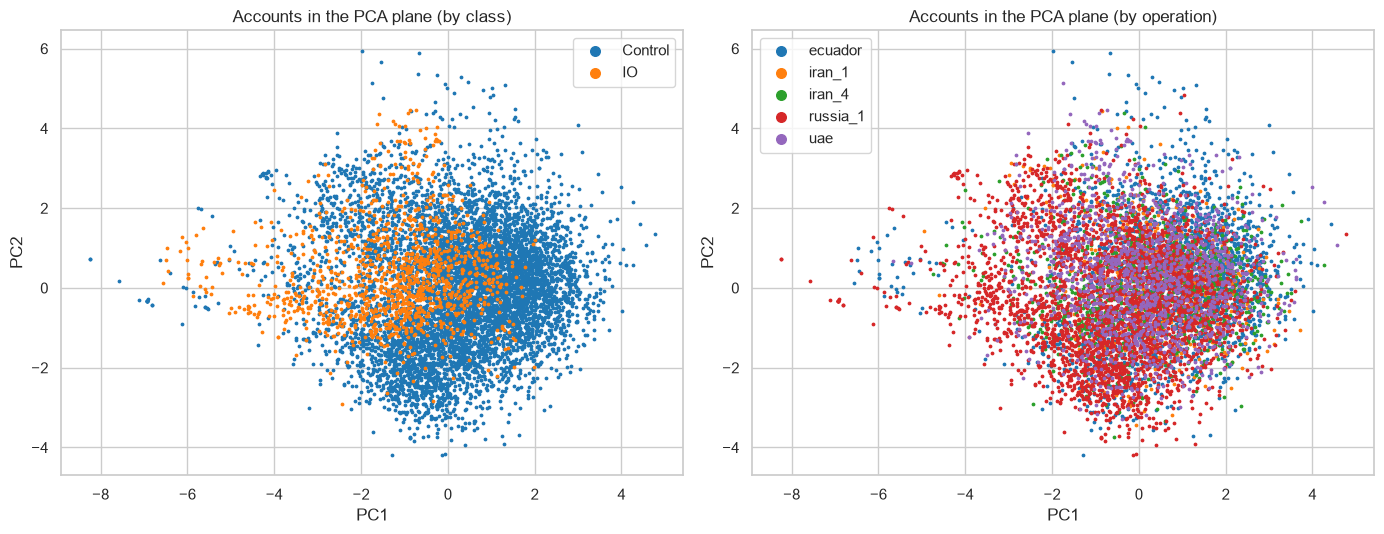

In [33]:
# PCA is used only for VISUALISATION of the clusters (all algorithms work in the full 13-d space)
pca = PCA(random_state=RANDOM_STATE).fit(X)
X_pca = pca.transform(X)[:, :2]
print('Explained variance ratio (first 5 PCs):', pca.explained_variance_ratio_[:5].round(3),
      '| cumulative 2 PCs:', pca.explained_variance_ratio_[:2].sum().round(3))
loadings = pd.DataFrame(pca.components_[:2].T, index=CLUSTER_FEATURES, columns=['PC1', 'PC2'])
display(loadings.round(2).T)

vis_idx = rng.choice(len(X), size=8000, replace=False)  # sample of points used in every scatter plot


def scatter_pca(labels, title, ax, noise_label=-1):
    """2-D PCA scatter of the visualisation sample coloured by cluster label (noise in light grey)."""
    lab = np.asarray(labels)[vis_idx]
    xy = X_pca[vis_idx]
    for c in sorted(set(lab)):
        m = lab == c
        if c == noise_label:
            ax.scatter(xy[m, 0], xy[m, 1], s=3, c='lightgrey', label='noise')
        else:
            ax.scatter(xy[m, 0], xy[m, 1], s=3, label=f'C{c}', color=plt.cm.tab10(c % 10))
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(markerscale=4, fontsize=7, loc='best')


fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
scatter_pca(np.where(data['class'] == 'IO', 1, 0), 'Accounts in the PCA plane (by class)', axes[0])
axes[0].legend(handles=axes[0].collections, labels=['Control', 'IO'], markerscale=4)
scatter_pca(data['ioCountry'].cat.codes, 'Accounts in the PCA plane (by operation)', axes[1])
axes[1].legend(handles=axes[1].collections, labels=list(data['ioCountry'].cat.categories), markerscale=4)
plt.tight_layout()
plt.show()

In [34]:
# Helper functions shared by all the clustering methods
def _cluster_names(labels, noise_label=-1):
    """Readable cluster names ('C0', 'C1', ..., 'noise')."""
    return pd.Series(np.asarray(labels)).map(lambda c: 'noise' if c == noise_label else f'C{c}')


def _order(names):
    return sorted(names, key=lambda s: (s == 'noise', int(s[1:]) if s != 'noise' else 0))


def cluster_summary(labels, name, noise_label=-1, idx=None):
    """Size, share of IO accounts and operation mix of every cluster (noise reported as 'noise').
    `idx` = positions of the accounts the labels refer to (default: all accounts)."""
    d = data if idx is None else data.iloc[idx]
    lab_str = _cluster_names(labels, noise_label).set_axis(d.index)
    is_io = d['class'].eq('IO')
    summ = pd.DataFrame({'size': lab_str.value_counts(),
                         'size %': 100 * lab_str.value_counts(normalize=True),
                         '% IO': 100 * is_io.groupby(lab_str).mean()})
    ops = pd.crosstab(lab_str, d['ioCountry'], normalize='index') * 100
    summ = summ.join(ops.add_prefix('% '))
    summ['% of all IO accounts'] = 100 * is_io.groupby(lab_str).sum() / is_io.sum()
    print(f'{name}: {len(summ) - ("noise" in summ.index)} clusters')
    return summ.loc[_order(summ.index)].round(1)


def cluster_profile_heatmap(labels, name, noise_label=-1, ax=None, idx=None):
    """Mean standardised value of every clustering attribute in every cluster, annotated with the median in
    original units (back-transformed when the attribute is on log scale)."""
    Xs = X if idx is None else X[idx]
    fs = feat if idx is None else feat.iloc[idx]
    lab = _cluster_names(labels, noise_label).to_numpy()
    z = pd.DataFrame(Xs, columns=CLUSTER_FEATURES).groupby(lab).mean()
    raw = fs.reset_index(drop=True).groupby(lab).median()
    for name_, (col, use_log) in CLUSTER_SPEC.items():
        if use_log:
            raw[name_] = 10 ** raw[name_] - 1
    order = _order(z.index)
    if ax is None:
        _, ax = plt.subplots(figsize=(15, 0.55 * len(order) + 1.8))
    sns.heatmap(z.loc[order], cmap='RdBu_r', center=0, vmin=-2, vmax=2, annot=raw.loc[order].map(lambda v: f'{v:.3g}'),
                fmt='', annot_kws={'size': 7.5}, ax=ax, cbar_kws={'label': 'mean z-score'})
    ax.set_title(f'{name}: cluster profiles (colour = mean z-score, text = median in original units)')
    ax.tick_params(axis='x', rotation=35)
    return ax


def internal_scores(Xs, labels, noise_label=-1, sample=None):
    """Silhouette, Davies-Bouldin and Calinski-Harabasz (noise points excluded)."""
    labels = np.asarray(labels)
    m = labels != noise_label
    if len(set(labels[m])) < 2:
        return {'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    return {'silhouette': silhouette_score(Xs[m], labels[m], sample_size=sample, random_state=RANDOM_STATE),
            'davies_bouldin': davies_bouldin_score(Xs[m], labels[m]),
            'calinski_harabasz': calinski_harabasz_score(Xs[m], labels[m])}

## 2.2 K-means

### 2.2.1 Choice of k

K-means (k-means++ initialisation, 10 restarts) is run for $k = 2, \dots, 12$ on all accounts. We look at the
**SSE** (elbow method), the **silhouette** (computed on a random sample of 10,000 accounts), the
**Davies-Bouldin** index (lower is better) and the **Calinski-Harabasz** index (higher is better).

,SSE,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,"764,206.9420",0.1400,2.4010,"10,521.3300"
3,"688,266.5140",0.1300,2.0830,"9,586.4820"
4,"631,190.9660",0.1470,1.7950,"9,015.1600"
5,"580,522.2570",0.1590,1.6910,"8,832.7730"
6,"542,183.5660",0.1520,1.7430,"8,525.8800"
7,"512,091.6740",0.1480,1.7790,"8,187.1720"
8,"489,978.5430",0.1520,1.6890,"7,771.8610"
9,"469,180.3480",0.1440,1.6820,"7,477.8870"
10,"451,617.3110",0.1480,1.6930,"7,198.7370"


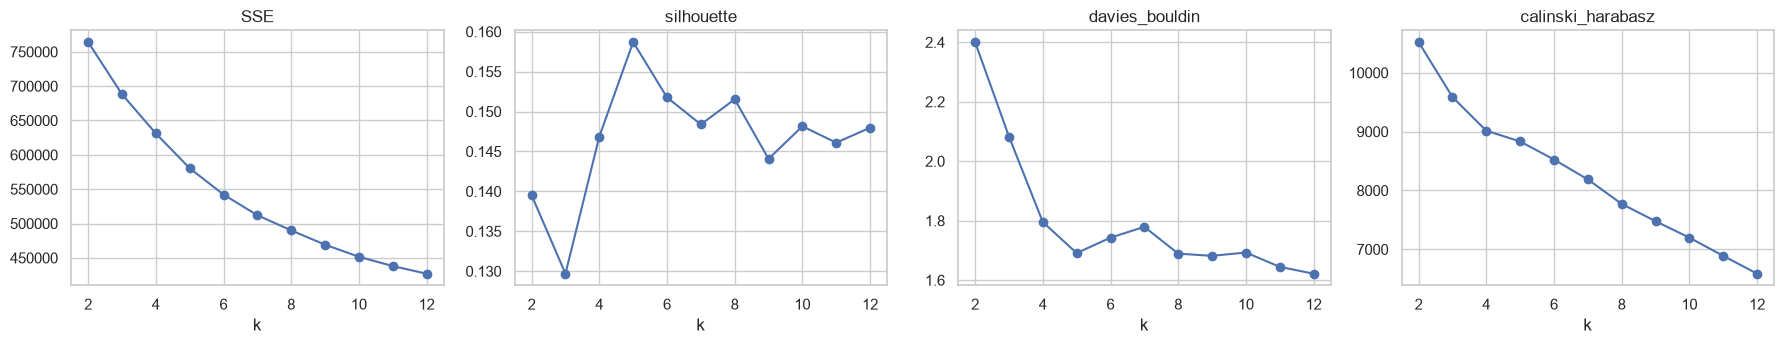

In [35]:
K_RANGE = range(2, 13)
km_rows, km_models = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    km_models[k] = km
    sc = internal_scores(X, km.labels_, sample=10_000)
    km_rows.append({'k': k, 'SSE': km.inertia_, **sc})
km_eval = pd.DataFrame(km_rows).set_index('k')
display(km_eval.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, col in zip(axes, ['SSE', 'silhouette', 'davies_bouldin', 'calinski_harabasz']):
    ax.plot(km_eval.index, km_eval[col], marker='o')
    ax.set_title(col)
    ax.set_xlabel('k')
plt.tight_layout()
plt.show()

The SSE curve decreases smoothly, without a sharp elbow (typical of behavioural data with no strongly separated
groups); its curvature is strongest between k = 4 and k = 6. The silhouette is low for every k (0.13–0.16: the
clusters overlap), but it reaches its **maximum at k = 5**, where the Davies-Bouldin index also has a local
minimum. Larger k only marginally improve DB while fragmenting the groups. We therefore select **k = 5**.

### 2.2.2 Final K-means model: centroids and interpretation

K-means centroids in original units (log attributes back-transformed):


,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.8450,0.0260,0.4470,0.0220,0.9590,0.7740,151.7960,0.3050,0.7150,130.9560,183.5540,262.0710,8.6960
C1,0.6470,0.0580,0.0230,0.0020,1.0840,0.8100,164.0450,0.4350,0.2890,"1,445.4240","1,093.6460","1,004.0680",45.7880
C2,0.2370,0.2780,0.0090,0.0090,0.4890,0.2420,95.9200,0.6040,0.4530,663.6690,467.1210,477.8340,34.9060
C3,0.3080,0.0450,0.0190,0.0170,1.3930,0.6770,120.1310,0.5400,0.2070,38.8670,25.2580,111.4580,6.5880
C4,0.0480,0.0590,0.0110,0.6430,0.7810,0.1380,81.7540,0.5340,0.1420,35.5250,60.2870,125.2880,4.5020


K-means (k=5): 5 clusters


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts
C0,3569,5.3000,49.8000,40.8000,2.7000,2.6000,30.4000,23.5000,17.8000
C1,27112,39.9000,3.6000,33.3000,8.7000,13.5000,26.5000,18.0000,9.8000
C2,20933,30.8000,12.0000,18.3000,5.1000,11.5000,52.6000,12.5000,25.2000
C3,14305,21.1000,24.1000,12.0000,5.6000,11.5000,50.3000,20.5000,34.4000
C4,1976,2.9000,65.1000,18.0000,1.0000,3.8000,74.1000,3.1000,12.9000


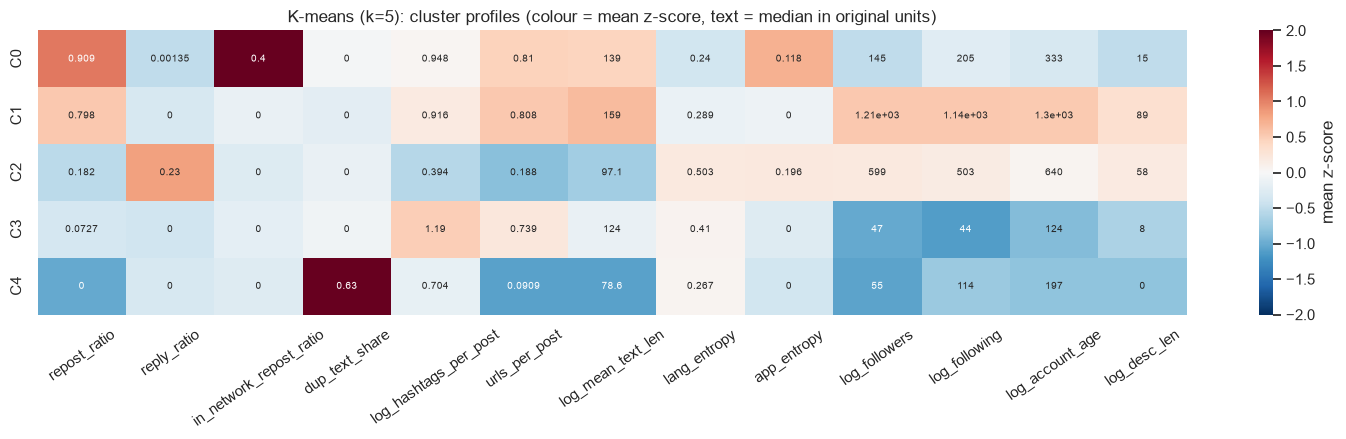

In [36]:
K_BEST = 5
kmeans = km_models[K_BEST]
labels_km = kmeans.labels_

# Centroids back to the original units of the clustering attributes
cent = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=CLUSTER_FEATURES,
                    index=[f'C{i}' for i in range(K_BEST)])
cent_orig = cent.copy()
for name_, (col, use_log) in CLUSTER_SPEC.items():
    if use_log:
        cent_orig[name_] = 10 ** cent[name_] - 1
cent_orig.columns = [CLUSTER_SPEC[c][0] if CLUSTER_SPEC[c][1] else c for c in CLUSTER_FEATURES]
print('K-means centroids in original units (log attributes back-transformed):')
display(cent_orig.round(3))

km_summary = cluster_summary(labels_km, f'K-means (k={K_BEST})')
display(km_summary)
cluster_profile_heatmap(labels_km, f'K-means (k={K_BEST})')
plt.tight_layout()
plt.show()

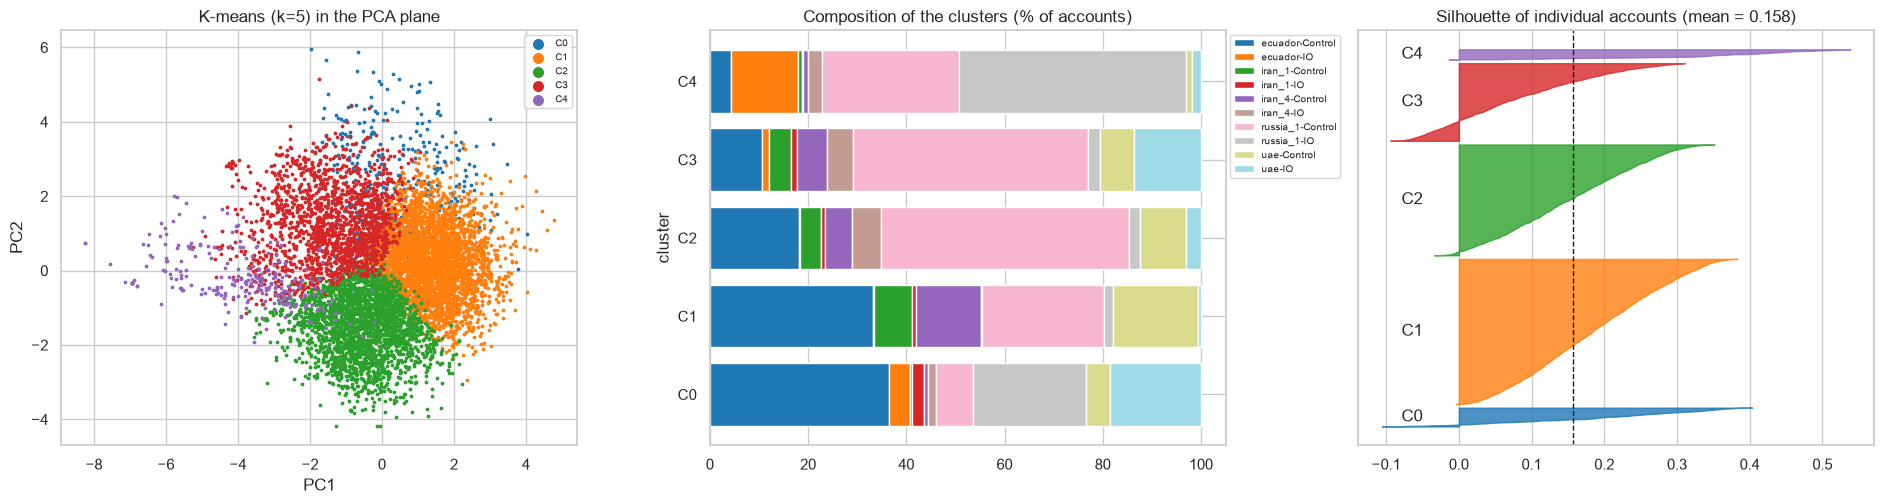

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
scatter_pca(labels_km, f'K-means (k={K_BEST}) in the PCA plane', axes[0])
# Composition of each cluster by operation and class
op_class = (data['ioCountry'].astype(str) + '-' + data['class'].astype(str)).rename('operation-class')
comp = pd.crosstab(pd.Series(labels_km, index=data.index, name='cluster').map(lambda c: f'C{c}'), op_class,
                   normalize='index') * 100
comp.plot(kind='barh', stacked=True, ax=axes[1], colormap='tab20', width=0.8, legend=False)
axes[1].set_title('Composition of the clusters (% of accounts)')
axes[1].legend(bbox_to_anchor=(1.0, 1.0), fontsize=7)
# Silhouette of the individual accounts (sample)
sil_idx = rng.choice(len(X), size=5000, replace=False)
sil_vals = silhouette_samples(X[sil_idx], labels_km[sil_idx])
y0 = 0
for c in range(K_BEST):
    v = np.sort(sil_vals[labels_km[sil_idx] == c])
    axes[2].fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=plt.cm.tab10(c), alpha=0.8)
    axes[2].text(-0.05, y0 + len(v) / 2, f'C{c}', ha='right', va='center')
    y0 += len(v) + 50
axes[2].axvline(sil_vals.mean(), color='k', ls='--', lw=1)
axes[2].set_title(f'Silhouette of individual accounts (mean = {sil_vals.mean():.3f})')
axes[2].set_yticks([])
plt.tight_layout()
plt.show()

In [38]:
# Characteristics NOT used for clustering (activity/time) inside each cluster, for interpretation only
extra = data.groupby(pd.Series(labels_km).map(lambda c: f'C{c}').values)[
    ['n_posts', 'active_days', 'max_day_share', 'hour_entropy', 'mentions_per_post', 'n_languages', 'n_apps']].median()
display(extra.round(2))

,n_posts,active_days,max_day_share,hour_entropy,mentions_per_post,n_languages,n_apps
C0,82.0000,3.0000,0.5000,0.6200,1.0900,3.0000,2.0000
C1,39.0000,1.0000,1.0000,0.4800,1.1600,2.0000,1.0000
C2,31.0000,1.0000,1.0000,0.5300,0.7300,3.0000,2.0000
C3,38.0000,1.0000,1.0000,0.5500,0.3100,2.0000,1.0000
C4,79.0000,5.0000,0.4500,0.5900,0.0600,3.0000,1.0000


**Interpretation of the K-means clusters** (medians in original units in the heatmap):

| Cluster | Size | % IO | Profile | Label |
|---|---|---|---|---|
| C1 | 40% | 4% | oldest accounts (≈3.5 years), ~1.2k followers / 1.1k following, complete biographies, repost-oriented with hashtags and links, longest texts | **established organic users** |
| C2 | 31% | 12% | highest reply ratio (23% of posts are replies), short texts, few links/hashtags, highest language entropy, mid-age accounts; mostly Russian controls | **conversational users** |
| C3 | 21% | 24% | very few followers (~47) and following (~44), young accounts (~4 months), very short or empty biographies, many hashtags, few reposts; contains **34% of all IO accounts** | **low-profile young accounts** |
| C0 | 5% | 50% | ~90% of posts are reposts and ~40% are reposts of *other accounts of the same operation*, more publishing clients than the other clusters, young accounts with few followers; mostly Ecuador and Russia | **network amplifiers** (coordinated retweeting) |
| C4 | 3% | 65% | almost never repost, **~63% of their posts are verbatim copies** of texts published by other accounts, short texts, few links, no biography; 74% Russia | **copy-paste broadcasters** |

* The two smallest clusters (C0, C4) are **IO-dominated** and correspond to two well-known coordination
  strategies (retweet networks and copy-pasta). C4 is also the best separated cluster (highest silhouette).
* IO accounts are nevertheless spread over all clusters: about one third of them look like low-profile young
  accounts (C3) and a quarter mimic ordinary conversational behaviour (C2). IO activity is therefore not a single
  behaviour but a **mix of strategies**, several of which are close to those of genuine users.
* The activity/time features (not used for clustering) confirm the picture: C0 and C4 accounts have more active
  days and lower daily concentration, typical of the (IO) full timelines.
* The low silhouette values show that, apart from C4, the clusters are partitions of a continuum rather than
  well-separated groups – which motivates the density-based analysis below.

## 2.3 Density-based clustering: DBSCAN

DBSCAN has two parameters: `min_samples` (minimum number of points – including the point itself – in the
`eps`-neighbourhood of a core point) and `eps` (neighbourhood radius). Because DBSCAN stores the neighbourhoods
of all points, it is run on a **random sample of 20,000 accounts** (same proportions of operations and classes as
the full data). We proceed in two steps:

1. **k-distance plots**: for each candidate `min_samples` we sort the distance of every point to its
   `min_samples`-th nearest neighbour; the "knee" of the curve suggests a value of `eps` separating dense regions
   from noise;
2. a **grid search** over (`eps`, `min_samples`) reporting number of clusters, share of noise, size of the largest
   cluster and silhouette (computed without noise).

DBSCAN sample: (19999, 13) {'Control': 17052, 'IO': 2947}


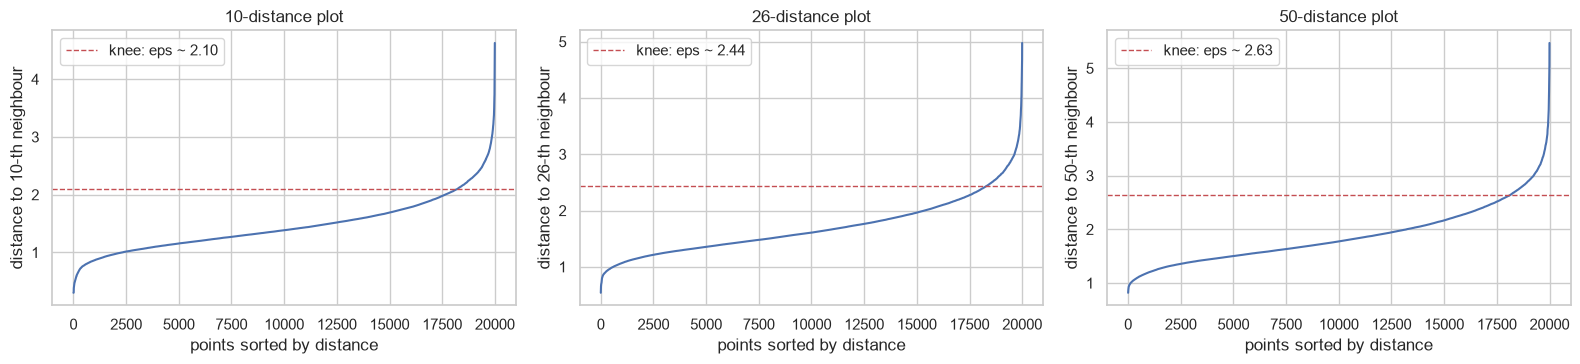

Knee of the k-distance curves: {10: np.float64(2.098), 26: np.float64(2.441), 50: np.float64(2.63)}


In [39]:
db_idx = np.sort(data.groupby(['ioCountry', 'class'], observed=True)
                 .sample(frac=20_000 / len(data), random_state=RANDOM_STATE).index.to_numpy())
Xd = X[db_idx]
print('DBSCAN sample:', Xd.shape, data.loc[db_idx, 'class'].value_counts().to_dict())


def knee_point(y):
    """Index of the point of a sorted curve with maximum distance from the chord joining its extremes."""
    x = np.linspace(0, 1, len(y))
    yn = (y - y.min()) / (y.max() - y.min())
    return int(np.argmax(np.abs(yn - x)))


MIN_SAMPLES_GRID = [10, 26, 50]       # 26 = 2 x number of attributes (rule of thumb)
fig, axes = plt.subplots(1, len(MIN_SAMPLES_GRID), figsize=(16, 3.8))
knees = {}
for ax, ms in zip(axes, MIN_SAMPLES_GRID):
    dist, _ = NearestNeighbors(n_neighbors=ms).fit(Xd).kneighbors(Xd)
    kd = np.sort(dist[:, -1])
    kn = knee_point(kd)
    knees[ms] = kd[kn]
    ax.plot(kd)
    ax.axhline(kd[kn], color='r', ls='--', lw=1, label=f'knee: eps ~ {kd[kn]:.2f}')
    ax.set_title(f'{ms}-distance plot')
    ax.set_xlabel('points sorted by distance')
    ax.set_ylabel(f'distance to {ms}-th neighbour')
    ax.legend()
plt.tight_layout()
plt.show()
print('Knee of the k-distance curves:', {k: round(v, 3) for k, v in knees.items()})

,min_samples,eps,n_clusters,noise %,largest cluster %,silhouette (no noise),% IO in noise
0,10,0.8000,36,92.9850,2.5600,0.2430,13.8310
1,10,1.0000,57,76.3090,12.8110,0.0570,13.7540
2,10,1.2000,31,49.8570,43.1820,-0.0800,15.2840
3,10,1.4000,20,28.4160,69.0180,-0.0100,16.8920
4,10,1.6000,6,15.2910,84.1340,0.2250,18.4110
5,10,1.8000,5,8.3100,91.0150,0.2180,19.0130
6,10,2.0000,5,4.0550,95.1000,0.2170,18.3720
7,10,2.2000,3,1.9700,97.3400,0.4650,16.7510
8,10,2.5000,2,0.6800,99.0500,0.5000,13.9710
9,26,0.8000,3,98.9350,0.4100,0.8400,14.5560


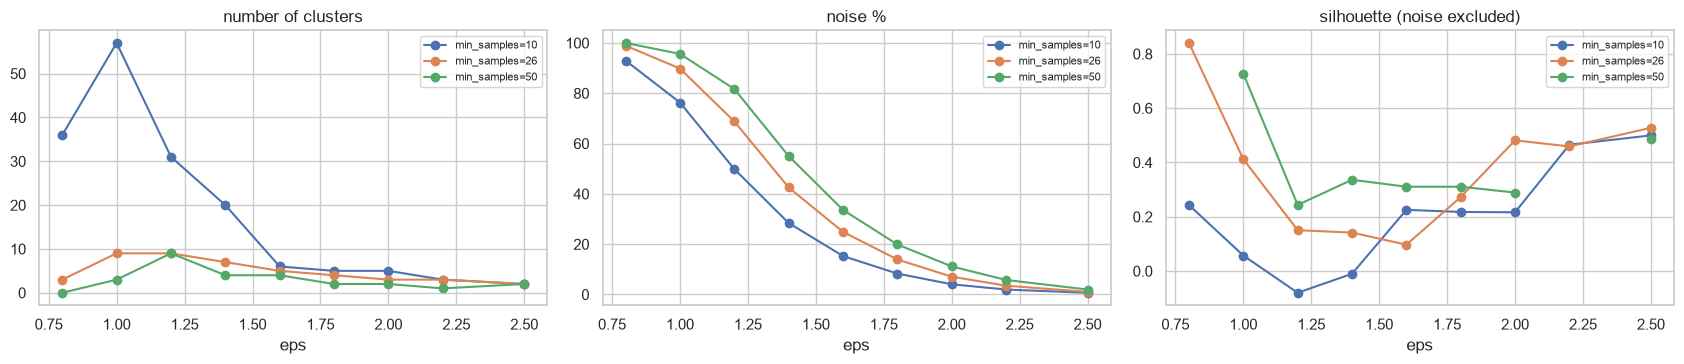

In [40]:
EPS_GRID = [0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5]
db_rows = []
for ms in MIN_SAMPLES_GRID:
    for eps in EPS_GRID:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xd)
        sizes = pd.Series(lab[lab >= 0]).value_counts()
        sc = internal_scores(Xd, lab, sample=5000)
        db_rows.append({'min_samples': ms, 'eps': eps, 'n_clusters': len(sizes), 'noise %': 100 * (lab == -1).mean(),
                        'largest cluster %': 100 * sizes.max() / len(lab) if len(sizes) else 0,
                        'silhouette (no noise)': sc['silhouette'],
                        '% IO in noise': 100 * data.loc[db_idx[lab == -1], 'class'].eq('IO').mean() if (lab == -1).any() else np.nan})
db_grid = pd.DataFrame(db_rows)
display(db_grid.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ms in MIN_SAMPLES_GRID:
    d = db_grid[db_grid['min_samples'] == ms]
    axes[0].plot(d['eps'], d['n_clusters'], marker='o', label=f'min_samples={ms}')
    axes[1].plot(d['eps'], d['noise %'], marker='o', label=f'min_samples={ms}')
    axes[2].plot(d['eps'], d['silhouette (no noise)'], marker='o', label=f'min_samples={ms}')
for ax, t in zip(axes, ['number of clusters', 'noise %', 'silhouette (noise excluded)']):
    ax.set_title(t)
    ax.set_xlabel('eps')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Choice of the parameters.**

* The knees of the k-distance curves (eps ≈ 2.1–2.6) are located where almost every account becomes a core point:
  with these values DBSCAN returns one giant cluster (> 95% of the accounts) and a couple of tiny ones. This is
  expected, since the K-means analysis already showed that most accounts form a continuum without density gaps.
* Small values of eps (≤ 1.2) fragment the data into many micro-clusters with a majority of noise.
* In between, the configuration **`min_samples = 50`, `eps = 1.6`** gives a stable and interpretable solution:
  one main cluster plus a few small but **very dense** groups that are separated from the main body (with larger
  eps they merge into it). A large `min_samples` (about 4× the number of attributes) ensures that these groups are
  genuinely dense regions and not chance agglomerations; the price is a large share of noise.

DBSCAN (eps=1.6, min_samples=50): 4 clusters


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts
C0,12823,64.1000,8.9000,26.0000,6.7000,13.2000,37.0000,17.0000,38.8000
C1,151,0.8000,100.0000,0.0000,0.0000,0.0000,100.0000,0.0000,5.1000
C2,222,1.1000,98.6000,0.5000,0.0000,0.9000,98.6000,0.0000,7.4000
C3,78,0.4000,96.2000,3.8000,0.0000,0.0000,1.3000,94.9000,2.5000
noise,6725,33.6000,20.2000,22.2000,6.2000,9.3000,46.2000,16.1000,46.1000


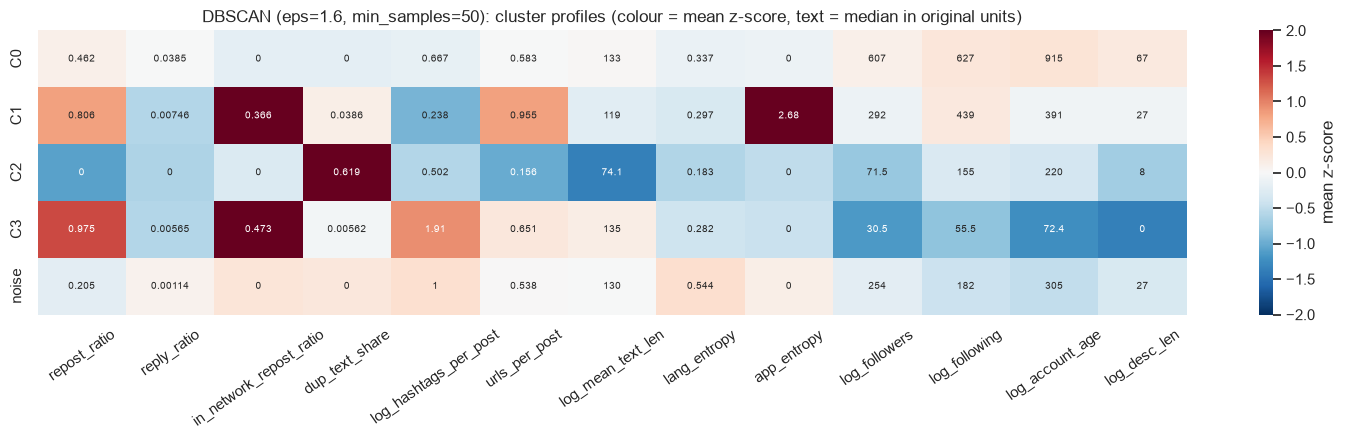

Contingency table DBSCAN clusters x K-means clusters (DBSCAN sample):


K-means,C0,C1,C2,C3,C4
DBSCAN,,,,,
C0,116,6437,4486,1784,0
C1,150,0,1,0,0
C2,0,0,0,0,222
C3,78,0,0,0,0
noise,705,1486,1768,2390,376


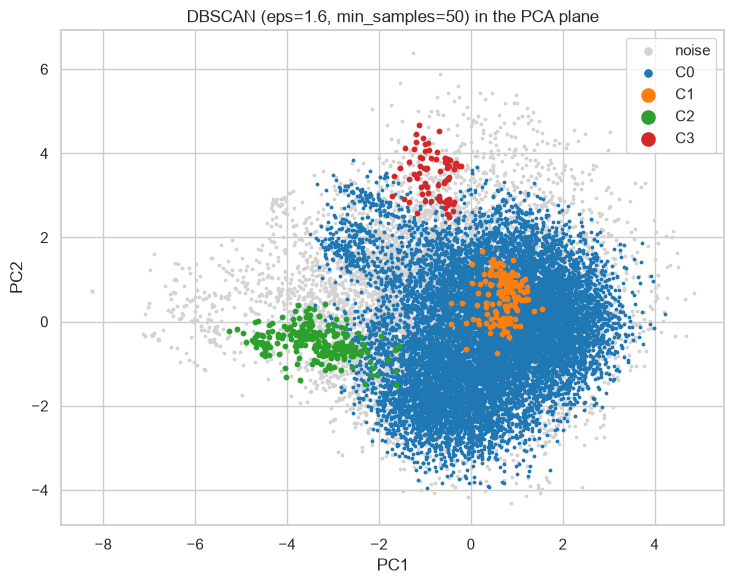

In [41]:
DB_EPS, DB_MIN_SAMPLES = 1.6, 50
labels_db_sample = DBSCAN(eps=DB_EPS, min_samples=DB_MIN_SAMPLES).fit_predict(Xd)
labels_db = np.full(len(data), -2)          # -2 = account not in the DBSCAN sample
labels_db[db_idx] = labels_db_sample

# Summary and profiles computed on the DBSCAN sample (db_idx = positions in `data`)
db_name = f'DBSCAN (eps={DB_EPS}, min_samples={DB_MIN_SAMPLES})'
db_summary = cluster_summary(labels_db_sample, db_name, idx=db_idx)
display(db_summary)
cluster_profile_heatmap(labels_db_sample, db_name, idx=db_idx)
plt.tight_layout()
plt.show()
db_vs_km = pd.crosstab(_cluster_names(labels_db_sample).rename('DBSCAN'),
                       _cluster_names(labels_km[db_idx]).rename('K-means'))
print('Contingency table DBSCAN clusters x K-means clusters (DBSCAN sample):')
display(db_vs_km)

fig, ax = plt.subplots(figsize=(7.5, 6))
xy = X_pca[db_idx]
for c in sorted(set(labels_db_sample)):
    m = labels_db_sample == c
    ax.scatter(xy[m, 0], xy[m, 1], s=3 if c <= 0 else 10, c='lightgrey' if c == -1 else [plt.cm.tab10(c % 10)],
               label='noise' if c == -1 else f'C{c}', zorder=1 if c <= 0 else 3)
ax.set_title(f'DBSCAN (eps={DB_EPS}, min_samples={DB_MIN_SAMPLES}) in the PCA plane')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

**Interpretation of the DBSCAN clusters** (20,000-account sample, 14.7% IO):

| Cluster | Size | % IO | Profile |
|---|---|---|---|
| C0 | 64% | 9% | the dense **core of ordinary behaviour**: it absorbs K-means clusters C1, C2 and most of C3 (see the contingency table), i.e. DBSCAN sees them as one continuous dense region |
| C1 | 151 | **100%** (all Russia) | reposting accounts (≈80% reposts, ≈37% of posts reposting accounts of the same operation) that use **many different clients** (app entropy ≈ 2.7 bits, the highest of all clusters): a coordinated retweet network operated through many applications – a dense core inside K-means C0 |
| C2 | 222 | **99%** (Russia) | **copy-paste broadcasters**: ≈60% duplicated texts, no reposts, short texts, no biography – the dense core of K-means C4 (all 222 accounts are in K-means C4) |
| C3 | 78 | **96%** (UAE) | a **retweet farm**: very young accounts (≈2 months), ≈30 followers, no biography, ≈98% reposts with ≈47% in-network reposts and ≈2 hashtags per post |
| noise | 34% | 20% | accounts in sparse regions: younger, more multilingual and following fewer accounts than the core |

* The key result is that **every dense region outside the core is almost purely IO**: coordinated accounts are
  behaviourally *near-identical* (they are run with the same tools and scripts), which is precisely what a
  density-based method detects. DBSCAN therefore produces the purest IO clusters of all methods.
* The price is coverage: these pure clusters contain only ≈15% of the IO accounts of the sample, while ≈46% of the
  IO accounts are labelled as **noise**. Noise is not "garbage" here: IO accounts are over-represented in it (20%
  vs 14.7%), i.e. many of them have unusual, idiosyncratic profiles that do not belong to any dense group.
* DBSCAN also shows the limits of a single global density threshold: the core is much denser than the IO groups,
  so no value of `eps` can separate the "ordinary" accounts into sub-groups without dissolving the IO groups
  into noise.

## 2.4 Hierarchical (agglomerative) clustering

Agglomerative clustering needs the full $O(n^2)$ distance matrix, so it is run on a random sample of **6,000
accounts** drawn from the DBSCAN sample (the same accounts are used for the final comparison in 2.5). We compare
four linkage criteria with Euclidean distance on the standardised attributes:

* **single** (minimum distance between clusters) – sensitive to chaining;
* **complete** (maximum distance) – compact clusters, sensitive to outliers;
* **average** (UPGMA, mean distance) – a compromise between the two;
* **Ward** (minimum increase of the within-cluster SSE) – the hierarchical analogue of K-means.

For each linkage we compute the **cophenetic correlation** (how faithfully the dendrogram preserves the original
distances) and, cutting the tree into $k = 2..10$ clusters, the silhouette and the size of the largest cluster.

,single,complete,average,ward
cophenetic correlation,0.5680,0.5380,0.6680,0.3450


silhouette                        largest cluster %                         
linkage    average complete single   ward           average complete  single    ward
k                                                                                   
2           0.3880   0.3510 0.5380 0.1110           99.9830  97.2500 99.9830 51.8670
3           0.3090   0.2240 0.3380 0.1160           96.7670  91.3500 99.9670 51.8670
4           0.2930   0.1200 0.3200 0.1050           96.7670  67.6330 99.9500 51.8670
5           0.2480   0.1130 0.2130 0.1190           96.6830  58.5830 99.9330 48.3330
6           0.2430   0.1100 0.1940 0.0970           96.6830  48.0330 99.9170 33.3330
7           0.2320   0.1030 0.1860 0.1020           92.4330  48.0330 99.9000 33.3330
8           0.2020   0.1000 0.1690 0.0980           91.8830  48.0330 99.8830 33.3330
9           0.1670   0.0960 0.1680 0.0860           91.6330  48.0330 99.8670 21.5000
10          0.1530   0.0930 0.1650 0.0850           91.6330  48.0330 99.8500 21.5000

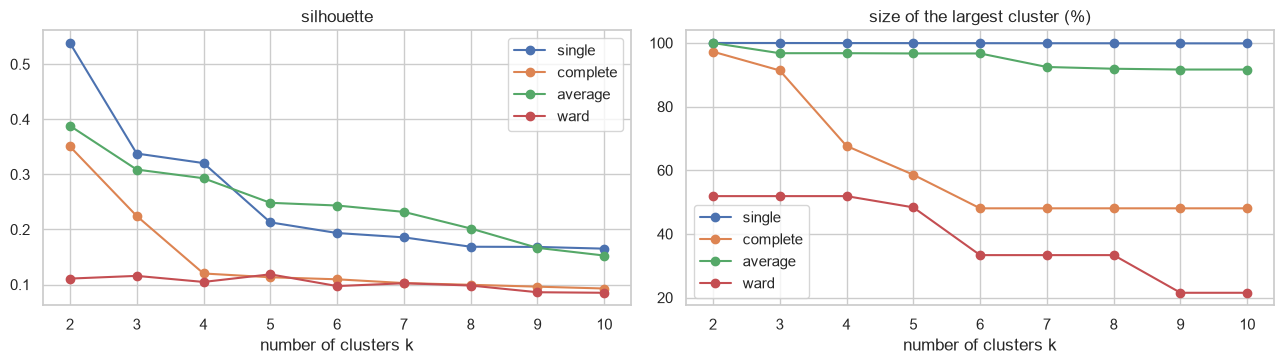

In [42]:
H_N = 6000
h_idx = np.sort(np.random.default_rng(RANDOM_STATE).choice(db_idx, size=H_N, replace=False))
Xh = X[h_idx]
Dh = pdist(Xh)  # condensed Euclidean distance matrix
LINKAGES = ['single', 'complete', 'average', 'ward']
Z, h_rows, coph = {}, [], {}
for method in LINKAGES:
    Z[method] = linkage(Xh, method='ward') if method == 'ward' else linkage(Dh, method=method)
    coph[method] = cophenet(Z[method], Dh)[0]
    for k in range(2, 11):
        lab = fcluster(Z[method], t=k, criterion='maxclust') - 1
        sizes = np.bincount(lab)
        h_rows.append({'linkage': method, 'k': k,
                       'silhouette': silhouette_score(Xh, lab) if len(sizes) > 1 else np.nan,
                       'largest cluster %': 100 * sizes.max() / len(lab),
                       'clusters with < 1% of points': int((sizes < 0.01 * len(lab)).sum())})
h_eval = pd.DataFrame(h_rows)
display(pd.Series(coph, name='cophenetic correlation').to_frame().T.round(3))
display(h_eval.pivot(index='k', columns='linkage', values=['silhouette', 'largest cluster %']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for method in LINKAGES:
    d = h_eval[h_eval['linkage'] == method]
    axes[0].plot(d['k'], d['silhouette'], marker='o', label=method)
    axes[1].plot(d['k'], d['largest cluster %'], marker='o', label=method)
axes[0].set_title('silhouette')
axes[1].set_title('size of the largest cluster (%)')
for ax in axes:
    ax.set_xlabel('number of clusters k')
    ax.legend()
plt.tight_layout()
plt.show()

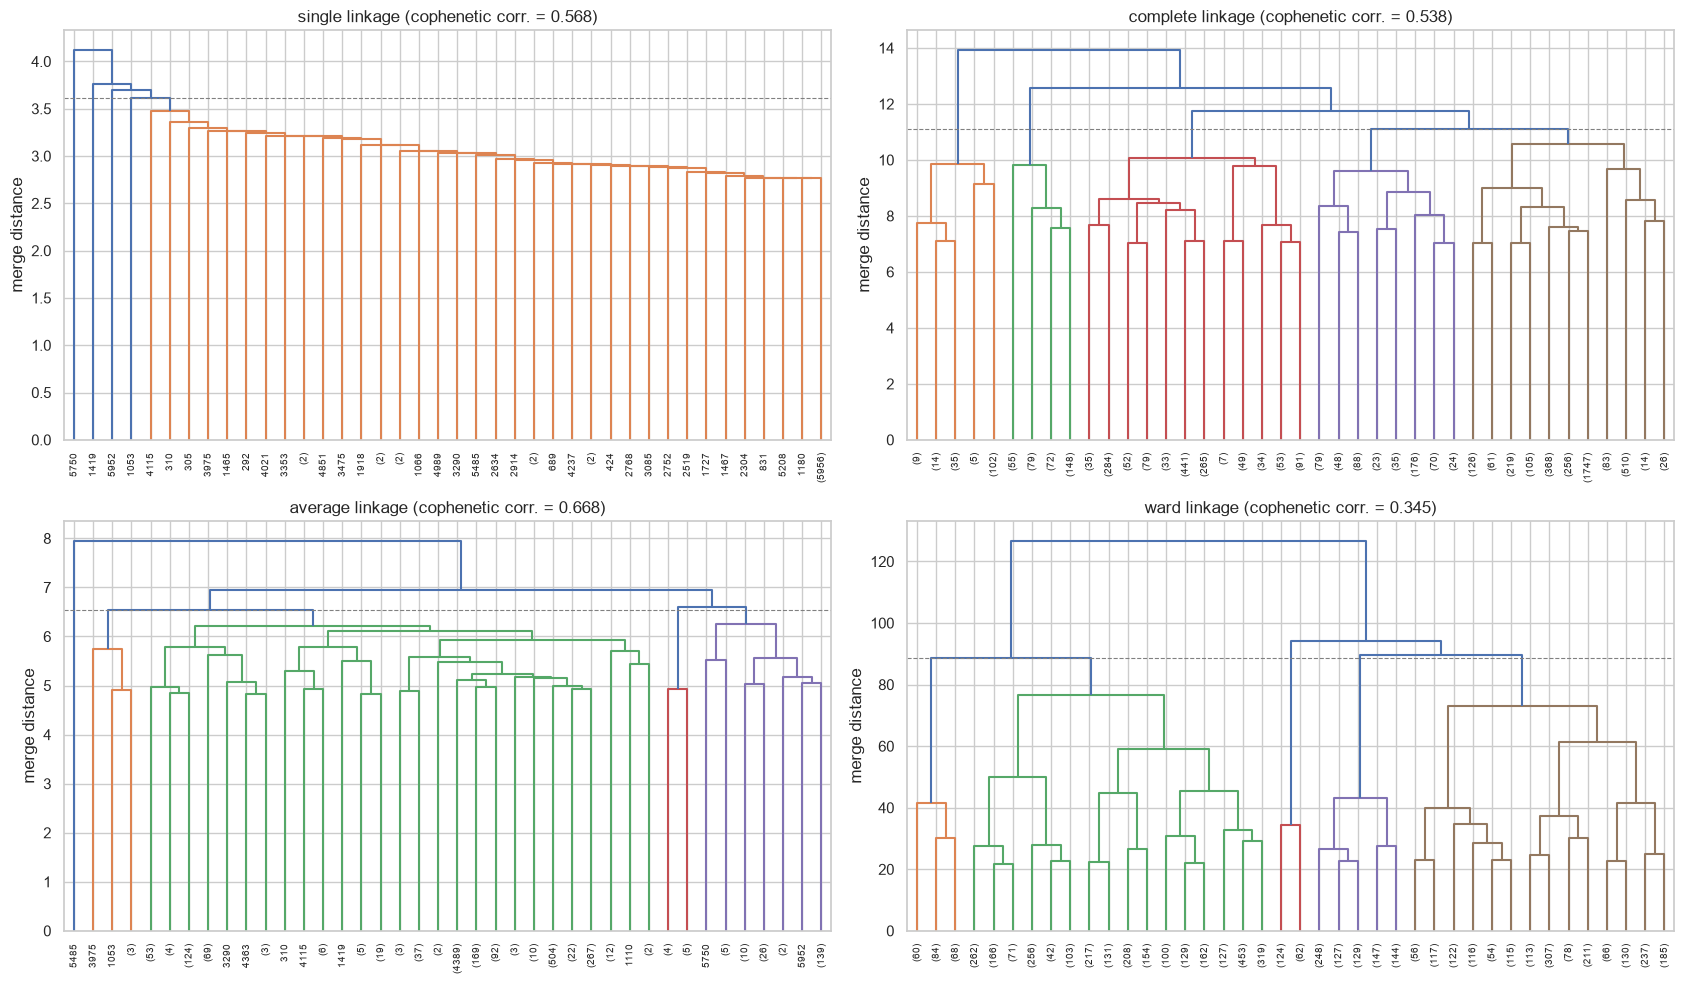

,2,3,4,5,6,7,8,9,10
height gap,32.3600,4.6900,0.9500,12.0400,3.5300,11.6700,2.2600,9.3100,4.5100


In [43]:
# Dendrograms (truncated to the last 40 merges for readability; the number in brackets below a leaf is the number of
# accounts it contains). The single-linkage tree is very deep (chaining), hence the higher recursion limit.
import sys
sys.setrecursionlimit(max(sys.getrecursionlimit(), 20_000))
fig, axes = plt.subplots(2, 2, figsize=(17, 10))
for ax, method in zip(axes.ravel(), LINKAGES):
    cut = Z[method][-(5 - 1), 2] - 1e-9  # height that leaves 5 clusters (colours the 5 top-level subtrees)
    dendrogram(Z[method], truncate_mode='lastp', p=40, ax=ax, show_contracted=False, color_threshold=cut,
               leaf_rotation=90, leaf_font_size=7)
    ax.axhline(cut, color='grey', ls='--', lw=0.8)
    ax.set_title(f'{method} linkage (cophenetic corr. = {coph[method]:.3f})')
    ax.set_ylabel('merge distance')
plt.tight_layout()
plt.show()

# Height gaps of the Ward dendrogram: a large gap before the merge that leaves k-1 clusters suggests cutting at k
ward_h = Z['ward'][:, 2]
gaps = pd.Series({k: ward_h[-(k - 1)] - ward_h[-k] for k in range(2, 11)}, name='height gap')
display(gaps.to_frame().T.round(2))

**Comparison of the linkage criteria.**

* **Single** and **average** linkage produce one giant cluster (> 96% of the accounts for every k ≤ 6) plus a few
  singletons: single linkage suffers from the *chaining* effect, and both isolate outliers one at a time. Their
  relatively high silhouettes only reflect that a few outliers are far from everything else – the partitions are
  useless for profiling.
* **Complete** linkage is less extreme but still unbalanced (the largest cluster holds 59% of the accounts at
  k = 5) and has the lowest silhouettes.
* **Average** linkage has the highest cophenetic correlation (0.67): it preserves the pairwise distances best, but
  since the data contain no clear group structure, a faithful tree is dominated by outliers.
* **Ward** has the lowest cophenetic correlation (0.35) – expected, since it minimises the within-cluster variance
  rather than preserving distances – but it yields balanced and interpretable clusters. Its dendrogram shows the
  largest height gap for k = 2 and the second largest for **k = 5**, which is also the cut with the highest Ward
  silhouette for k ≥ 3. We therefore cut the Ward tree at **k = 5** (the same k as K-means, which also eases the
  comparison).

Cluster sizes (sorted) when every dendrogram is cut into k = 5 clusters:


,#1,#2,#3,#4,#5
single,5996,1,1,1,1
complete,3515,1423,543,354,165
average,5801,184,9,5,1
ward,2900,1907,795,212,186


Hierarchical Ward (k=5): 5 clusters


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts
C0,212,3.5000,67.5000,33.0000,3.8000,1.4000,33.5000,28.3000,16.3000
C1,2900,48.3000,4.4000,31.8000,8.1000,13.1000,29.0000,18.0000,14.4000
C2,186,3.1000,69.9000,14.0000,1.1000,3.8000,74.7000,6.5000,14.8000
C3,795,13.2000,6.7000,22.1000,4.4000,11.3000,49.1000,13.1000,6.0000
C4,1907,31.8000,22.3000,13.9000,6.8000,11.9000,49.6000,17.9000,48.5000


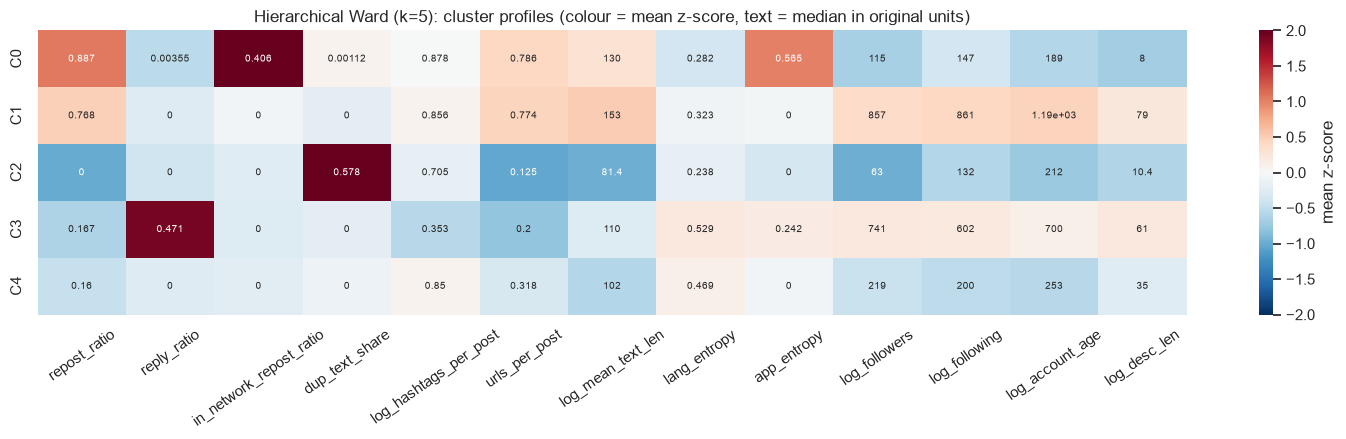

Contingency table Ward clusters x K-means clusters (hierarchical sample):


K-means,C0,C1,C2,C3,C4
Ward,,,,,
C0,198,0,0,13,1
C1,82,2225,347,246,0
C2,0,0,15,17,154
C3,2,26,728,39,0
C4,14,184,818,884,7


In [44]:
H_K = 5
labels_h = {m: fcluster(Z[m], t=H_K, criterion='maxclust') - 1 for m in LINKAGES}
sizes_tab = pd.DataFrame({m: pd.Series(np.sort(np.bincount(l))[::-1]) for m, l in labels_h.items()}).fillna(0).astype(int)
sizes_tab.index = [f'#{i + 1}' for i in range(len(sizes_tab))]
print(f'Cluster sizes (sorted) when every dendrogram is cut into k = {H_K} clusters:')
display(sizes_tab.T)

labels_ward = labels_h['ward']
ward_name = f'Hierarchical Ward (k={H_K})'
display(cluster_summary(labels_ward, ward_name, idx=h_idx))
cluster_profile_heatmap(labels_ward, ward_name, idx=h_idx)
plt.tight_layout()
plt.show()
print('Contingency table Ward clusters x K-means clusters (hierarchical sample):')
display(pd.crosstab(_cluster_names(labels_ward).rename('Ward'), _cluster_names(labels_km[h_idx]).rename('K-means')))

**Interpretation of the Ward clusters** (6,000-account sample):

| Cluster | Size | % IO | Profile | K-means counterpart |
|---|---|---|---|---|
| C1 | 48% | 4% | established organic users: old accounts (≈3 years), ≈860 followers, complete biographies, repost-oriented | C1 |
| C3 | 13% | 7% | conversational users: ≈47% of posts are replies, multilingual | core of C2 |
| C4 | 32% | 22% (**49% of all IO accounts**) | low-profile young accounts with few followers and short biographies | C3 + part of C2 |
| C0 | 3.5% | **68%** | network amplifiers: ≈80% reposts, ≈40% in-network reposts, several clients | C0 |
| C2 | 3.1% | **70%** (75% Russia) | copy-paste broadcasters: ≈58% duplicated texts, no reposts, short texts | C4 |

Ward and K-means agree well (ARI ≈ 0.41, the highest agreement between any two methods): both IO-dominated groups
(amplifiers and copy-paste broadcasters) are recovered by both algorithms, which makes them **robust findings**.
The two methods differ mainly in how they split the large mass of ordinary accounts (conversational vs low-profile).

## 2.5 Comparison of the clustering solutions

All solutions are compared on the **same 6,000 accounts** of the hierarchical sample (K-means labels come from the
model trained on all accounts, DBSCAN labels from the model trained on the 20,000-account sample). We use:

* **internal measures** – silhouette (↑), Davies-Bouldin (↓), Calinski-Harabasz (↑), computed without DBSCAN noise;
* **external measures** w.r.t. information that was *not* used for clustering – Adjusted Rand Index (ARI) and
  Normalised Mutual Information (NMI) with the class (IO vs control) and NMI with the operation; plus the share of
  IO accounts falling in IO-majority clusters and the purity of the most IO-dominated cluster;
* the **agreement between methods** (pairwise ARI).

,n clusters,noise %,silhouette,davies_bouldin,calinski_harabasz,ARI class,NMI class,NMI operation,% IO in IO-majority clusters,max % IO of a cluster (>=1% size)
K-means (k=5),5.0000,0.0000,0.1560,1.7000,753.3780,0.0920,0.0850,0.0390,12.9690,70.3700
"DBSCAN (eps=1.6, ms=50)",4.0000,32.3830,0.3250,0.7400,181.1040,0.1210,0.0930,0.0250,15.2450,98.5290
Ward (k=5),5.0000,0.0000,0.1190,1.9760,555.2610,0.1080,0.1070,0.0310,31.0580,69.8920
Average linkage (k=5),5.0000,0.0000,0.2480,1.0820,121.5960,0.1690,0.0900,0.0110,14.7900,70.6520
Complete linkage (k=5),5.0000,0.0000,0.1130,2.0340,489.1220,0.0990,0.0640,0.0270,13.4240,71.5150


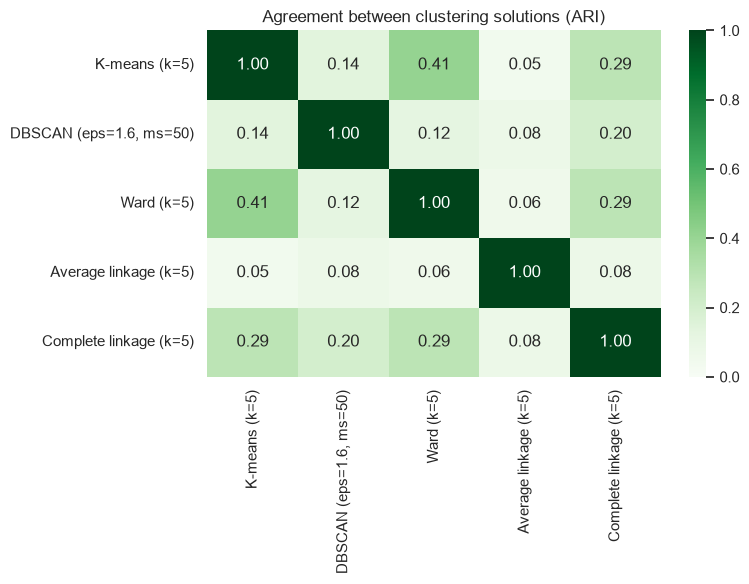

In [45]:
methods = {
    f'K-means (k={K_BEST})': labels_km[h_idx],
    f'DBSCAN (eps={DB_EPS}, ms={DB_MIN_SAMPLES})': labels_db[h_idx],
    f'Ward (k={H_K})': labels_ward,
    f'Average linkage (k={H_K})': labels_h['average'],
    f'Complete linkage (k={H_K})': labels_h['complete'],
}
y_class = data.iloc[h_idx]['class'].eq('IO').to_numpy().astype(int)
y_op = data.iloc[h_idx]['ioCountry'].cat.codes.to_numpy()


def compare_row(lab):
    lab = np.asarray(lab)
    sc = internal_scores(Xh, lab)
    s = pd.DataFrame({'lab': lab, 'io': y_class})
    s_nn = s[s['lab'] != -1]
    io_share = s_nn.groupby('lab')['io'].mean()
    big = s_nn['lab'].value_counts()
    big = big[big >= 0.01 * len(s)].index  # clusters with at least 1% of the accounts
    return {'n clusters': int(len(set(lab)) - (-1 in lab)), 'noise %': 100 * (lab == -1).mean(), **sc,
            'ARI class': adjusted_rand_score(y_class, lab), 'NMI class': normalized_mutual_info_score(y_class, lab),
            'NMI operation': normalized_mutual_info_score(y_op, lab),
            '% IO in IO-majority clusters': 100 * s_nn['io'][s_nn['lab'].map(io_share) > 0.5].sum() / s['io'].sum(),
            'max % IO of a cluster (>=1% size)': 100 * io_share[big].max()}


comparison = pd.DataFrame({name: compare_row(lab) for name, lab in methods.items()}).T
display(comparison.round(3))

ari = pd.DataFrame(index=methods, columns=methods, dtype=float)
for a in methods:
    for b in methods:
        ari.loc[a, b] = adjusted_rand_score(methods[a], methods[b])
plt.figure(figsize=(8, 6))
sns.heatmap(ari, annot=True, fmt='.2f', cmap='Greens', vmin=0, vmax=1)
plt.title('Agreement between clustering solutions (ARI)')
plt.tight_layout()
plt.show()

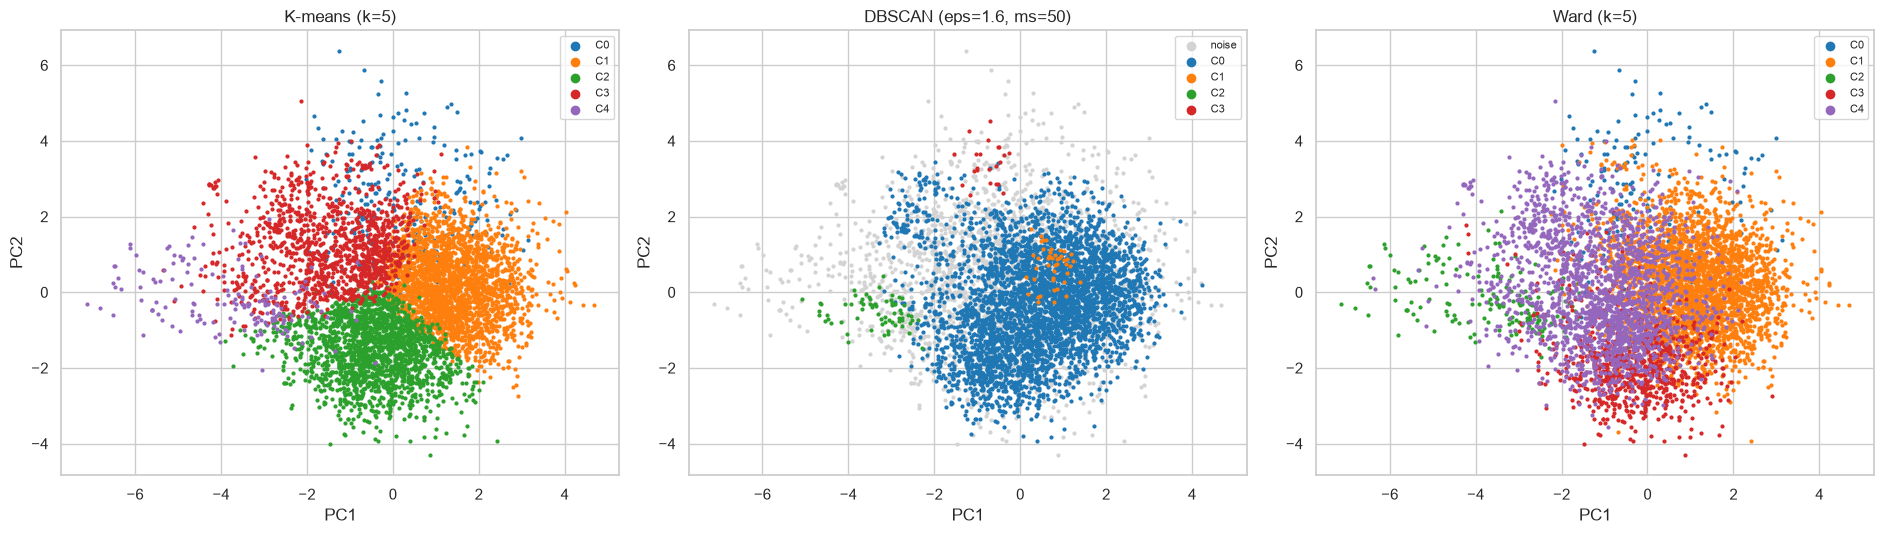

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
xy = X_pca[h_idx]
for ax, (name, lab) in zip(axes, list(methods.items())[:3]):
    for c in sorted(set(lab)):
        m = lab == c
        ax.scatter(xy[m, 0], xy[m, 1], s=4, c='lightgrey' if c == -1 else [plt.cm.tab10(c % 10)],
                   label='noise' if c == -1 else f'C{c}')
    ax.set_title(name)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

**Quantitative comparison.**

* Internal measures favour **DBSCAN** (silhouette ≈ 0.33, Davies-Bouldin ≈ 0.74), but they are computed on the ≈68%
  of accounts that are not noise and on a solution dominated by one big cluster. Among the methods that assign
  every account, **K-means** has the best silhouette / DB / CH (it directly optimises compactness), followed by Ward;
  the good silhouette of average linkage only comes from the isolation of a few outliers.
* **No method reproduces the IO/control label** (ARI 0.09–0.17, NMI ≤ 0.11) **nor the operation** (NMI ≤ 0.04):
  the clusters describe behavioural styles that cut across both. This is expected – IO accounts follow several
  strategies, and many control accounts share the low-profile traits of fake accounts.
* Concentration of IO accounts: DBSCAN finds the purest IO clusters (up to ≈99% IO) but covers few IO accounts;
  Ward puts the largest share of IO accounts in IO-majority clusters (≈31%), K-means ≈13%.
* Agreement: K-means and Ward are the most similar solutions (ARI ≈ 0.41), complete linkage agrees moderately with
  both (≈0.29); DBSCAN and average linkage agree little with the others because their partitions are dominated
  by one giant cluster.

**Strengths and limitations.**

| Method | Strengths | Limitations (observed here) |
|---|---|---|
| K-means | scales to all 68k accounts; centroids are directly interpretable; best compactness | k must be chosen and no clear k exists (flat SSE, low silhouette); assumes convex, similarly sized clusters; sensitive to outliers (mitigated by log + winsorisation); partitions a continuum somewhat arbitrarily |
| DBSCAN | finds arbitrarily shaped dense groups and an explicit noise class; isolates near-identical coordinated accounts with very high purity | very sensitive to `eps` / `min_samples`; one global density threshold for regions of very different density (giant core vs small IO groups); memory-hungry neighbourhood queries → sample; Euclidean distances lose contrast in 13 dimensions |
| Hierarchical | no k needed a priori; the dendrogram gives a multi-scale view; Ward gives results consistent with K-means | the linkage is crucial (single/average degenerate into one cluster + outliers); $O(n^2)$ memory and time → only a 6k sample; greedy merges cannot be undone |

**Robust findings across methods.** Two IO-dominated behavioural profiles – **network amplifiers** (coordinated
in-network reposting, many clients) and **copy-paste broadcasters** (verbatim duplicated content, no reposts) – are
found by K-means, Ward and DBSCAN (DBSCAN in an even purer form, revealing also a UAE retweet farm). The remaining
IO accounts blend with control accounts in a group of **low-profile young accounts** (few followers, empty
biographies), where behaviour alone does not separate IO from genuine newcomers.

## 2.6 Optional: additional clustering techniques – X-means and Gaussian Mixture Models

**X-means** (Pelleg & Moore, 2000; implementation of the `pyclustering` library suggested in the assignment)
extends K-means by recursively trying to split every cluster in two and keeping a split only if it improves a
model-selection criterion; it therefore **estimates the number of clusters by itself**. We test the two criteria
offered by `pyclustering`: the Bayesian Information Criterion (BIC) and the Minimum Noiseless Description Length
(MNDL), allowing up to 20 clusters and repeating the run with 5 different k-means++ initialisations.

**Gaussian Mixture Models** (scikit-learn) are a probabilistic generalisation of K-means: each cluster is a
multivariate Gaussian with its own covariance matrix (elliptical clusters of different shapes, sizes and
orientations), the number of components is chosen with BIC, and every account receives a *soft* membership
probability.

*Technical note*: `pyclustering` 0.10.1.2 still uses `numpy.warnings`, removed in NumPy 2, so we restore that alias
before importing it, and we use its pure-Python implementation (`ccore=False`).

In [47]:
np.warnings = warnings  # compatibility shim for pyclustering with NumPy >= 2
from pyclustering.cluster.xmeans import xmeans, splitting_type
from pyclustering.cluster.center_initializer import kmeans_plusplus_initializer

XM_CRITERIA = {'BIC': splitting_type.BAYESIAN_INFORMATION_CRITERION,
               'MNDL': splitting_type.MINIMUM_NOISELESS_DESCRIPTION_LENGTH}
xm_rows, xm_labels = [], {}
for crit_name, crit in XM_CRITERIA.items():
    for seed in range(5):  # X-means depends on the initial centres: check the stability of the estimated k
        init = kmeans_plusplus_initializer(X, 2, random_state=seed).initialize()
        xm = xmeans(X, init, kmax=20, ccore=False, random_state=seed, criterion=crit)
        xm.process()
        lab = np.empty(len(X), dtype=int)
        for c, members in enumerate(xm.get_clusters()):
            lab[members] = c
        xm_labels[(crit_name, seed)] = lab
        xm_rows.append({'criterion': crit_name, 'seed': seed, 'k found': len(xm.get_clusters()),
                        'ARI with K-means (k=5)': adjusted_rand_score(labels_km, lab),
                        'ARI with class': adjusted_rand_score(data['class'].eq('IO'), lab)})
xm_eval = pd.DataFrame(xm_rows).set_index(['criterion', 'seed'])
display(xm_eval.round(3))

k found  ARI with K-means (k=5)  ARI with class
criterion seed                                                 
BIC       0          20                  0.1780          0.0200
          1          20                  0.1760          0.0220
          2          20                  0.1760          0.0220
          3          20                  0.1730          0.0190
          4          20                  0.1730          0.0210
MNDL      0           2                  0.4190          0.0460
          1           2                  0.4010          0.0560
          2           2                  0.4000          0.0570
          3           2                  0.0530          0.1540
          4           2                  0.4000          0.0570

X-means BIC (k=20): 20 clusters


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts
C0,3430,5.1000,3.8000,19.6000,3.4000,3.5000,65.4000,8.2000,1.3000
C1,2804,4.1000,12.6000,16.6000,4.4000,11.0000,59.4000,8.7000,3.5000
C2,6109,9.0000,10.7000,19.1000,4.9000,13.1000,52.1000,10.9000,6.5000
C3,6992,10.3000,3.9000,35.9000,6.7000,16.1000,20.2000,21.1000,2.8000
C4,6025,8.9000,0.9000,39.4000,7.8000,16.0000,19.5000,17.3000,0.5000
C5,3821,5.6000,1.9000,24.8000,9.3000,12.3000,37.5000,16.1000,0.7000
C6,3250,4.8000,9.2000,18.0000,4.3000,13.6000,51.8000,12.3000,3.0000
C7,958,1.4000,64.3000,4.0000,0.6000,11.4000,71.9000,12.1000,6.2000
C8,801,1.2000,72.0000,5.2000,1.6000,1.1000,90.5000,1.5000,5.8000
C9,3048,4.5000,36.5000,7.8000,1.9000,22.4000,51.8000,16.1000,11.1000


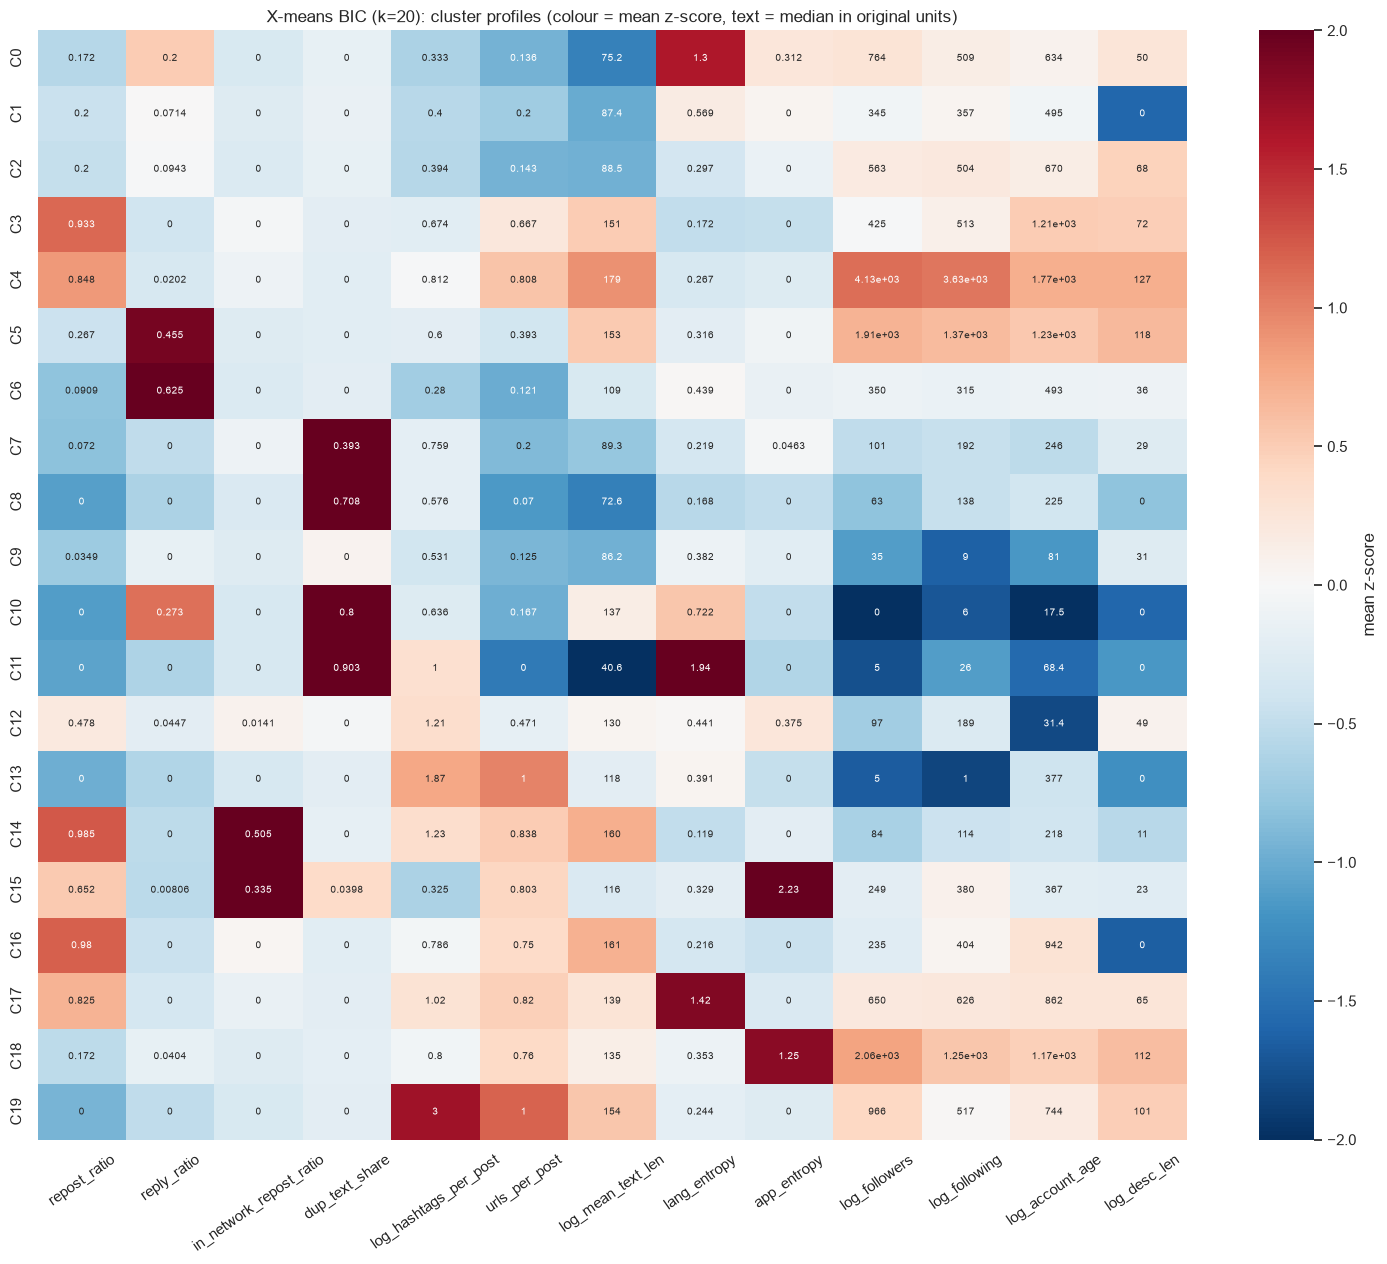

X-means MNDL (k=2): 2 clusters


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts
C0,30927,45.6000,23.5000,14.4000,4.1000,11.2000,55.2000,15.3000,72.7000
C1,36968,54.4000,7.4000,32.3000,8.4000,12.0000,29.4000,17.9000,27.3000


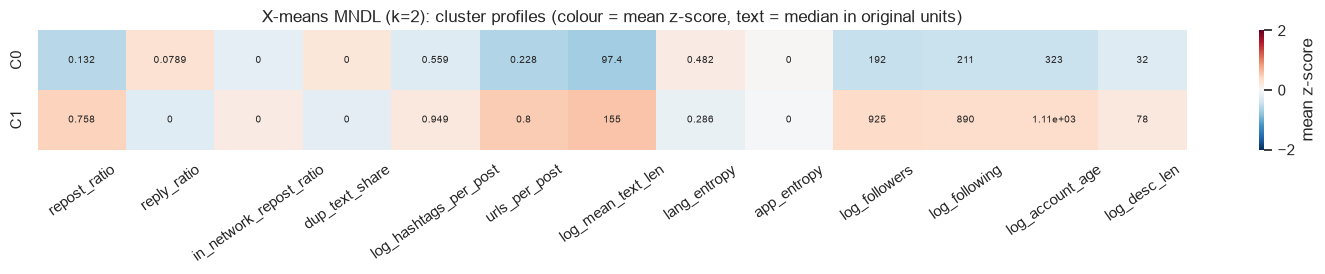

In [48]:
labels_xm = xm_labels[('BIC', 0)]
xm_name = f'X-means BIC (k={len(set(labels_xm))})'
xm_summary = cluster_summary(labels_xm, xm_name)
display(xm_summary)
cluster_profile_heatmap(labels_xm, xm_name)
plt.tight_layout()
plt.show()

labels_xm_mndl = xm_labels[('MNDL', 0)]
xm_mndl_name = f'X-means MNDL (k={len(set(labels_xm_mndl))})'
display(cluster_summary(labels_xm_mndl, xm_mndl_name))
cluster_profile_heatmap(labels_xm_mndl, xm_mndl_name)
plt.tight_layout()
plt.show()

**Gaussian Mixture Models.** Several attributes have a point mass at 0 (e.g. most accounts have no duplicated
texts, no in-network reposts or a single client), which makes some covariance matrices almost singular: without
regularisation the likelihood (and therefore BIC) becomes erratic, with components collapsing on those point masses.
We therefore add a small ridge (`reg_covar = 1e-3`, on standardised data) to the diagonal of every covariance
matrix and compare full and diagonal covariances for $k = 2..12$.

covariance,diag,full,full: BIC decrease vs k-1
k,,,
2,"1,913,866.0000","1,717,134.0000",NaN
3,"1,768,034.0000","1,591,259.0000","125,875.0000"
4,"1,629,740.0000","1,465,061.0000","126,198.0000"
5,"1,587,008.0000","1,430,800.0000","34,262.0000"
6,"1,496,332.0000","1,353,432.0000","77,367.0000"
7,"1,419,631.0000","1,291,075.0000","62,357.0000"
8,"1,384,403.0000","1,294,719.0000","-3,644.0000"
9,"1,391,457.0000","1,235,100.0000","59,619.0000"
10,"1,337,414.0000","1,212,397.0000","22,703.0000"


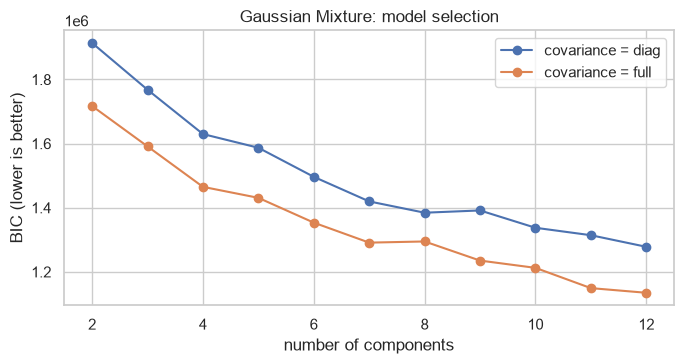

In [49]:
GMM_K = range(2, 13)
gmm_rows, gmm_models = [], {}
for cov in ['diag', 'full']:
    for k in GMM_K:
        gm = GaussianMixture(n_components=k, covariance_type=cov, reg_covar=1e-3, n_init=1,
                             random_state=RANDOM_STATE).fit(X)
        gmm_models[(cov, k)] = gm
        gmm_rows.append({'covariance': cov, 'k': k, 'BIC': gm.bic(X)})
gmm_eval = pd.DataFrame(gmm_rows)
gmm_bic = gmm_eval.pivot(index='k', columns='covariance', values='BIC')
gmm_bic['full: BIC decrease vs k-1'] = -gmm_bic['full'].diff()
display(gmm_bic.round(0))
fig, ax = plt.subplots(figsize=(7, 3.8))
for cov in ['diag', 'full']:
    ax.plot(gmm_bic.index, gmm_bic[cov], marker='o', label=f'covariance = {cov}')
ax.set_xlabel('number of components')
ax.set_ylabel('BIC (lower is better)')
ax.legend()
ax.set_title('Gaussian Mixture: model selection')
plt.tight_layout()
plt.show()

Even with regularisation, BIC keeps decreasing (almost monotonically) up to 12 components for both covariance types:
with ≈68k accounts the BIC penalty is small compared with the likelihood gain of every extra component, so BIC does
not identify a minimum. Full covariances are always clearly better than diagonal ones (the attributes are
correlated). We therefore pick the **elbow of the full-covariance curve**: the BIC decrease is ≈126k when moving to
3 and to 4 components, but only ≈34k from 4 to 5 → **k = 4**.

GMM (full covariance, k=4): 4 clusters


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts
C0,11445,16.9000,13.1000,44.1000,5.0000,9.8000,20.0000,21.0000,15.0000
C1,22228,32.7000,4.5000,22.3000,8.3000,11.3000,44.3000,13.9000,9.9000
C2,10452,15.4000,60.6000,10.2000,1.8000,14.0000,47.6000,26.4000,63.3000
C3,23770,35.0000,4.9000,22.4000,7.4000,11.8000,45.5000,12.9000,11.7000


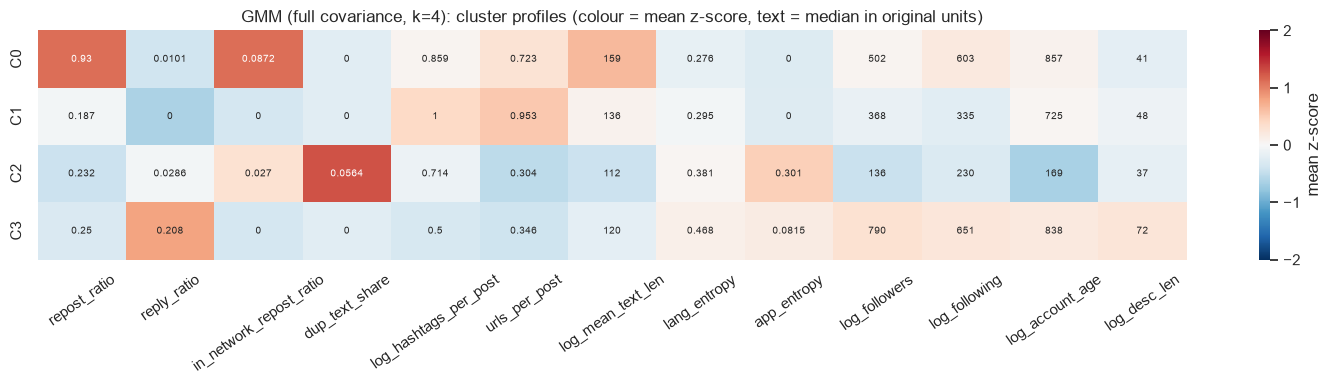

,max posterior,uncertain (p < 0.8)
class,,
IO,0.9760,0.0470
Control,0.9630,0.0680


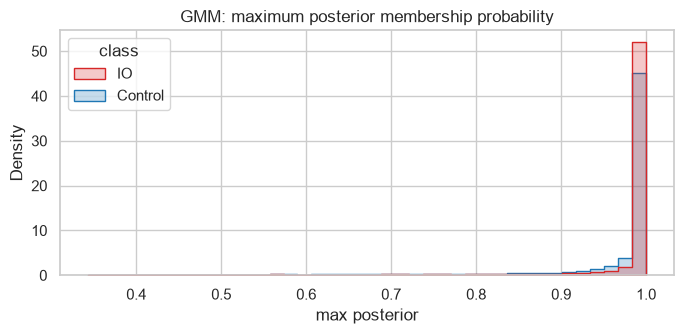

In [50]:
GMM_COV, GMM_BEST_K = 'full', 4
gmm = gmm_models[(GMM_COV, GMM_BEST_K)]
labels_gmm = gmm.predict(X)
proba = gmm.predict_proba(X).max(axis=1)
gmm_name = f'GMM ({GMM_COV} covariance, k={GMM_BEST_K})'
display(cluster_summary(labels_gmm, gmm_name))
cluster_profile_heatmap(labels_gmm, gmm_name)
plt.tight_layout()
plt.show()

# Soft assignments: how confident is the model, and are IO accounts more often "between" clusters?
conf = pd.DataFrame({'max posterior': proba, 'class': data['class']})
conf['uncertain (p < 0.8)'] = conf['max posterior'] < 0.8
display(conf.groupby('class', observed=True)[['max posterior', 'uncertain (p < 0.8)']].mean().round(3))
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=conf, x='max posterior', hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER,
             stat='density', common_norm=False, bins=40, element='step', ax=ax)
ax.set_title('GMM: maximum posterior membership probability')
plt.tight_layout()
plt.show()

In [51]:
# Final comparison including the optional methods (on the common hierarchical sample)
methods_ext = dict(methods)
methods_ext[xm_name] = labels_xm[h_idx]
methods_ext[xm_mndl_name] = labels_xm_mndl[h_idx]
methods_ext[gmm_name] = labels_gmm[h_idx]
comparison_ext = pd.DataFrame({name: compare_row(lab) for name, lab in methods_ext.items()}).T
display(comparison_ext.round(3))
print('ARI with K-means on all accounts:',
      {name: round(adjusted_rand_score(labels_km, lab), 3)
       for name, lab in [(xm_name, labels_xm), (xm_mndl_name, labels_xm_mndl), (gmm_name, labels_gmm)]})

,n clusters,noise %,silhouette,davies_bouldin,calinski_harabasz,ARI class,NMI class,NMI operation,% IO in IO-majority clusters,max % IO of a cluster (>=1% size)
K-means (k=5),5.0000,0.0000,0.1560,1.7000,753.3780,0.0920,0.0850,0.0390,12.9690,70.3700
"DBSCAN (eps=1.6, ms=50)",4.0000,32.3830,0.3250,0.7400,181.1040,0.1210,0.0930,0.0250,15.2450,98.5290
Ward (k=5),5.0000,0.0000,0.1190,1.9760,555.2610,0.1080,0.1070,0.0310,31.0580,69.8920
Average linkage (k=5),5.0000,0.0000,0.2480,1.0820,121.5960,0.1690,0.0900,0.0110,14.7900,70.6520
Complete linkage (k=5),5.0000,0.0000,0.1130,2.0340,489.1220,0.0990,0.0640,0.0270,13.4240,71.5150
X-means BIC (k=20),20.0000,0.0000,0.1130,1.7710,402.2170,0.0210,0.0870,0.0580,51.7630,87.2090
X-means MNDL (k=2),2.0000,0.0000,0.1370,2.4250,910.7010,0.0480,0.0490,0.0370,0.0000,23.5960
"GMM (full covariance, k=4)",4.0000,0.0000,0.0540,2.9740,361.9630,0.1090,0.1420,0.0330,63.5950,62.0420


ARI with K-means on all accounts: {'X-means BIC (k=20)': 0.178, 'X-means MNDL (k=2)': 0.419, 'GMM (full covariance, k=4)': 0.181}


**Do the additional techniques provide new insights?**

*X-means.*

* With **BIC**, X-means keeps splitting until the maximum allowed number of clusters (20) for every initialisation:
  with ≈68k points the BIC penalty is weak and every split of the continuum "improves" the fit. With **MNDL** it
  always stops at **k = 2**. The two criteria disagree completely, which confirms – together with the flat SSE
  curve and the low silhouettes – that the account space has **no natural number of clusters**.
* The MNDL split is a coarse division between established, repost-oriented accounts with large audiences (C1) and
  younger, less followed accounts producing short original content (C0, which holds 73% of the IO accounts but is
  only 23% IO); it is also unstable across initialisations (ARI with K-means ≈ 0.40 for four seeds, 0.05 for one).
* The fine-grained BIC solution, instead, isolates **operation-specific IO groups** that are invisible at k = 5:
  e.g. C10 (≈300 accounts, 93% IO, 91% Ecuador), C15 (≈1,000 accounts, 93% IO, 83% Russia), C8 (≈800 accounts,
  72% IO, 91% Russia) and C12 (≈4,700 accounts, 59% IO, half of them UAE, holding 28% of all IO accounts). Half of
  the IO accounts (52%) fall in IO-majority clusters, against 13% for K-means: each operation uses its own
  behavioural "template", which only emerges at a finer granularity.

*Gaussian Mixture Model.*

* The 4-component GMM is the solution that **best concentrates the IO accounts**: component C2 (15% of the
  accounts, 61% IO) contains **63% of all IO accounts**, and the GMM has the highest NMI with the class among all
  methods. This component gathers young, little-followed accounts with **non-zero values of the coordination
  indicators** (duplicated texts, in-network reposts, several publishing clients), whereas the other components
  have these indicators exactly at zero.
* This is a genuinely new insight: thanks to per-component covariance matrices, the GMM can model the
  *zero-inflated* distributions of the coordination attributes (components with almost no variance on them) and
  separates accounts that show **any** coordination signal from accounts that show none. Euclidean, centroid-based
  methods (K-means, Ward) cannot do this, because a small duplicated share is only a small distance for them.
* Its internal scores are poor (silhouette ≈ 0.05), since overlapping elliptical components are not what the
  silhouette rewards – another reason not to rely on internal indices alone.
* Soft memberships are confident for both classes (mean maximum posterior ≈ 0.97; only 5–7% of the accounts have
  p < 0.8), so IO accounts are not more often "between" clusters than control accounts.

**Overall conclusion of Task 2.** Behavioural profiles of IO and control accounts largely overlap and form a
continuum, so no clustering recovers the class. Nevertheless, all methods agree on a few IO-dominated behaviours –
coordinated in-network amplification and copy-paste broadcasting – which density-based clustering isolates as
almost pure groups of near-identical accounts, X-means refines into operation-specific templates, and the GMM
summarises as "accounts showing any coordination signal". Activity and timing features would have separated
the classes much more strongly, but in this dataset they mainly reflect how the control data were collected.